# 32i quantification — NucSeq dataset (sense / antisense)

NucSeq version of `quantify_32i_SlideTags_revised.ipynb` (same method, same analyses, no spatial part).

Differences w.r.t. the SlideTags notebook:
- libraries **mix donors** (donors demultiplexed upstream) → the BAM of a library is subset to all its called cells, the donor comes from `obs`
- library table = `XDP Flowcell Tracker - freeze2.csv` (`Library`, `BCL`, `RNA Index`), BAM = `gene-expression/{BCL}/{RNA Index}/outs/possorted_genome_bam.bam`
- cell barcode join key = `library_id` (`{bcl}__{Library}`, = obs `library`) + `original_barcode` (BAM `CB` tag)
- `donor_id` in `obs` is the original donor id → mapped to the unified id with `XDP dataset metadata - Gabri's Version.csv`; covariates (age of onset / death, repeat length, disease duration) come from the same csv
- cell type names: `Oligodendrocyte`, `Astrocyte`, ...
- no spatial data → no dead / healthy region section
- strand: as in SlideTags, TAF1 sense reads map on the **reverse** strand in all 16 libraries (also the 10x GEM-X 5' libraries of cohort 2), no paired-end library; orientation is still detected per library

Requires `samtools` + `gcloud` (see install notes in `quantify_32i_NucSeq_manual_code.ipynb`).

In [1]:
import pysam
import h5py
import pandas as pd
from collections import defaultdict
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import subprocess
import numpy as np
from anndata.io import read_elem

In [2]:
TAF1_START_END = "71366357-71466005" # refseq igv
TAF1_START_END_W = "71366000-71467000" # bigger window arounf TAF1 to extrast subset of bam
TAF1_EXON32_START_END = "71424154-71424238" # refseq igv
TAF1_INTRON32_START_END = "71424239-71454169" # refseq igv
TAF1_EXON33_START_END = "71454170-71454237" # refseq igv

EXON32_LAST_BP    = int(TAF1_EXON32_START_END.split("-")[1])
INTRON32_FIRST_BP = int(TAF1_INTRON32_START_END.split("-")[0])
INTRON32_LAST_BP  = int(TAF1_INTRON32_START_END.split("-")[1])
EXON33_START_BP   = int(TAF1_EXON33_START_END.split("-")[0])
EXON33_END_BP     = int(TAF1_EXON33_START_END.split("-")[1])
EXON38_END_BP     = int(TAF1_START_END.split("-")[1])
INTRON_LENGHT     = int(INTRON32_LAST_BP) - int(EXON32_LAST_BP) #29931
SVA_START_BP       = 71440512   # published start of the SVA insertion (= end of "pre" / 32i region)

TAF1_EXON32_INTRON32_JUNCTION_W = f"{int(EXON32_LAST_BP)-9}-{int(INTRON32_FIRST_BP)+9}" # 71424228-71424249

INTRON_LENGHT
TAF1_EXON32_INTRON32_JUNCTION_W

'71424229-71424248'

# NucSeq Data

The libraires mixes samples

In [3]:
TISSUE = "Striatum"

ADATA_PATH      = f"/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/{TISSUE}/{TISSUE}_combined_QC_mmc_ct-cured_zoned.h5ad"
LIB_META_PATH   = "/home/gdallagl/myworkdir/XDP/utils/SlideTags_XDP_metadata/XDP Flowcell Tracker - freeze2.csv"
DONOR_META_PATH = "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/original_data/XDP dataset metadata - Gabri's Version.csv"
BAM_GCS_DIR     = "gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559aa7d36/gene-expression"  # {BCL}/{RNA Index}/outs/possorted_genome_bam.bam
BAM_LOCAL_DIR   = "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/NucSeq_single_libraries"  # {BCL}/{RNA Index}/bam
OUT_DIR         = Path("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/32i")
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET = f"NucSeq_{TISSUE}"

# donors removed from the ANALYSES (pseudobulk onwards), not from the 32i quantification:
# the per-cell csv still has all donors
# unified donor_id or original_donor_id, e.g. ["SCF-18-006"]
EXCLUDE_DONORS = []
# used in output file names and plot titles, so runs with/without exclusion do not overwrite each other
ANALYSIS_NAME = DATASET + ("_excl_" + "_".join(EXCLUDE_DONORS) if EXCLUDE_DONORS else "")

In [4]:
# unified donor id + covariates
df_meta = pd.read_csv(DONOR_META_PATH)
df_meta[["donor_id", "original_donor_id", "Condition"]].drop_duplicates()

,donor_id,original_donor_id,Condition
0,SCF-22-054,SCF-22-054CM,Control
1,SCF-23-075,SCF_23_075CM,Control
2,SCF-22-067,SCF_22_067CM,Control
3,SCF-23-079,SCF_23_079CF,Control
4,SCF-22-065,SCF_22_065CM,Control
5,SCF-23-072,SCF_23_072CF,Control
6,SCF-22-050,SCF_22-050CM6,Control
7,SCF-23-068,SCF-23-068CM,Control
8,SCF-23-074,SCF_23_074CF,Control
9,SCF-22-057,SCF_22-057CM,Control


In [5]:
# Use the barcodes in processed adata
# read only obs / var with h5py (no need to load the matrix)
with h5py.File(ADATA_PATH, "r") as f:
    obs_nuc = read_elem(f["obs"])
    var_nuc = read_elem(f["var"])
obs_nuc["obs_idx"] = np.arange(len(obs_nuc))  # row position in the h5ad, needed later to read TAF1 counts

# remvoe bad quality cells ("-Low_quality", "-TAFA1")
# obs_nuc = obs_nuc[~obs_nuc["ct_for_deg"].astype(str).str.startswith("-")]

# cells not assigned to a donor (no condition)
print("removed, no donor:", obs_nuc["condition"].isna().sum())
obs_nuc = obs_nuc[obs_nuc["condition"].notna()].copy()

# reconstruct original barcode (unique in a single library) -> need to merge with bam file
# barcode = {bcl}__{Library}__{CB}_{tissue}_{donor}
obs_nuc["original_barcode"] = obs_nuc["barcode"].str.split("__").str[2].str.split("_").str[0]
obs_nuc["library_name"] = obs_nuc["barcode"].str.split("__").str[1]   # "Library" in the flowcell tracker
obs_nuc["library_id"] = obs_nuc["library"].astype(str)                # {bcl}__{Library}
assert not obs_nuc.duplicated(["library_id", "original_barcode"]).any()

# merge cell types
obs_nuc["ct_for_deg"] = (
    obs_nuc["ct_for_deg"]
    .astype(str)
    .replace({
        "Matrix_D1": "Matrix",
        "Matrix_D2": "Matrix",
        "Patch_D1": "Patch",
        "Patch_D2": "Patch"
    })
    .astype("category")
)

obs_nuc["condition"] = obs_nuc["condition"].astype(str).astype(pd.CategoricalDtype(["Control", "XDP"]))

# add unified donor id (obs has the original one)
donor_map = df_meta.drop_duplicates("original_donor_id").set_index("original_donor_id")["donor_id"]
obs_nuc["original_donor_id"] = obs_nuc["donor_id"].astype(str)
obs_nuc["donor_id"] = obs_nuc["original_donor_id"].map(donor_map)
assert obs_nuc["donor_id"].notna().all(), obs_nuc.loc[obs_nuc["donor_id"].isna(), "original_donor_id"].unique()

display(obs_nuc)
print("number of donors in obs_nuc:", obs_nuc.groupby("donor_id").ngroups)
display(obs_nuc.groupby(["condition", "cohort"], observed=True)["donor_id"].nunique().rename("n_donors"))

# which libs have been used for the sample in this adata
nucseq_libs = obs_nuc["library_id"].unique().tolist()
len(nucseq_libs)

removed, no donor: 3


,background_fraction,cell_probability,cell_size,droplet_efficiency,barcode,bcl,rna_index,library,library__barcode,frac_mito,...,zone,zone_probability,mapping_coupling_for_zoning_4_zones,zone_4,zone_4_probability,obs_idx,original_barcode,library_name,library_id,original_donor_id
barcode,,,,,,,,,,,,,,,,,,,,,
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGACGTTCATGTGGT-1_Striatum_SCF-20-025,0.002532,0.999955,15523.367188,2.215328,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGACGTT...,A22KHKGLT3,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGACGTT...,0.001974,...,5,0.966,Astrocyte 4 zones,1,0.586,0,CGGACGTTCATGTGGT-1,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,SCF-20-025
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GTAGGCCTCCGTTGTC-1_Striatum_SCF-20-025,0.003941,0.999955,15618.492188,2.163925,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GTAGGCCT...,A22KHKGLT3,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GTAGGCCT...,0.001627,...,4,1.000,Astrocyte 4 zones,1,1.000,1,GTAGGCCTCCGTTGTC-1,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,SCF-20-025
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__TCGGGACTCTCTGTCG-1_Striatum_SCF-22-054CM,0.009691,0.999955,14187.895508,2.199903,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__TCGGGACT...,A22KHKGLT3,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__TCGGGACT...,0.000281,...,6,0.855,Astrocyte 4 zones,2,0.740,2,TCGGGACTCTCTGTCG-1,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,SCF-22-054CM
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGGTCACAAGAGGCT-1_Striatum_SCF-19-009,0.004581,0.999955,13582.982422,2.010379,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGGTCAC...,A22KHKGLT3,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGGTCAC...,0.000040,...,6,0.517,Astrocyte 4 zones,2,0.999,3,CGGGTCACAAGAGGCT-1,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,SCF-19-009
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GGACATTGTAAACCTC-1_Striatum_SCF-22-054CM,0.004263,0.999955,12883.346680,2.069477,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GGACATTG...,A22KHKGLT3,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GGACATTG...,0.000412,...,5,0.993,Astrocyte 4 zones,2,0.951,4,GGACATTGTAAACCTC-1,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,SCF-22-054CM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__CATGAAGCAGGTGCGA-1_Striatum_SCF_22-050CM6,0.436521,0.999990,5263.216797,0.668542,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__CATG...,250328_SL-EXE_0516_A22N2VFLT4,SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__CATG...,0.000000,...,NaN,NaN,NaN,NaN,NaN,231075,CATGAAGCAGGTGCGA-1,SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,SCF_22-050CM6
250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__GTGTTACCAGGCTTCA-1_Striatum_SCF_22-060,0.436829,0.999953,4984.368164,0.725044,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__GTGT...,250328_SL-EXE_0516_A22N2VFLT4,SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__GTGT...,0.000000,...,NaN,NaN,NaN,NaN,NaN,231076,GTGTTACCAGGCTTCA-1,SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,SCF_22-060
250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__ATAGGCACACTAGTTA-1_Striatum_SCF_22-048,0.444862,0.999996,4720.072754,0.779890,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__ATAG...,250328_SL-EXE_0516_A22N2VFLT4,SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12__ATAG...,0.001505,...,NaN,NaN,NaN,NaN,NaN,231077,ATAGGCACACTAGTTA-1,SI-TT-H12,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,SCF_22-048


number of donors in obs_nuc: 47


condition  cohort  
Control    Cohort_1     4
           Cohort_2     8
           Cohort_3     5
XDP        Cohort_1    13
           Cohort_2     7
           Cohort_3    10
Name: n_donors, dtype: int64

16

In [6]:
# read here from where the .bam file are located
df_lib_nuc = pd.read_csv(LIB_META_PATH)
df_lib_nuc["library_id"] = df_lib_nuc["BCL"] + "__" + df_lib_nuc["Library"]

# select only the libraries that are in the nucseq_libs list
df_lib_nuc = df_lib_nuc[df_lib_nuc["library_id"].isin(nucseq_libs)].drop_duplicates("library_id")
assert set(nucseq_libs) == set(df_lib_nuc["library_id"]), set(nucseq_libs) - set(df_lib_nuc["library_id"])

# cohort of each library (from obs)
df_lib_nuc = df_lib_nuc.merge(
    obs_nuc[["library_id", "cohort"]].drop_duplicates("library_id").astype(str), on="library_id", how="left"
)

df_lib_nuc[["library_id", "Library", "BCL", "RNA Index", "cohort"]]

,library_id,Library,BCL,RNA Index,cohort
0,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,pXDPsHSrPuiv1d240321rxn4,A22KHKGLT3,SI-TT-C9,Cohort_1
1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn3,pXDPsHSrPuiv1d240321rxn3,A22KHKGLT3,SI-TT-D9,Cohort_1
2,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn2,pXDPsHSrPuiv1d240321rxn2,A22KHKGLT3,SI-TT-E9,Cohort_1
3,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn1,pXDPsHSrPuiv1d240321rxn1,A22KHKGLT3,SI-TT-F9,Cohort_1
4,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn4,pXDPsHSrCaiv1d240321rxn4,A22KHKGLT3,SI-TT-G9,Cohort_1
5,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn3,pXDPsHSrCaiv1d240321rxn3,A22KHKGLT3,SI-TT-H9,Cohort_1
6,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn2,pXDPsHSrCaiv1d240321rxn2,A22KHKGLT3,SI-TT-A10,Cohort_1
7,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn1,pXDPsHSrCaiv1d240321rxn1,A22KHKGLT3,SI-TT-B10,Cohort_1
8,250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-G...,241218_v2_10X-GEMX-5P_Ca_rxn1,250117_SL-EXL_0041_A22LHCHLT4,SI-TT-F4,Cohort_2
9,250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-G...,241218_v2_10X-GEMX-5P_Ca_rxn2,250117_SL-EXL_0041_A22LHCHLT4,SI-TT-F5,Cohort_2


# Calcualte 32i 

*) Read
- blocks: a block is a tuple (start, end) that tell in the genome where a subset of the read have been aligned
    - ex. a read of a spliced rna will have 2 blocks (i, endexon 1), (start exon 2, j)

- cigartuple: list of (operation, length) (one for each block), that tell how the read bases in that blcok have been aligned

In [7]:
def overlaps_window(read, win_start, win_end):
    # checks whether any aligned block of a read overlaps [win_start, win_end]

    # attetion, need to conver base 0
    win_start0, win_end0 = win_start - 1, win_end - 1
    for block_start, block_end in read.get_blocks():
        if block_start < win_end0 and block_end > win_start0:
            return True
    return False

def has_canonical_splice(read, gap):
    #returns True if the read contains a splice gap of exactly 29,931 bp 
    # the canonical exon32→exon33 intron length
    if read.cigartuples is None:
        return False
    # attention op=3 encode "N" (skipped region from the reference)
    return any(op == 3 and length == gap for op, length in read.cigartuples)

**Strand**: TAF1 is a + strand gene, but in these BAMs TAF1 mRNA reads map on the **reverse** strand (sense = reverse), in all 16 libraries.
No library is paired-end, `fragment_is_reverse` is kept in case (read1 orientation flipped).

In [8]:
PRE_START, PRE_END   = INTRON32_FIRST_BP, SVA_START_BP     # 32i intron pile-up region
POST_START, POST_END = EXON33_START_BP, int(TAF1_START_END.split("-")[1])     # downstream normal transcript
CANONICAL_SPLICE_LEN = EXON33_START_BP - EXON32_LAST_BP - 1   # 29931

# if False, reuse taf1_subset.bam already on disk
# (keep True if the cell list in the adata changed -- old subsets were filtered without the low quality cells)
OVERWRITE_BAM = True

# STRAND
# TAF1 is a + strand gene, but in these BAMs TAF1 mRNA reads map on the REVERSE strand
# (~97-98% of exon33-38 reads are reverse; Cell Ranger tags them GN=TAF1, the forward ones AN=TAF1 = antisense)
# paired-end libraries: read1 and read2 of the same molecule map on opposite strands
# -> read1 orientation is flipped, so every read reports the orientation of read2
# -> do not assume: per library, sense = majority orientation of the reads in the exonic POST window
def fragment_is_reverse(read):
    return read.is_reverse != read.is_read1

per_cell_results = []   # one row per (library, cell)
lib_strand_qc = []      # one row per library, orientation check

for _, row in df_lib_nuc.iterrows():

    # select the library --> so we can take the relative BAM
    library_id, bcl, rna_index = row["library_id"], row["BCL"], row["RNA Index"]
    print(library_id)

    # where to save bam file locally
    save_folder = Path(f"{BAM_LOCAL_DIR}/{bcl}/{rna_index}/bam")
    save_folder.mkdir(parents=True, exist_ok=True)
    subset_bam_path = save_folder / "taf1_subset.bam"
    # where is the file in the cloud (GCP bucket)
    bam = f"{BAM_GCS_DIR}/{bcl}/{rna_index}/outs/possorted_genome_bam.bam"

    # called cells for this library from curated adata (all donors of the library)
    CALLED_CELLS = set(obs_nuc.loc[obs_nuc["library_id"] == library_id, "original_barcode"])
    # save this barcodes (one file per library)
    BC_FILE = save_folder / "called_cells.txt"
    with open(BC_FILE, "w") as f:
        for cell in CALLED_CELLS:
            f.write(f"{cell}\n")

    script = f"""
        set -e

        export GCS_OAUTH_TOKEN=$(gcloud auth print-access-token)

        BAM="{bam}"
        cd "{save_folder}"

        # view --> subset
        # -b --> ouput bam
        # -q 30 --> only reads with MAPQ >= 30
        # -F 0x904 --> exclude unmapped, secondary, supplementary reads
        # -D CB:"{BC_FILE}" --> only reads with CB in the list of barcodes in the file
        # chrX:{TAF1_START_END_W} --> only reads mapping to chrX in the TAF1 region
        samtools view \\
          -b \\
          -q 30 -F 0x904 \\
          -D CB:"{BC_FILE}" \\
          "$BAM" \\
          chrX:{TAF1_START_END_W} \\
          -o taf1_subset.bam
        
        # name .bai
        samtools index taf1_subset.bam
    """

    # Run the scirpt
    # reading from GCS can fail randomly ("Illegal seek") -> retry
    if OVERWRITE_BAM or not subset_bam_path.exists():
        for attempt in range(3):
            proc = subprocess.run(["bash", "-c", script], capture_output=True, text=True)
            if proc.returncode == 0:
                break
            print(f"attempt {attempt + 1} failed: {library_id}\n{proc.stderr}")
        else:
            print(f"FAILED (subset step): {library_id}")
            continue

    # -----------------------------------------------------------------
    # UMI counting, PER CELL -- dict of CB -> set of UMIs
    # -----------------------------------------------------------------

    # create a on obj from the bam file to query
    bam_fh = pysam.AlignmentFile(str(subset_bam_path), "rb") # needs .bai in same folder

    # dict[(window, fragment_is_reverse)][cell] = {set of UMIs} --> set allow deduplication of UMIs
    # orientation is converted to sense/antisense after the POST window tells which one is sense
    umis = {(win, is_rev): defaultdict(set) for win in ("pre", "post") for is_rev in (False, True)}

    # seach for reads falling in PRE
    for read in bam_fh.fetch("chrX", PRE_START, PRE_END):

        # if read in bad qulity, skip it
        if read.is_unmapped or read.is_secondary or read.is_supplementary:
            continue

        # CB = cell barcode, UB = UMI barcode (Tags from cell ranger)
        if not (read.has_tag("CB") and read.has_tag("UB")):
            continue

        #  read have an actual aligned base — not just span — physically inside [PRE_START, PRE_END]
        if not overlaps_window(read, PRE_START, PRE_END):
            continue

        # exclude normal exon32→33 spliced reads that touch the pre-window edge
        if has_canonical_splice(read, gap=CANONICAL_SPLICE_LEN):
            continue  # normal spliced transcript, not 32i pile-up

        umis[("pre", fragment_is_reverse(read))][read.get_tag("CB")].add(read.get_tag("UB"))

    # seach for reads falling in POST (no splice filter)
    for read in bam_fh.fetch("chrX", POST_START, POST_END):
        if read.is_unmapped or read.is_secondary or read.is_supplementary:
            continue
        if not (read.has_tag("CB") and read.has_tag("UB")):
            continue
        if not overlaps_window(read, POST_START, POST_END):
            continue
        umis[("post", fragment_is_reverse(read))][read.get_tag("CB")].add(read.get_tag("UB"))

    # close the obj
    bam_fh.close()

    # sense orientation = majority orientation of exonic (POST) UMIs in this library
    n_post_rev = sum(len(u) for u in umis[("post", True)].values())
    n_post_fwd = sum(len(u) for u in umis[("post", False)].values())
    sense_is_reverse = n_post_rev > n_post_fwd
    lib_strand_qc.append({
        "library_id": library_id,
        "cohort": row["cohort"],
        "n_post_umis_reverse": n_post_rev,
        "n_post_umis_forward": n_post_fwd,
        "frac_post_reverse": n_post_rev / (n_post_rev + n_post_fwd) if (n_post_rev + n_post_fwd) else np.nan,
        "sense_is_reverse": sense_is_reverse,
    })
    # (window, strand) -> per cell UMIs
    umis = {(win, "sense" if is_rev == sense_is_reverse else "antisense"): d for (win, is_rev), d in umis.items()}

    # one row per called cell with any pre/post coverage (zeros filled after merging onto obs)
    for cb in set().union(*umis.values()):
        rec = {"original_barcode": cb, "library_id": library_id}
        for win in ("pre", "post"):
            sense, antisense = umis[(win, "sense")].get(cb, set()), umis[(win, "antisense")].get(cb, set())
            rec[f"n_{win}_umis"] = len(sense | antisense)   # both strands, same as before the split
            rec[f"n_{win}_sense_umis"] = len(sense)
            rec[f"n_{win}_antisense_umis"] = len(antisense)
        per_cell_results.append(rec)

# df_cell_metrics_nuc only has a row for a cell if it had at least one qualifying read in the pre- or post-window
df_cell_metrics_nuc = pd.DataFrame(per_cell_results)

# orientation check: frac_post_reverse should be close to 0 or 1 in every library
df_lib_strand_qc = pd.DataFrame(lib_strand_qc)
display(df_lib_strand_qc)
ambiguous = df_lib_strand_qc[df_lib_strand_qc["frac_post_reverse"].between(0.2, 0.8)]
if len(ambiguous):
    print("WARNING - libraries without a clear strand orientation:", ambiguous["library_id"].tolist())
print("sense = reverse strand in", df_lib_strand_qc["sense_is_reverse"].sum(), "/", len(df_lib_strand_qc), "libraries")

df_cell_metrics_nuc

A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn3
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn2
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn1
A22KHKGLT3__pXDPsHSrCaiv1d240321rxn4
A22KHKGLT3__pXDPsHSrCaiv1d240321rxn3
A22KHKGLT3__pXDPsHSrCaiv1d240321rxn2
A22KHKGLT3__pXDPsHSrCaiv1d240321rxn1
250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-GEMX-5P_Ca_rxn1
250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-GEMX-5P_Ca_rxn2
250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-GEMX-5P_Pu_rxn1
250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-GEMX-5P_Pu_rxn2
250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H9
250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H10
250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H11
250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12


,library_id,cohort,n_post_umis_reverse,n_post_umis_forward,frac_post_reverse,sense_is_reverse
0,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,Cohort_1,2197,83,0.963596,True
1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn3,Cohort_1,2031,68,0.967604,True
2,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn2,Cohort_1,2210,81,0.964644,True
3,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn1,Cohort_1,2379,70,0.971417,True
4,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn4,Cohort_1,1517,66,0.958307,True
5,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn3,Cohort_1,1523,73,0.954261,True
6,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn2,Cohort_1,1447,66,0.956378,True
7,A22KHKGLT3__pXDPsHSrCaiv1d240321rxn1,Cohort_1,1385,73,0.949931,True
8,250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-G...,Cohort_2,10173,229,0.977985,True
9,250117_SL-EXL_0041_A22LHCHLT4__241218_v2_10X-G...,Cohort_2,11783,288,0.976141,True


sense = reverse strand in 16 / 16 libraries


,original_barcode,library_id,n_pre_umis,n_pre_sense_umis,n_pre_antisense_umis,n_post_umis,n_post_sense_umis,n_post_antisense_umis
0,ACACTGATCCTTGCCA-1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,0,0,0,1,1,0
1,CACCACTTCATCACCC-1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,1,0,1,0,0,0
2,GAACGGAGTGGTGTAG-1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,0,0,0,2,2,0
3,GGGCATCGTGCGCTTG-1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,1,1,0,0,0,0
4,CACTCCAAGAGCTGCA-1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...
86879,GCCACTACACCCATTC-1,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,1,1,0,0,0,0
86880,CGGATAGAGGTTCTAG-1,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,2,2,0,8,8,0
86881,CAGCCCTTCACATCTC-1,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,0,0,0,2,2,0
86882,GTAGAAGGTAGAGGTA-1,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,0,0,0,1,1,0


In [9]:
# Create PER cell df

COUNT_COLS = [
    "n_pre_umis", "n_post_umis",                       # both strands
    "n_pre_sense_umis", "n_pre_antisense_umis",
    "n_post_sense_umis", "n_post_antisense_umis",
]

pre_width = int(SVA_START_BP) - int(INTRON32_FIRST_BP)
post_width = int(POST_END) - int(POST_START)   # must match the window n_post_umis was counted over

def add_32i_metrics(df):
    # both strands (same metric as before the strand split)
    df["pileup_metric"] = df["n_pre_umis"] / (df["n_pre_umis"] + df["n_post_umis"])
    # ratio normalized by the width of the pre/post windows
    df["pre_density"] = df["n_pre_umis"] / pre_width
    df["post_density"] = df["n_post_umis"] / post_width
    df["pileup_metric_norm"] = df["pre_density"] / (df["pre_density"] + df["post_density"])

    # 32i ratio per strand, each strand only with itself: reads in intron 32 vs reads in exon 33-38
    # sense: TAF1 transcript stopping in intron 32 vs TAF1 mRNA downstream
    df["pileup_metric_sense"] = df["n_pre_sense_umis"] / (df["n_pre_sense_umis"] + df["n_post_sense_umis"])
    # antisense: antisense reads in intron 32 vs antisense reads in exon 33-38
    df["pileup_metric_antisense"] = df["n_pre_antisense_umis"] / (df["n_pre_antisense_umis"] + df["n_post_antisense_umis"])

    # share of the reads that are antisense, per window (compares the 2 strands within the same window)
    df["pre_antisense_fraction"] = df["n_pre_antisense_umis"] / (df["n_pre_antisense_umis"] + df["n_pre_sense_umis"])
    df["post_antisense_fraction"] = df["n_post_antisense_umis"] / (df["n_post_antisense_umis"] + df["n_post_sense_umis"])
    return df

# subset
obs_nuc_sub = obs_nuc[["library_id", "library_name", "original_barcode", "condition", "ct_for_deg",
                       "donor_id", "original_donor_id", "cohort"]].copy()
# add to each cell the number of pre/post UMIs counted in the bam file
obs_nuc_sub = obs_nuc_sub.merge(df_cell_metrics_nuc, on=["library_id", "original_barcode"], how="left")
# fill with 0 for cells that had no reads in the pre/post windows (legitimate zero counts)
obs_nuc_sub[COUNT_COLS] = obs_nuc_sub[COUNT_COLS].fillna(0)

obs_nuc_sub = add_32i_metrics(obs_nuc_sub)

obs_nuc_sub.to_csv(OUT_DIR / f"32i_per_cell_{DATASET}.csv", index=False)

obs_nuc_sub

,library_id,library_name,original_barcode,condition,ct_for_deg,donor_id,original_donor_id,cohort,n_pre_umis,n_pre_sense_umis,...,n_post_sense_umis,n_post_antisense_umis,pileup_metric,pre_density,post_density,pileup_metric_norm,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction,post_antisense_fraction
0,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,pXDPsHSrPuiv1d240321rxn4,CGGACGTTCATGTGGT-1,XDP,-Low_quality,SCF-20-025,SCF-20-025,Cohort_1,0.0,0.0,...,3.0,0.0,0.0,0.000000,0.000253,0.0,0.0,NaN,NaN,0.0
1,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,pXDPsHSrPuiv1d240321rxn4,GTAGGCCTCCGTTGTC-1,XDP,Astrocyte,SCF-20-025,SCF-20-025,Cohort_1,2.0,1.0,...,0.0,0.0,1.0,0.000123,0.000000,1.0,1.0,1.0,0.5,NaN
2,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,pXDPsHSrPuiv1d240321rxn4,TCGGGACTCTCTGTCG-1,Control,Astrocyte,SCF-22-054,SCF-22-054CM,Cohort_1,1.0,1.0,...,0.0,0.0,1.0,0.000061,0.000000,1.0,1.0,NaN,0.0,NaN
3,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,pXDPsHSrPuiv1d240321rxn4,CGGGTCACAAGAGGCT-1,XDP,Astrocyte,SCF-19-009,SCF-19-009,Cohort_1,1.0,1.0,...,0.0,0.0,1.0,0.000061,0.000000,1.0,1.0,NaN,0.0,NaN
4,A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4,pXDPsHSrPuiv1d240321rxn4,GGACATTGTAAACCTC-1,Control,Astrocyte,SCF-22-054,SCF-22-054CM,Cohort_1,0.0,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231072,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,SI-TT-H12,CATGAAGCAGGTGCGA-1,Control,Oligodendrocyte,SCF-22-050,SCF_22-050CM6,Cohort_3,0.0,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
231073,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,SI-TT-H12,GTGTTACCAGGCTTCA-1,XDP,Oligodendrocyte,SCF-22-060,SCF_22-060,Cohort_3,0.0,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
231074,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,SI-TT-H12,ATAGGCACACTAGTTA-1,XDP,Oligodendrocyte,SCF-22-048,SCF_22-048,Cohort_3,0.0,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
231075,250328_SL-EXE_0516_A22N2VFLT4__SI-TT-H12,SI-TT-H12,AGGGCGTAGGTGCCCA-1,XDP,Oligodendrocyte,SCF-23-083,SCF_23-083,Cohort_3,0.0,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN


In [10]:
# create per DONOR-CT df

# remove excluded donors from everything downstream
is_excluded = obs_nuc_sub["donor_id"].isin(EXCLUDE_DONORS) | obs_nuc_sub["original_donor_id"].isin(EXCLUDE_DONORS)
missing = set(EXCLUDE_DONORS) - set(obs_nuc_sub["donor_id"]) - set(obs_nuc_sub["original_donor_id"])
assert not missing, f"EXCLUDE_DONORS not found: {missing}"
obs_nuc_an = obs_nuc_sub[~is_excluded].copy()
obs_nuc_an["ct_for_deg"] = obs_nuc_an["ct_for_deg"].astype(str)
print("excluded donors:", obs_nuc_sub.loc[is_excluded, "donor_id"].unique().tolist())
print("donors in the analysis:", obs_nuc_an.groupby("condition", observed=True)["donor_id"].nunique().to_dict())

def pseudobulk_32i(df, group_cols):
    # sum umis in same group, then recompute the metrics on the summed counts
    pb = df.groupby(group_cols, observed=True).agg(
        **{col: (col, "sum") for col in COUNT_COLS},
        n_cells=("n_pre_umis", "size"),
    ).reset_index()
    return add_32i_metrics(pb)

cell_types = ["Matrix", "Patch", "eMSN_D1D2", "eMSN_NUDAP", "non-MSN", "Oligodendrocyte", "OPC", "Astrocyte", "Microglia"]

# condition is constant per donor -> in the groupby just to carry it along
df_pseudobulk_all = pseudobulk_32i(obs_nuc_an[obs_nuc_an["ct_for_deg"].isin(cell_types)], ["donor_id", "condition", "ct_for_deg"])

df_pseudobulk_all["ct"] = df_pseudobulk_all["ct_for_deg"].map({
    "Matrix": "Neuron",
    "Patch": "Neuron",
    "eMSN_D1D2": "Neuron",
    "eMSN_NUDAP": "Neuron",
    "non-MSN": "Neuron",
    "eMSN_StrioMat": "Neuron",
    "Oligodendrocyte": "Glia",
    "OPC": "Glia",
    "Astrocyte": "Glia",
    "Microglia": "Glia"
})

df_pseudobulk_all.to_csv(OUT_DIR / f"32i_per_donor_{ANALYSIS_NAME}.csv", index=False)

display(df_pseudobulk_all)

# how much signal there is on each strand
display(df_pseudobulk_all.groupby(["condition", "ct_for_deg"], observed=True)[COUNT_COLS[2:]].sum())

excluded donors: []
donors in the analysis: {'Control': 17, 'XDP': 30}


,donor_id,condition,ct_for_deg,n_pre_umis,n_post_umis,n_pre_sense_umis,n_pre_antisense_umis,n_post_sense_umis,n_post_antisense_umis,n_cells,pileup_metric,pre_density,post_density,pileup_metric_norm,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction,post_antisense_fraction,ct
0,PCMC-16-011,XDP,Astrocyte,65.0,105.0,57.0,8.0,99.0,6.0,729,0.382353,0.003994,0.008872,0.310449,0.365385,0.571429,0.123077,0.057143,Glia
1,PCMC-16-011,XDP,Matrix,48.0,53.0,45.0,3.0,52.0,1.0,213,0.475248,0.002950,0.004478,0.397106,0.463918,0.750000,0.062500,0.018868,Neuron
2,PCMC-16-011,XDP,Microglia,23.0,4.0,20.0,3.0,4.0,0.0,150,0.851852,0.001413,0.000338,0.807019,0.833333,1.000000,0.130435,0.000000,Glia
3,PCMC-16-011,XDP,OPC,14.0,9.0,14.0,0.0,9.0,0.0,96,0.608696,0.000860,0.000760,0.530808,0.608696,NaN,0.000000,0.000000,Glia
4,PCMC-16-011,XDP,Oligodendrocyte,79.0,75.0,69.0,10.0,72.0,3.0,700,0.512987,0.004855,0.006337,0.433770,0.489362,0.769231,0.126582,0.040000,Glia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
418,SCF-23-083,XDP,Oligodendrocyte,445.0,189.0,424.0,25.0,183.0,6.0,979,0.701893,0.027346,0.015970,0.631319,0.698517,0.806452,0.055679,0.031746,Glia
419,SCF-23-083,XDP,Patch,52.0,47.0,45.0,7.0,46.0,1.0,30,0.525253,0.003195,0.003971,0.445875,0.494505,0.875000,0.134615,0.021277,Neuron
420,SCF-23-083,XDP,eMSN_D1D2,2.0,2.0,2.0,0.0,2.0,0.0,9,0.500000,0.000123,0.000169,0.421055,0.500000,NaN,0.000000,0.000000,Neuron
421,SCF-23-083,XDP,eMSN_NUDAP,6.0,13.0,6.0,0.0,13.0,0.0,9,0.315789,0.000369,0.001098,0.251310,0.315789,NaN,0.000000,0.000000,Neuron


n_pre_sense_umis  n_pre_antisense_umis  \
condition ct_for_deg                                                
Control   Astrocyte                  1564.0                 123.0   
          Matrix                    11541.0                 860.0   
          Microglia                   733.0                  51.0   
          OPC                         629.0                  44.0   
          Oligodendrocyte            8171.0                 425.0   
          Patch                      3266.0                 214.0   
          eMSN_D1D2                   521.0                  30.0   
          eMSN_NUDAP                  216.0                  13.0   
          non-MSN                    1382.0                  88.0   
XDP       Astrocyte                  5009.0                 330.0   
          Matrix                     5982.0                 479.0   
          Microglia                  1452.0                 125.0   
          OPC                        1196.0                  86.0   
          Oligodendrocyte           22762.0                1392.0   
          Patch                      2437.0                 181.0   
          eMSN_D1D2                   631.0                  47.0   
          eMSN_NUDAP                  312.0                  26.0   
          non-MSN                    2166.0                 167.0   

                           n_post_sense_umis  n_post_antisense_umis  
condition ct_for_deg                                                 
Control   Astrocyte                   2113.0                   65.0  
          Matrix                     21672.0                  552.0  
          Microglia                    708.0                   28.0  
          OPC                          740.0                   18.0  
          Oligodendrocyte            10447.0                  209.0  
          Patch                       6123.0                  138.0  
          eMSN_D1D2                    995.0                   24.0  
          eMSN_NUDAP                   405.0                   14.0  
          non-MSN                     3012.0                   98.0  
XDP       Astrocyte                   5287.0                  163.0  
          Matrix                      8545.0                  282.0  
          Microglia                    836.0                   39.0  
          OPC                          776.0                   31.0  
          Oligodendrocyte            13736.0                  316.0  
          Patch                       3263.0                   99.0  
          eMSN_D1D2                   1007.0                   33.0  
          eMSN_NUDAP                   540.0                   21.0  
          non-MSN                     4150.0                  175.0

# How much sense Vs antisense

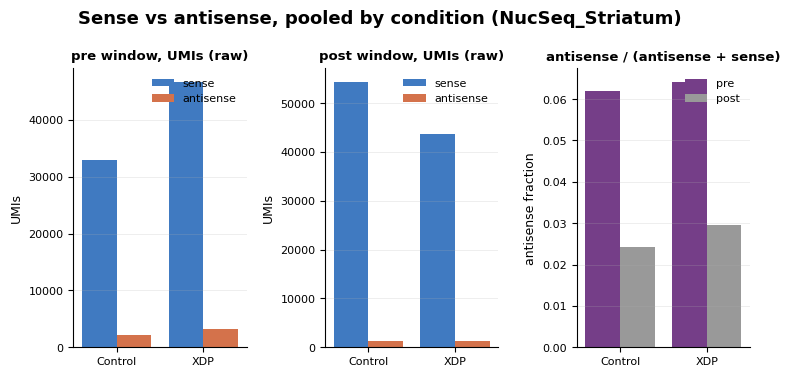

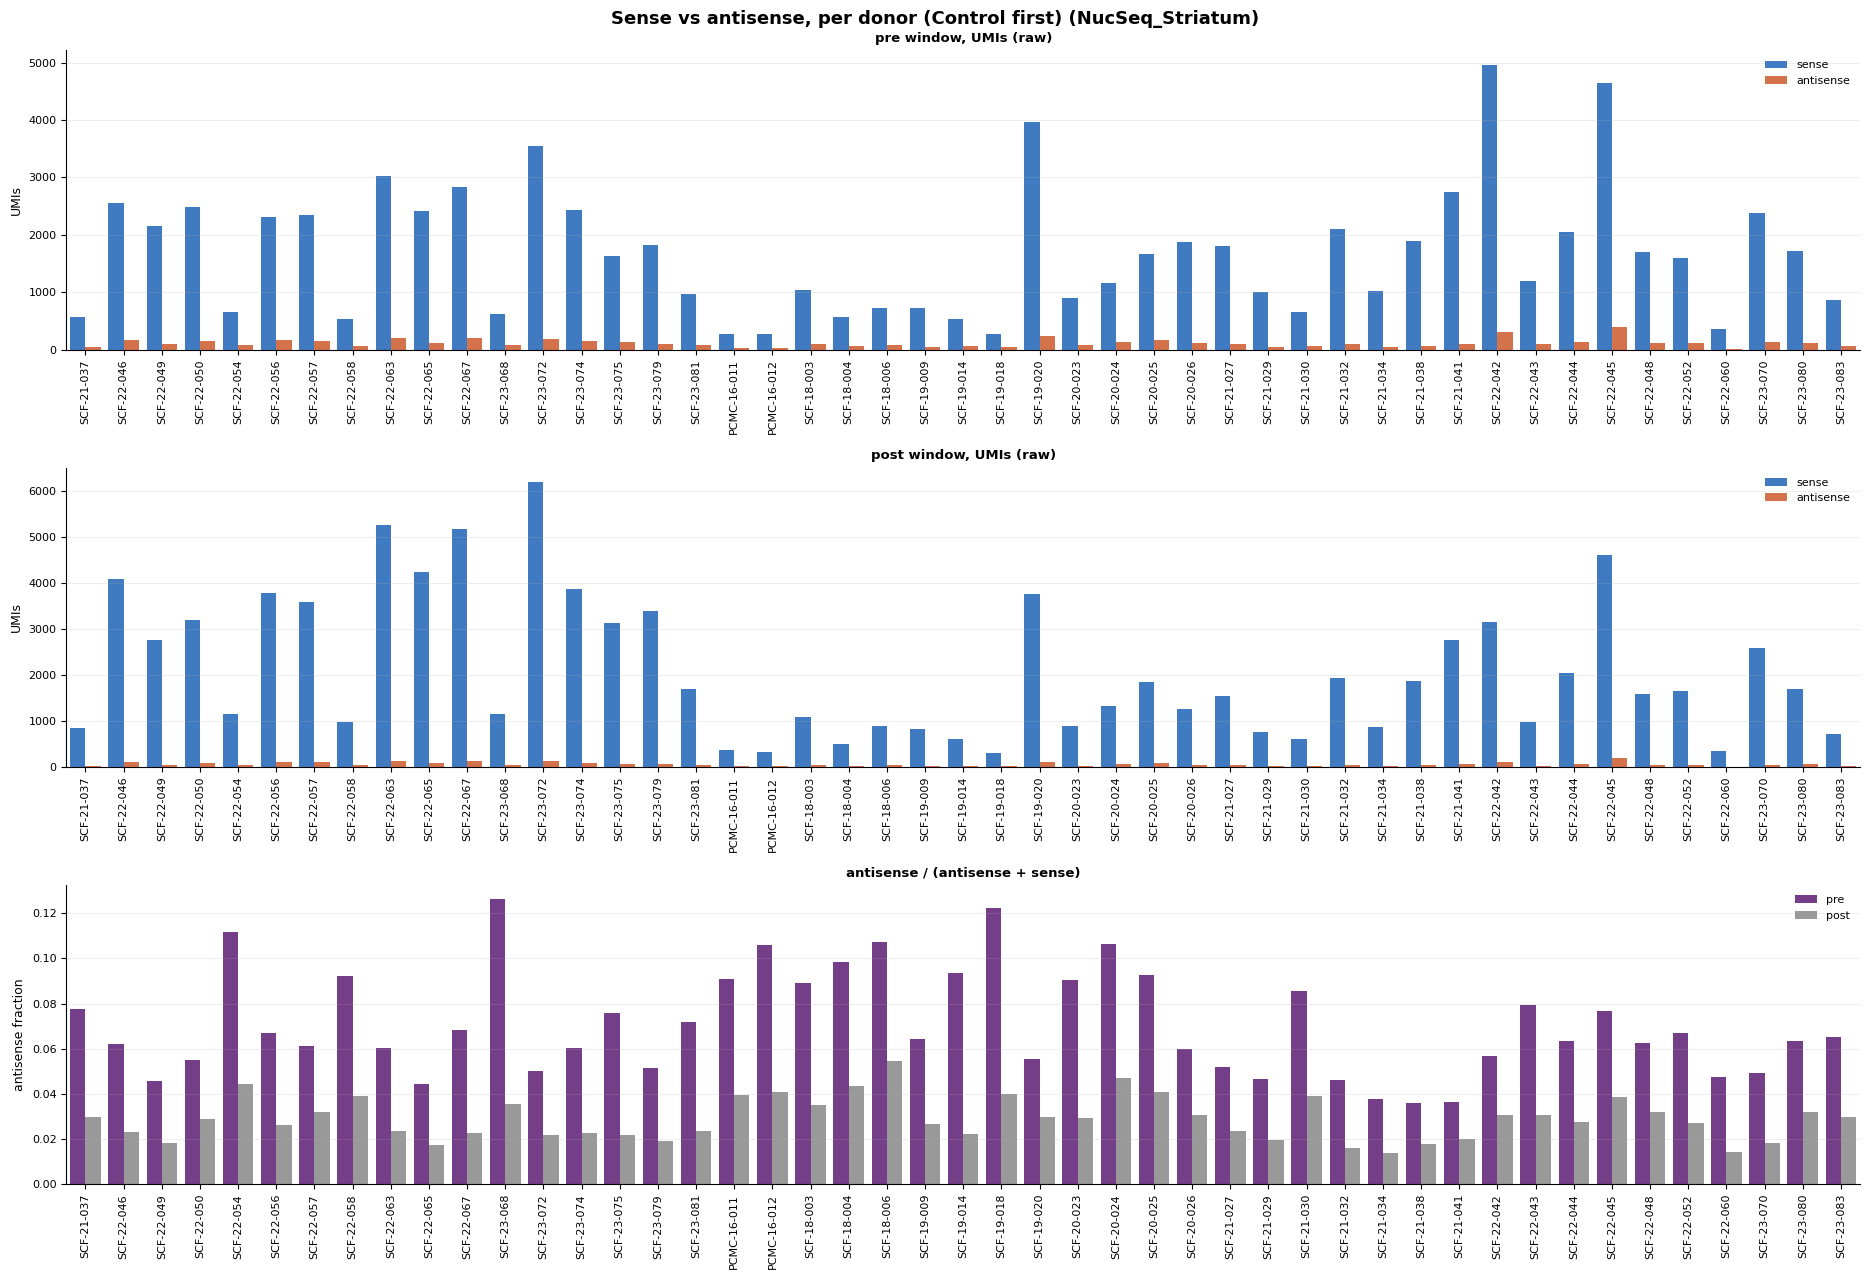

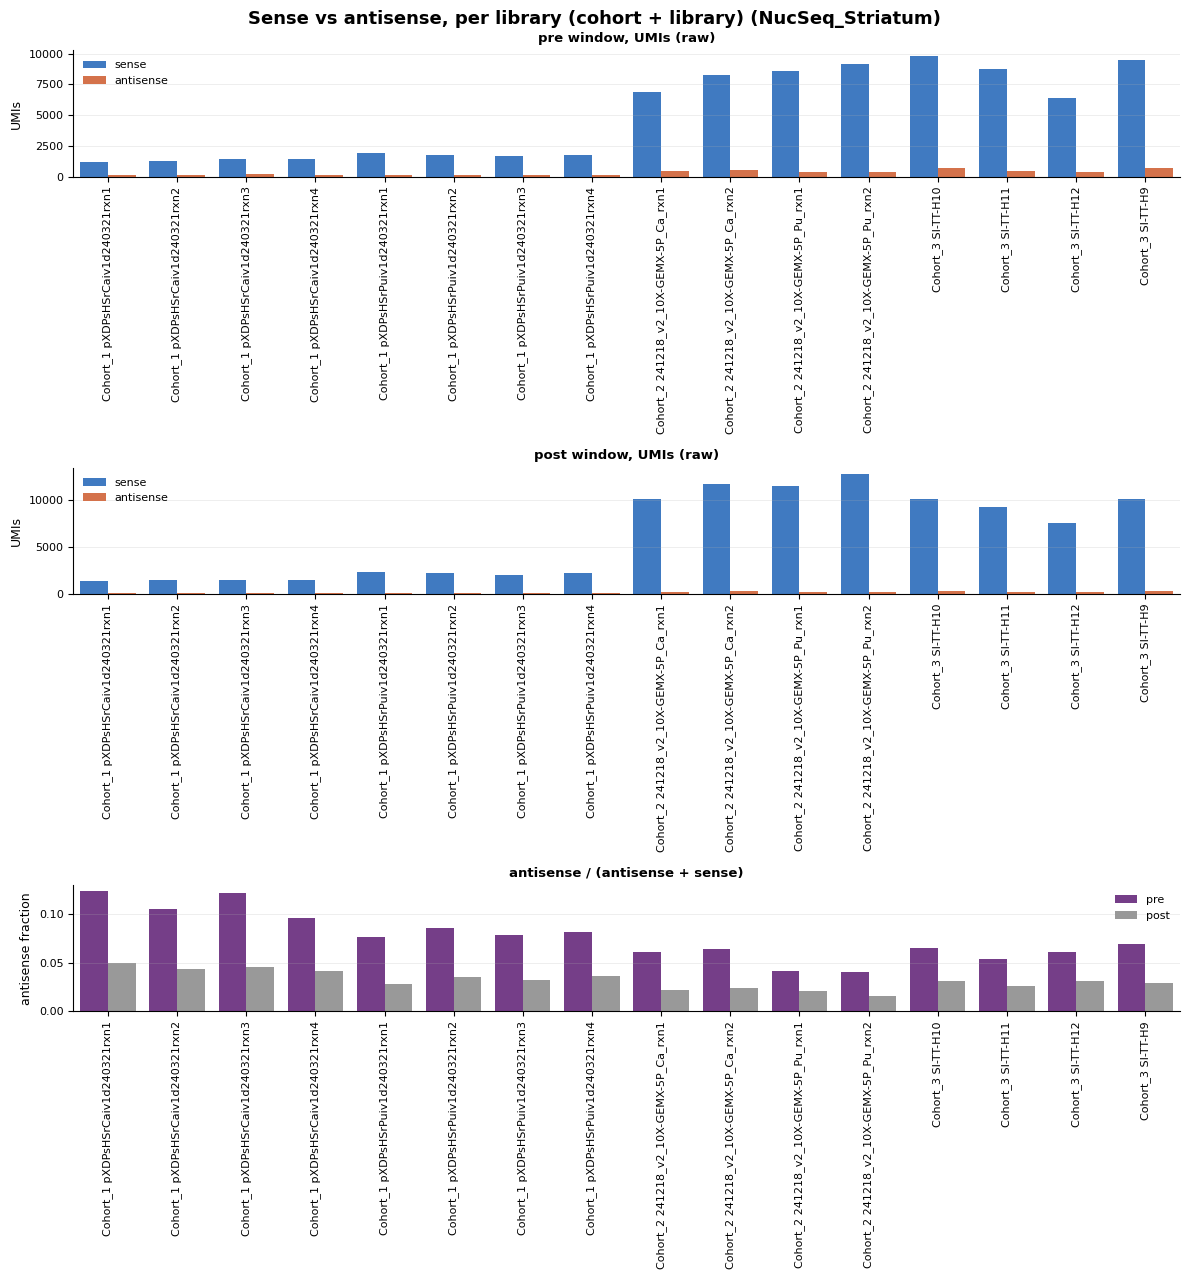

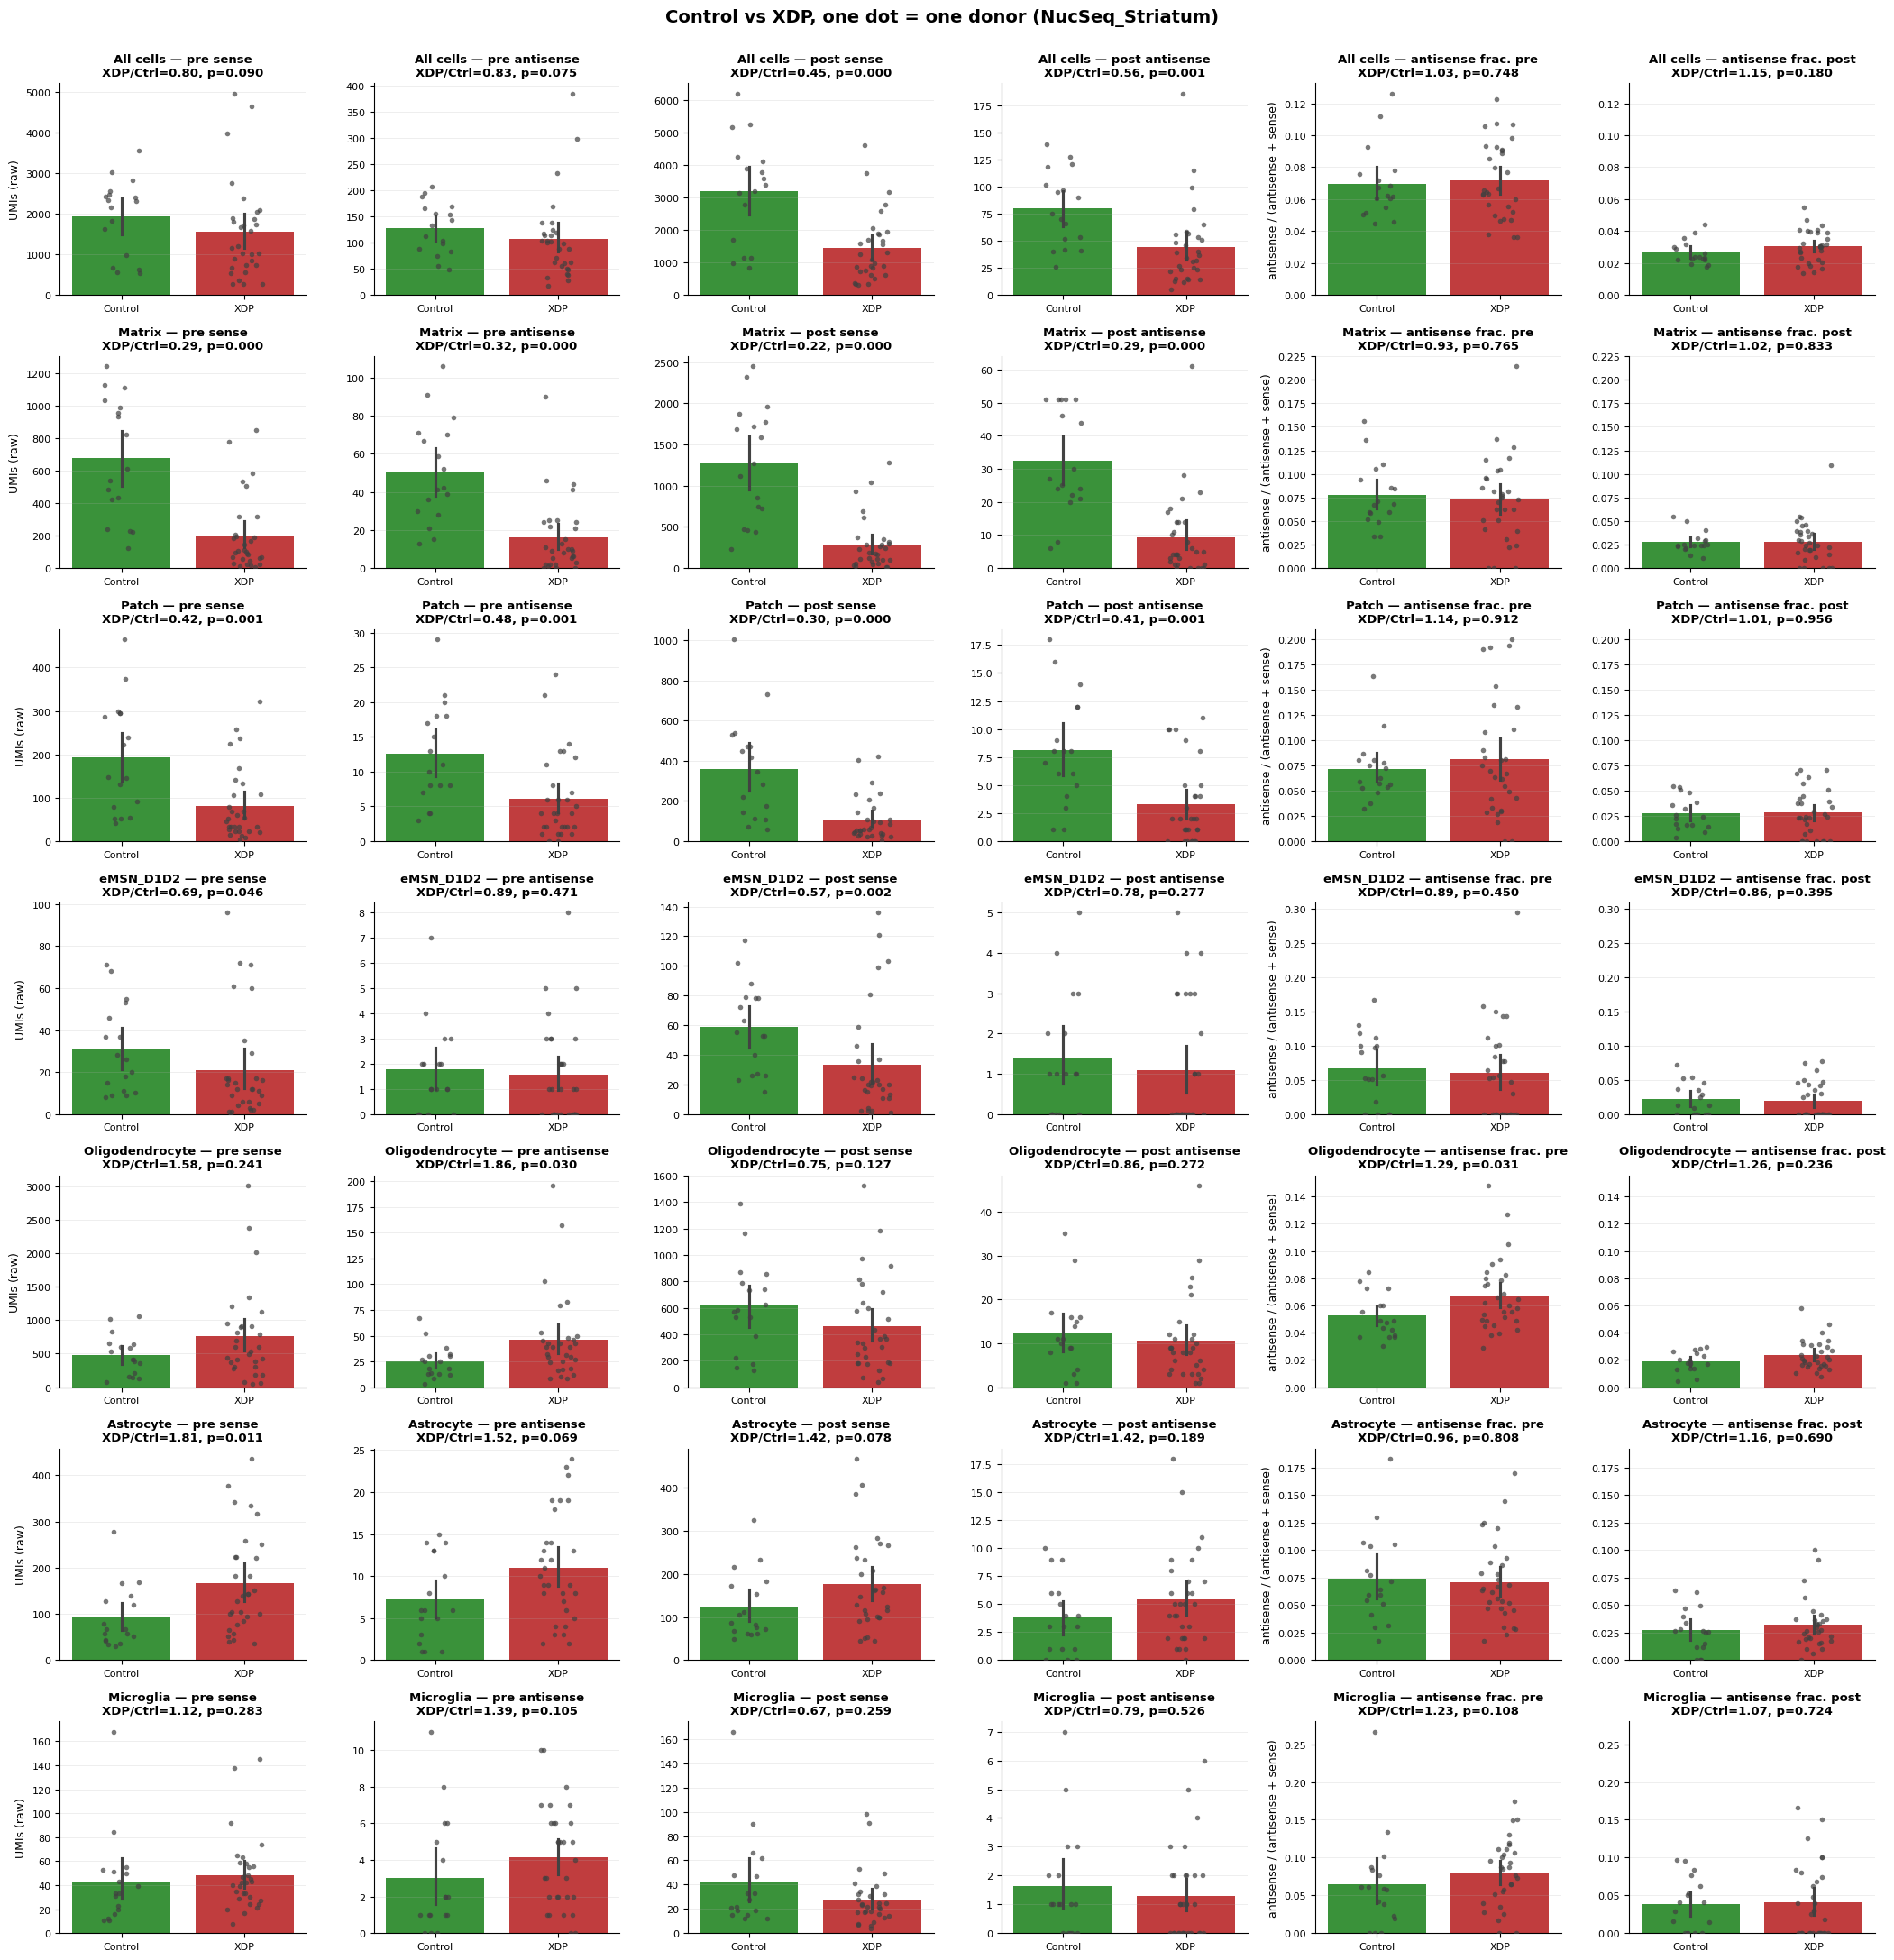

xdp_over_control                          \
cells                            All cells Matrix  Patch eMSN_D1D2   
value                                                                
UMIs pre sense (raw)                 0.805  0.294  0.423     0.686   
UMIs pre antisense (raw)             0.835  0.316  0.479     0.888   
UMIs post sense (raw)                0.455  0.223  0.302     0.574   
UMIs post antisense (raw)            0.558  0.289  0.407     0.779   
antisense fraction pre               1.030  0.934  1.144     0.895   
antisense fraction post              1.146  1.017  1.005     0.863   

                                                                      p  \
cells                     Oligodendrocyte Astrocyte Microglia All cells   
value                                                                     
UMIs pre sense (raw)                1.579     1.815     1.123     0.090   
UMIs pre antisense (raw)            1.856     1.520     1.389     0.075   
UMIs post sense (raw)               0.745     1.418     0.669     0.000   
UMIs post antisense (raw)           0.857     1.421     0.789     0.001   
antisense fraction pre              1.286     0.956     1.231     0.748   
antisense fraction post             1.262     1.164     1.066     0.180   

                                                                             \
cells                     Matrix  Patch eMSN_D1D2 Oligodendrocyte Astrocyte   
value                                                                         
UMIs pre sense (raw)       0.000  0.001     0.046           0.241     0.011   
UMIs pre antisense (raw)   0.000  0.001     0.471           0.030     0.069   
UMIs post sense (raw)      0.000  0.000     0.002           0.127     0.078   
UMIs post antisense (raw)  0.000  0.001     0.277           0.272     0.189   
antisense fraction pre     0.765  0.912     0.450           0.031     0.808   
antisense fraction post    0.833  0.956     0.395           0.236     0.690   

                                     
cells                     Microglia  
value                                
UMIs pre sense (raw)          0.283  
UMIs pre antisense (raw)      0.105  
UMIs post sense (raw)         0.259  
UMIs post antisense (raw)     0.526  
antisense fraction pre        0.108  
antisense fraction post       0.724

In [11]:
# Sense vs antisense in intron 32 (pre = before the SVA) and exon 33-38 (post)
# 2 versions: raw UMIs, and antisense fraction = antisense / (antisense + sense)
# (the fraction is independent of n cells / sequencing depth -> fair Control vs XDP comparison)
# levels: pooled by condition, per donor, per library, per cell type
from scipy.stats import mannwhitneyu

STRAND_COLORS = {"sense": "#2a78d6", "antisense": "#eb6834"}      # blue / orange
CONDITION_COLORS = {"Control": "#2ca02c", "XDP": "#d62728"}       # green / red
WINDOW_COLORS = {"pre": "#7b3294", "post": "0.6"}
STRAND_COUNT_COLS = {
    "n_pre_sense_umis": ("pre", "sense"), "n_pre_antisense_umis": ("pre", "antisense"),
    "n_post_sense_umis": ("post", "sense"), "n_post_antisense_umis": ("post", "antisense"),
}
CT_SPLIT = ["Matrix", "Patch", "eMSN_D1D2", "Oligodendrocyte", "Astrocyte", "Microglia"]

# donors in EXCLUDE_DONORS are already removed in obs_nuc_an
df_cells = obs_nuc_an
# a library mixes donors (and conditions) -> per library plots are not split by condition
df_cells["library"] = df_cells["cohort"].astype(str) + " " + df_cells["library_name"].astype(str)

donor_order = df_cells.sort_values(["condition", "donor_id"])["donor_id"].unique().tolist()
library_order = sorted(df_cells["library"].unique())


def strand_counts(df, group_cols):
    # summed UMIs per group, long: one row per group x window x strand
    out = df.groupby(group_cols, observed=True)[list(STRAND_COUNT_COLS)].sum().reset_index()
    out = out.melt(id_vars=group_cols, var_name="col", value_name="n_umis")
    out[["window", "strand"]] = out["col"].map(STRAND_COUNT_COLS).tolist()
    return out.drop(columns="col")


def antisense_fraction(df, group_cols):
    # antisense / (antisense + sense) on the summed UMIs, long: one row per group x window
    s = df.groupby(group_cols, observed=True)[list(STRAND_COUNT_COLS)].sum()
    return pd.concat([
        (s[f"n_{w}_antisense_umis"] / (s[f"n_{w}_antisense_umis"] + s[f"n_{w}_sense_umis"]))
        .rename("antisense_fraction").reset_index().assign(window=w)
        for w in ["pre", "post"]
    ], ignore_index=True)


def style(ax, title, ylabel="", rotate=False):
    ax.set_title(title, fontsize=9.5, fontweight="semibold")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=9)
    ax.tick_params(axis="x", rotation=90 if rotate else 0, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", linewidth=0.5, alpha=0.3)
    sns.despine(ax=ax)


# ---------------------------------------------------------------- 1. descriptive: pooled / per donor / per library
def plot_groups(df, group_cols, x, order, title):
    # raw UMIs (pre, post: sense vs antisense) + antisense fraction (pre vs post)
    # many groups (donors, libraries) -> one panel per row
    counts, frac = strand_counts(df, group_cols), antisense_fraction(df, group_cols)
    vertical = len(order) > 6
    nrows, ncols = (3, 1) if vertical else (1, 3)
    figsize = (max(12, 0.4 * len(order)), 13) if vertical else (5 + 1.35 * len(order), 3.8)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    rotate = len(order) > 4
    for ax, win in zip(axes[:2], ["pre", "post"]):
        sns.barplot(counts[counts["window"] == win], x=x, y="n_umis", hue="strand", order=order,
                    hue_order=["sense", "antisense"], palette=STRAND_COLORS, errorbar=None, ax=ax)
        ax.legend(title=None, frameon=False, fontsize=8)
        style(ax, f"{win} window, UMIs (raw)", "UMIs", rotate)
    sns.barplot(frac, x=x, y="antisense_fraction", hue="window", order=order,
                hue_order=["pre", "post"], palette=WINDOW_COLORS, errorbar=None, ax=axes[2])
    axes[2].legend(title=None, frameon=False, fontsize=8)
    style(axes[2], "antisense / (antisense + sense)", "antisense fraction", rotate)
    fig.suptitle(f"{title} ({ANALYSIS_NAME})", fontsize=13, fontweight="bold")
    fig.tight_layout()
    plt.show()


plot_groups(df_cells, ["condition"], "condition", ["Control", "XDP"], "Sense vs antisense, pooled by condition")
plot_groups(df_cells, ["donor_id", "condition"], "donor_id", donor_order, "Sense vs antisense, per donor (Control first)")
plot_groups(df_cells, ["library"], "library", library_order, "Sense vs antisense, per library (cohort + library)")


# ---------------------------------------------------------------- 2. Control vs XDP, one dot per donor: all cells + per cell type
def bar_dots_test(ax, d, y):
    # Control vs XDP bar + one dot per donor, returns fold change XDP / Control and Mann-Whitney p
    sns.barplot(d, x="condition", y=y, hue="condition", order=["Control", "XDP"],
                palette=CONDITION_COLORS, errorbar="ci", legend=False, ax=ax)
    sns.stripplot(d, x="condition", y=y, order=["Control", "XDP"],
                  color="0.25", size=4, jitter=0.15, alpha=0.7, ax=ax)
    ctrl = d.loc[d["condition"] == "Control", y].dropna()
    xdp = d.loc[d["condition"] == "XDP", y].dropna()
    if len(ctrl) < 2 or len(xdp) < 2:
        return np.nan, np.nan
    _, p = mannwhitneyu(ctrl, xdp, alternative="two-sided")
    return xdp.mean() / ctrl.mean(), p


rows = [("All cells", df_cells)] + [(ct, df_cells[df_cells["ct_for_deg"] == ct]) for ct in CT_SPLIT]
test_results = []

fig, axes = plt.subplots(len(rows), 6, figsize=(21, 3.1 * len(rows)))
for r, (row_label, df_row) in enumerate(rows):
    counts = strand_counts(df_row, ["donor_id", "condition"])
    frac = antisense_fraction(df_row, ["donor_id", "condition"])

    # raw UMIs: 4 panels (window x strand); not normalized -> depends on n cells, descriptive only
    for c, (win, strand) in enumerate(STRAND_COUNT_COLS.values()):
        fc, p = bar_dots_test(axes[r, c], counts[(counts["window"] == win) & (counts["strand"] == strand)], "n_umis")
        test_results.append({"cells": row_label, "value": f"UMIs {win} {strand} (raw)", "xdp_over_control": fc, "p": p})
        style(axes[r, c], f"{row_label} — {win} {strand}\nXDP/Ctrl={fc:.2f}, p={p:.3f}", "UMIs (raw)" if c == 0 else "")

    # antisense fraction: 2 panels (pre, post), same y axis
    for c, win in enumerate(["pre", "post"], start=4):
        fc, p = bar_dots_test(axes[r, c], frac[frac["window"] == win], "antisense_fraction")
        test_results.append({"cells": row_label, "value": f"antisense fraction {win}", "xdp_over_control": fc, "p": p})
        style(axes[r, c], f"{row_label} — antisense frac. {win}\nXDP/Ctrl={fc:.2f}, p={p:.3f}",
              "antisense / (antisense + sense)" if c == 4 else "")
    axes[r, 5].sharey(axes[r, 4])

fig.suptitle(f"Control vs XDP, one dot = one donor ({ANALYSIS_NAME})", fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

# summary: XDP / Control fold change and Mann-Whitney p (donors), all cells + per cell type
df_strand_tests = pd.DataFrame(test_results)
display(df_strand_tests.pivot_table(index="value", columns="cells", values=["xdp_over_control", "p"], sort=False)
        .round(3)[["xdp_over_control", "p"]])

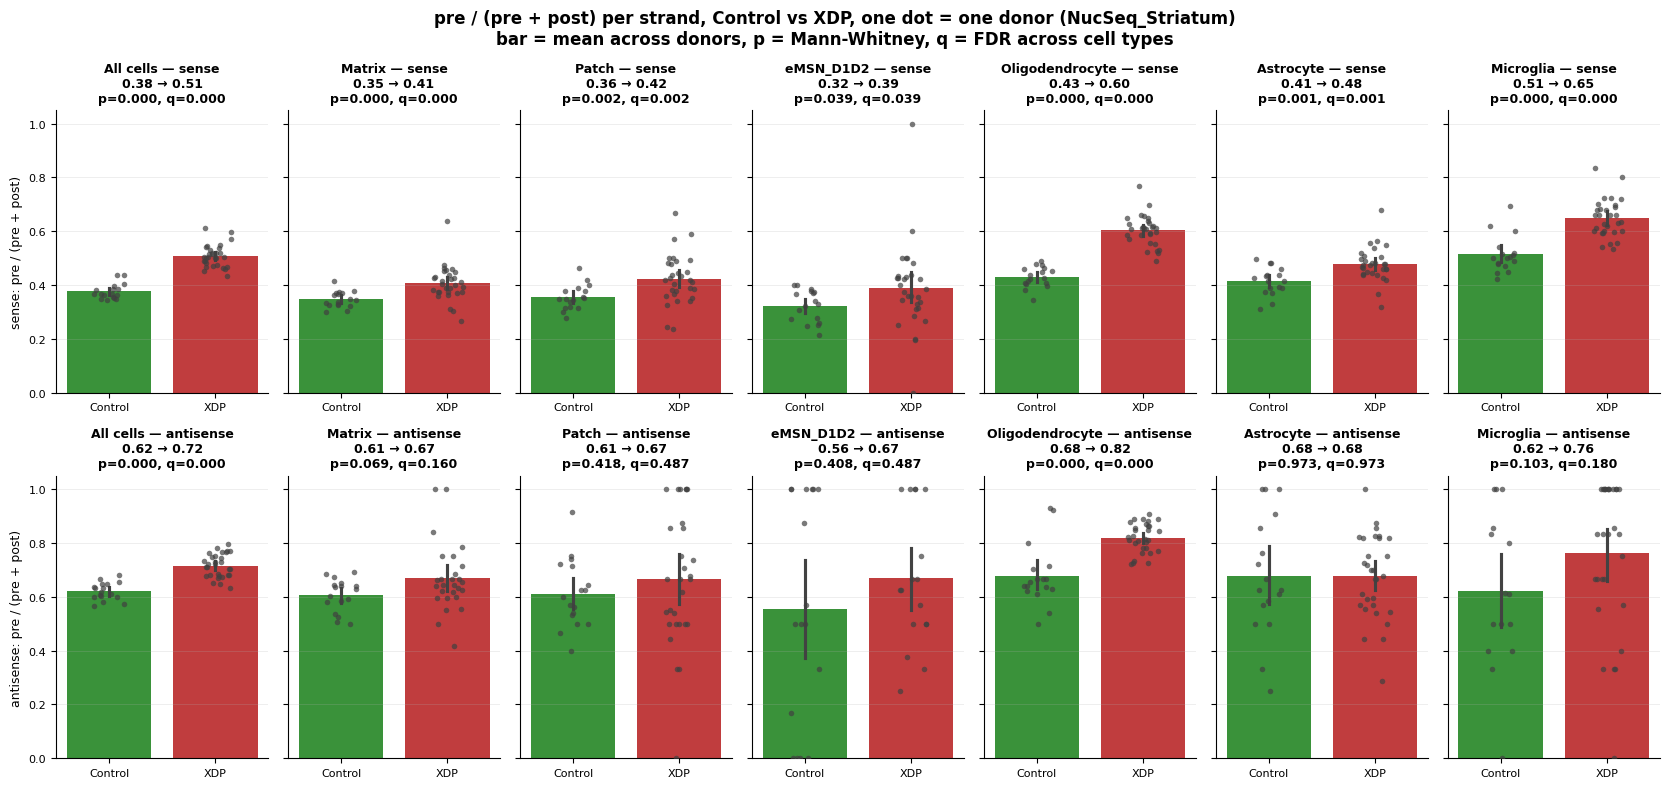

,strand,ct,n_control,n_xdp,mean_control,mean_xdp,diff_xdp_minus_control,p,q
0,sense,All cells,17,30,0.376,0.507,0.131,0.000,0.000
1,antisense,All cells,17,30,0.621,0.716,0.095,0.000,0.000
2,sense,Matrix,17,30,0.348,0.406,0.058,0.000,0.000
3,antisense,Matrix,17,27,0.607,0.670,0.063,0.069,0.160
4,sense,Patch,17,30,0.355,0.424,0.068,0.002,0.002
5,antisense,Patch,17,29,0.612,0.666,0.054,0.418,0.487
6,sense,eMSN_D1D2,17,30,0.323,0.388,0.065,0.039,0.039
7,antisense,eMSN_D1D2,17,17,0.556,0.668,0.113,0.408,0.487
8,sense,Oligodendrocyte,17,30,0.430,0.603,0.173,0.000,0.000
9,antisense,Oligodendrocyte,17,30,0.679,0.820,0.140,0.000,0.000


In [12]:
# Simple readout: per cell type and per strand, ratio = pre / (pre + post) per donor
# (pre = intron 32 before the SVA, post = exon 33-38); compare Control vs XDP
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

CONDITION_COLORS = {"Control": "#2ca02c", "XDP": "#d62728"}   # green / red
CT_SIMPLE = ["All cells", "Matrix", "Patch", "eMSN_D1D2", "Oligodendrocyte", "Astrocyte", "Microglia"]
STRANDS = ["sense", "antisense"]

# donors in EXCLUDE_DONORS are already removed in obs_nuc_an
df_cells = obs_nuc_an

# one row per cell type x strand x donor
rows = []
for ct in CT_SIMPLE:
    d = df_cells if ct == "All cells" else df_cells[df_cells["ct_for_deg"] == ct]
    s = d.groupby(["donor_id", "condition"], observed=True)[
        ["n_pre_sense_umis", "n_post_sense_umis", "n_pre_antisense_umis", "n_post_antisense_umis"]].sum().reset_index()
    for strand in STRANDS:
        pre, post = s[f"n_pre_{strand}_umis"], s[f"n_post_{strand}_umis"]
        rows.append(pd.DataFrame({"ct": ct, "strand": strand, "donor_id": s["donor_id"],
                                  "condition": s["condition"], "pre": pre, "post": post,
                                  "pre_ratio": pre / (pre + post)}))
df_pre_ratio = pd.concat(rows, ignore_index=True).dropna(subset=["pre_ratio"])

# stats: mean across donors per group, Mann-Whitney Control vs XDP, FDR across cell types (per strand)
stats = []
for (strand, ct), d in df_pre_ratio.groupby(["strand", "ct"], sort=False):
    ctrl = d.loc[d["condition"] == "Control", "pre_ratio"]
    xdp = d.loc[d["condition"] == "XDP", "pre_ratio"]
    _, p = mannwhitneyu(ctrl, xdp, alternative="two-sided")
    stats.append({"strand": strand, "ct": ct, "n_control": len(ctrl), "n_xdp": len(xdp),
                  "mean_control": ctrl.mean(), "mean_xdp": xdp.mean(), "diff_xdp_minus_control": xdp.mean() - ctrl.mean(), "p": p})
df_pre_ratio_stats = pd.DataFrame(stats)
df_pre_ratio_stats["q"] = df_pre_ratio_stats.groupby("strand")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
st = df_pre_ratio_stats.set_index(["strand", "ct"])

# plot: one row per strand, one column per cell type, same y axis everywhere
fig, axes = plt.subplots(len(STRANDS), len(CT_SIMPLE), figsize=(2.4 * len(CT_SIMPLE), 4 * len(STRANDS)), sharey=True)
for r, strand in enumerate(STRANDS):
    for c, ct in enumerate(CT_SIMPLE):
        ax = axes[r, c]
        d = df_pre_ratio[(df_pre_ratio["strand"] == strand) & (df_pre_ratio["ct"] == ct)]
        sns.barplot(d, x="condition", y="pre_ratio", hue="condition", order=["Control", "XDP"],
                    palette=CONDITION_COLORS, errorbar="ci", legend=False, ax=ax)
        sns.stripplot(d, x="condition", y="pre_ratio", order=["Control", "XDP"],
                      color="0.25", size=4, jitter=0.15, alpha=0.7, ax=ax)
        t = st.loc[(strand, ct)]
        ax.set_title(f"{ct} — {strand}\n{t['mean_control']:.2f} → {t['mean_xdp']:.2f}\np={t['p']:.3f}, q={t['q']:.3f}",
                     fontsize=9, fontweight="semibold")
        ax.set_xlabel("")
        ax.set_ylabel(f"{strand}: pre / (pre + post)" if c == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.grid(axis="y", linewidth=0.5, alpha=0.3)
        sns.despine(ax=ax)
fig.suptitle(f"pre / (pre + post) per strand, Control vs XDP, one dot = one donor ({ANALYSIS_NAME})\n"
             f"bar = mean across donors, p = Mann-Whitney, q = FDR across cell types", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

df_pre_ratio_stats.to_csv(OUT_DIR / f"32i_pre_ratio_per_strand_{ANALYSIS_NAME}.csv", index=False)
display(df_pre_ratio_stats.round(3))

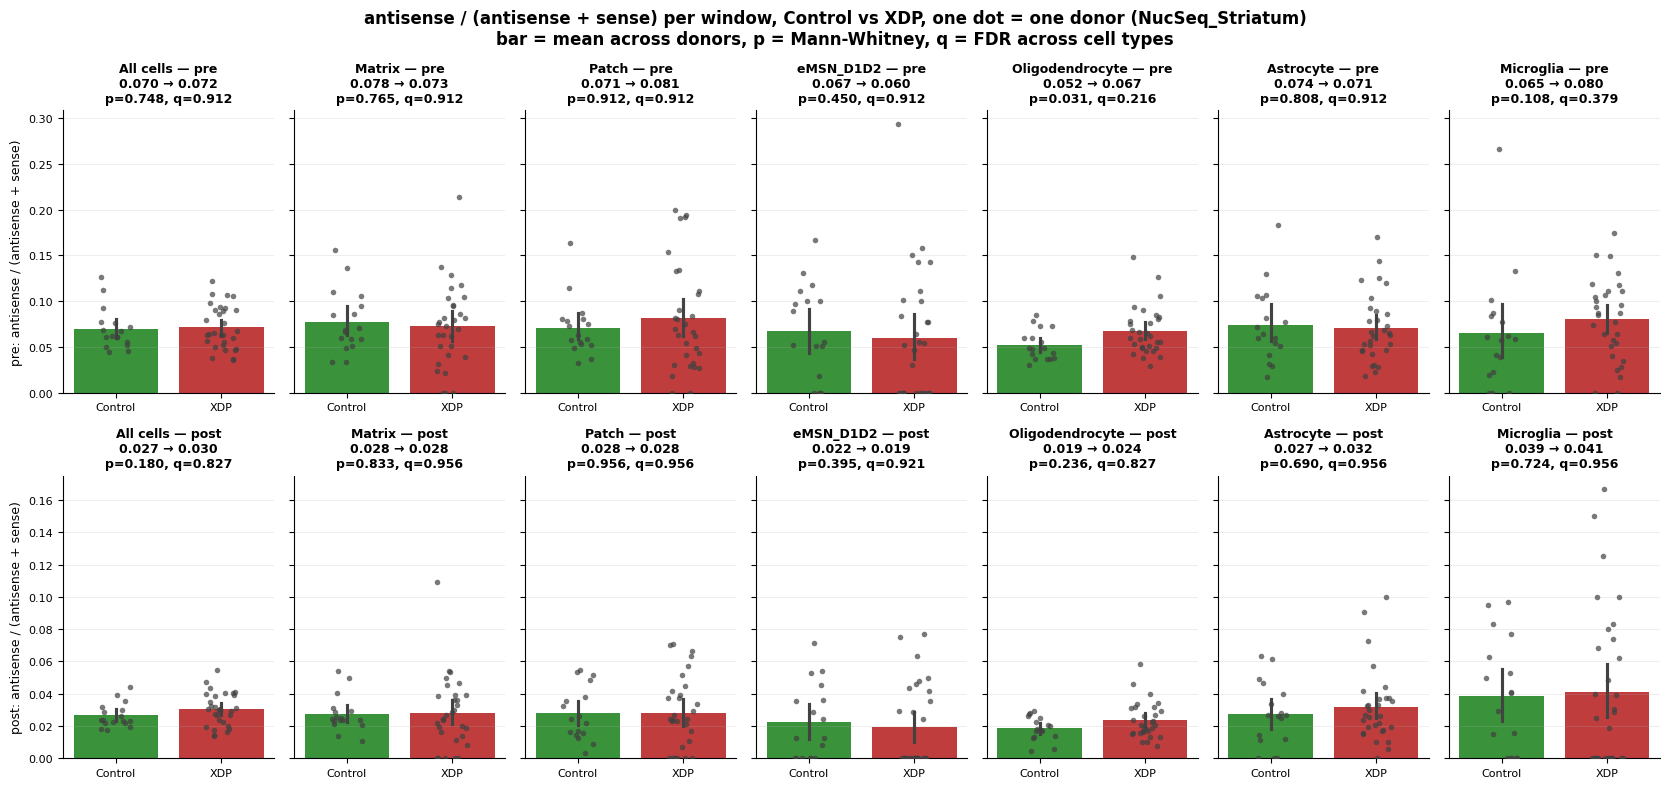

,window,ct,n_control,n_xdp,mean_control,mean_xdp,xdp_over_control,p,q
0,pre,All cells,17,30,0.070,0.072,1.030,0.748,0.912
1,post,All cells,17,30,0.027,0.030,1.146,0.180,0.827
2,pre,Matrix,17,30,0.078,0.073,0.934,0.765,0.912
3,post,Matrix,17,30,0.028,0.028,1.017,0.833,0.956
4,pre,Patch,17,30,0.071,0.081,1.144,0.912,0.912
5,post,Patch,17,30,0.028,0.028,1.005,0.956,0.956
6,pre,eMSN_D1D2,17,29,0.067,0.060,0.895,0.450,0.912
7,post,eMSN_D1D2,17,29,0.022,0.019,0.863,0.395,0.921
8,pre,Oligodendrocyte,17,30,0.052,0.067,1.286,0.031,0.216
9,post,Oligodendrocyte,17,30,0.019,0.024,1.262,0.236,0.827


In [13]:
# Simple readout: per cell type and per window, ratio = antisense / (antisense + sense) per donor
# (pre = intron 32 before the SVA, post = exon 33-38); compare Control vs XDP
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

CONDITION_COLORS = {"Control": "#2ca02c", "XDP": "#d62728"}   # green / red
CT_SIMPLE = ["All cells", "Matrix", "Patch", "eMSN_D1D2", "Oligodendrocyte", "Astrocyte", "Microglia"]
WINDOWS = ["pre", "post"]

# donors in EXCLUDE_DONORS are already removed in obs_nuc_an
df_cells = obs_nuc_an

# one row per cell type x window x donor
rows = []
for ct in CT_SIMPLE:
    d = df_cells if ct == "All cells" else df_cells[df_cells["ct_for_deg"] == ct]
    s = d.groupby(["donor_id", "condition"], observed=True)[
        ["n_pre_sense_umis", "n_pre_antisense_umis", "n_post_sense_umis", "n_post_antisense_umis"]].sum().reset_index()
    for win in WINDOWS:
        sense, antisense = s[f"n_{win}_sense_umis"], s[f"n_{win}_antisense_umis"]
        rows.append(pd.DataFrame({"ct": ct, "window": win, "donor_id": s["donor_id"],
                                  "condition": s["condition"], "sense": sense, "antisense": antisense,
                                  "antisense_ratio": antisense / (antisense + sense)}))
df_as_ratio = pd.concat(rows, ignore_index=True).dropna(subset=["antisense_ratio"])

# stats: mean across donors per group, Mann-Whitney Control vs XDP, FDR across cell types (per window)
stats = []
for (win, ct), d in df_as_ratio.groupby(["window", "ct"], sort=False):
    ctrl = d.loc[d["condition"] == "Control", "antisense_ratio"]
    xdp = d.loc[d["condition"] == "XDP", "antisense_ratio"]
    _, p = mannwhitneyu(ctrl, xdp, alternative="two-sided")
    stats.append({"window": win, "ct": ct, "n_control": len(ctrl), "n_xdp": len(xdp),
                  "mean_control": ctrl.mean(), "mean_xdp": xdp.mean(), "xdp_over_control": xdp.mean() / ctrl.mean(), "p": p})
df_as_ratio_stats = pd.DataFrame(stats)
df_as_ratio_stats["q"] = df_as_ratio_stats.groupby("window")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
st = df_as_ratio_stats.set_index(["window", "ct"])

# plot: one row per window, one column per cell type, same y axis within a row
fig, axes = plt.subplots(len(WINDOWS), len(CT_SIMPLE), figsize=(2.4 * len(CT_SIMPLE), 4 * len(WINDOWS)), sharey="row")
for r, win in enumerate(WINDOWS):
    for c, ct in enumerate(CT_SIMPLE):
        ax = axes[r, c]
        d = df_as_ratio[(df_as_ratio["window"] == win) & (df_as_ratio["ct"] == ct)]
        sns.barplot(d, x="condition", y="antisense_ratio", hue="condition", order=["Control", "XDP"],
                    palette=CONDITION_COLORS, errorbar="ci", legend=False, ax=ax)
        sns.stripplot(d, x="condition", y="antisense_ratio", order=["Control", "XDP"],
                      color="0.25", size=4, jitter=0.15, alpha=0.7, ax=ax)
        t = st.loc[(win, ct)]
        ax.set_title(f"{ct} — {win}\n{t['mean_control']:.3f} → {t['mean_xdp']:.3f}\np={t['p']:.3f}, q={t['q']:.3f}",
                     fontsize=9, fontweight="semibold")
        ax.set_xlabel("")
        ax.set_ylabel(f"{win}: antisense / (antisense + sense)" if c == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.grid(axis="y", linewidth=0.5, alpha=0.3)
        sns.despine(ax=ax)
fig.suptitle(f"antisense / (antisense + sense) per window, Control vs XDP, one dot = one donor ({ANALYSIS_NAME})\n"
             f"bar = mean across donors, p = Mann-Whitney, q = FDR across cell types", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

df_as_ratio_stats.to_csv(OUT_DIR / f"32i_antisense_ratio_per_window_{ANALYSIS_NAME}.csv", index=False)
display(df_as_ratio_stats.round(3))

# Quanitty 32i

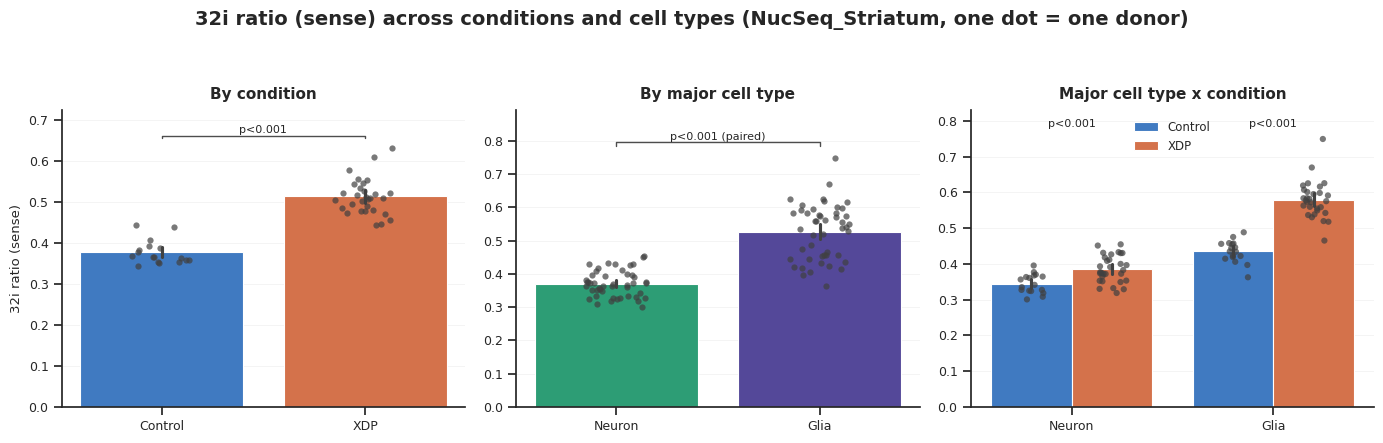

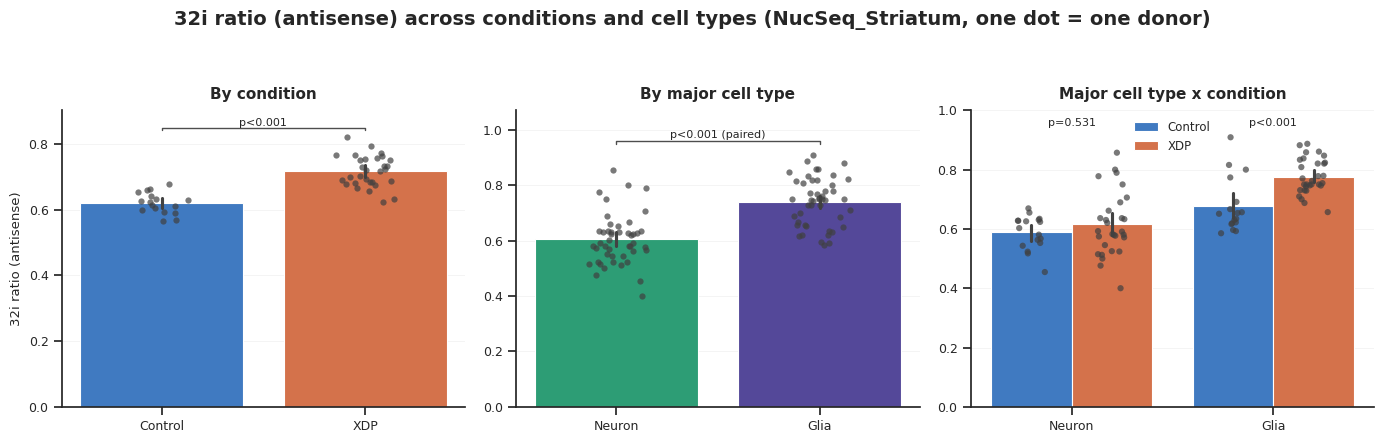

In [14]:
from scipy.stats import mannwhitneyu, wilcoxon

# fixed categorical color assignments — validated colorblind-safe pairs, never cycled
CONDITION_COLORS = {"Control": "#2a78d6", "XDP": "#eb6834"}   # blue / orange
CT_COLORS        = {"Neuron": "#1baf7a", "Glia": "#4a3aa7"}   # aqua / violet — distinct from condition slots

# the 2 versions of the 32i metric -- every analysis below is a function, called once per version
METRICS = {
    "pileup_metric_sense": "32i ratio (sense)",
    "pileup_metric_antisense": "32i ratio (antisense)",
}
# add "pileup_metric": "32i ratio (both strands)" or "pre_antisense_fraction": "antisense fraction (intron 32)" to run them too

sns.set_theme(style="ticks", context="notebook")


def style_ax(ax, title, ylabel=None):
    ax.set_title(title, fontsize=11, fontweight="semibold", pad=8)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel if ylabel else "", fontsize=9.5)
    ax.tick_params(labelsize=9)
    ax.grid(axis="y", linewidth=0.5, alpha=0.3)
    sns.despine(ax=ax)


def annotate_sig(ax, data, x, y, order, g1="Control", g2="XDP"):
    y_max, y_min = data[y].max(), data[y].min()
    offset = (y_max - y_min) * 0.06 if y_max != y_min else 0.02
    for i, cat in enumerate(order):
        a = data.loc[(data[x] == cat) & (data["condition"] == g1), y].dropna()
        b = data.loc[(data[x] == cat) & (data["condition"] == g2), y].dropna()
        if len(a) < 2 or len(b) < 2:
            continue
        _, p = mannwhitneyu(a, b, alternative="two-sided")
        label = f"p={p:.3f}" if p >= 0.001 else "p<0.001"
        ax.text(i, y_max + offset, label, ha="center", va="bottom", fontsize=8)
    ax.set_ylim(top=y_max + offset * 3)


def annotate_sig_pair(ax, data, x, y, order, g1, g2, paired_on=None):
    """Direct two-group comparison (no sub-category split) — bracket + p-value.

    paired_on: column identifying the pairs (e.g. "donor_id" when the same donors
    are in both groups) -> Wilcoxon signed-rank instead of Mann-Whitney.
    """
    if paired_on:
        wide = data.pivot(index=paired_on, columns=x, values=y)[[g1, g2]].dropna()
        a, b = wide[g1], wide[g2]
    else:
        a = data.loc[data[x] == g1, y].dropna()
        b = data.loc[data[x] == g2, y].dropna()
    if len(a) < 2 or len(b) < 2:
        return
    if paired_on:
        _, p = wilcoxon(a, b)
    else:
        _, p = mannwhitneyu(a, b, alternative="two-sided")
    label = f"p={p:.3f}" if p >= 0.001 else "p<0.001"
    if paired_on:
        label += " (paired)"
    y_max, y_min = data[y].max(), data[y].min()
    offset = (y_max - y_min) * 0.08 if y_max != y_min else 0.02
    x1, x2, y_line = order.index(g1), order.index(g2), y_max + offset
    ax.plot([x1, x1, x2, x2], [y_line, y_line + offset * 0.3, y_line + offset * 0.3, y_line], lw=1, color="0.3")
    ax.text((x1 + x2) / 2, y_line + offset * 0.35, label, ha="center", va="bottom", fontsize=8)
    ax.set_ylim(top=y_line + offset * 3)


def plot_overview(df, metric, metric_label):
    # one dot = one donor: sum the UMIs of the donor's cell types, then recompute the metric
    # (summing UMIs = pseudobulk, so abundant cell types like Oligodendrocyte weigh more)
    df_donor = add_32i_metrics(
        df.groupby(["donor_id", "condition"], observed=True)[COUNT_COLS].sum().reset_index()
    )
    df_donor_ct = add_32i_metrics(
        df.groupby(["donor_id", "condition", "ct"], observed=True)[COUNT_COLS].sum().reset_index()
    )

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.2))

    # A — by condition (one dot per donor)
    sns.barplot(df_donor, y=metric, x="condition", hue="condition",
                palette=CONDITION_COLORS, order=["Control", "XDP"], legend=False,
                errorbar="ci", edgecolor="white", linewidth=0.8, ax=ax1)
    sns.stripplot(df_donor, y=metric, x="condition", order=["Control", "XDP"],
                  color="0.25", size=4.5, jitter=0.15, alpha=0.7, ax=ax1)
    annotate_sig_pair(ax1, df_donor, "condition", metric, ["Control", "XDP"], "Control", "XDP")
    style_ax(ax1, "By condition", ylabel=metric_label)

    # B — by major cell type (one dot per donor; same donors in both -> paired test)
    sns.barplot(df_donor_ct, y=metric, x="ct", hue="ct",
                palette=CT_COLORS, order=["Neuron", "Glia"], legend=False,
                errorbar="ci", edgecolor="white", linewidth=0.8, ax=ax2)
    sns.stripplot(df_donor_ct, y=metric, x="ct", order=["Neuron", "Glia"],
                  color="0.25", size=4.5, jitter=0.15, alpha=0.7, ax=ax2)
    annotate_sig_pair(ax2, df_donor_ct, "ct", metric, ["Neuron", "Glia"], "Neuron", "Glia", paired_on="donor_id")
    style_ax(ax2, "By major cell type")

    # C — major cell type x condition (one dot per donor)
    sns.barplot(df_donor_ct, y=metric, x="ct", hue="condition",
                palette=CONDITION_COLORS, hue_order=["Control", "XDP"], order=["Neuron", "Glia"],
                errorbar="ci", edgecolor="white", linewidth=0.8, ax=ax3)
    sns.stripplot(df_donor_ct, y=metric, x="ct", hue="condition",
                  hue_order=["Control", "XDP"], order=["Neuron", "Glia"], dodge=True,
                  palette={"Control": "0.25", "XDP": "0.25"}, size=4.5, jitter=0.15, alpha=0.7,
                  legend=False, ax=ax3)
    annotate_sig(ax3, df_donor_ct, "ct", metric, ["Neuron", "Glia"])
    ax3.legend(title=None, fontsize=8.5, frameon=False, loc="best")
    style_ax(ax3, "Major cell type x condition")

    fig.suptitle(f"{metric_label} across conditions and cell types ({ANALYSIS_NAME}, one dot = one donor)",
                 fontsize=14, fontweight="bold", y=1.05)
    fig.tight_layout()
    plt.show()


for metric, metric_label in METRICS.items():
    plot_overview(df_pseudobulk_all, metric, metric_label)

# Test change in ratio

In [15]:
cell_types = ["Matrix", "Patch", "eMSN_D1D2", "non-MSN", "Oligodendrocyte", "Astrocyte", "Microglia"]  # swap for whatever cell type you want to analyze

In [16]:
# run manhwitney test on eahc cell type
def test_condition(df, metric, cell_types):
    for ct in cell_types:

        tmp = df[df["ct_for_deg"] == ct]

        control = tmp[tmp["condition"] == "Control"][metric].dropna()
        xdp = tmp[tmp["condition"] == "XDP"][metric].dropna()

        stat, pval = mannwhitneyu(control, xdp, alternative="two-sided")

        print(f"{ct}: n_control={len(control)}, n_xdp={len(xdp)}, Mann-Whitney U test p-value = {pval:.4e}")


for metric, metric_label in METRICS.items():
    print(f"\n{metric_label}\n{'=' * 60}")
    test_condition(df_pseudobulk_all, metric, cell_types)


32i ratio (sense)
Matrix: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 1.2236e-04
Patch: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 2.0861e-03
eMSN_D1D2: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 3.9443e-02
non-MSN: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 4.0562e-02
Oligodendrocyte: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 1.9933e-08
Astrocyte: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 7.3439e-04
Microglia: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 3.6992e-06

32i ratio (antisense)
Matrix: n_control=17, n_xdp=27, Mann-Whitney U test p-value = 6.8710e-02
Patch: n_control=17, n_xdp=29, Mann-Whitney U test p-value = 4.1773e-01
eMSN_D1D2: n_control=17, n_xdp=17, Mann-Whitney U test p-value = 4.0847e-01
non-MSN: n_control=17, n_xdp=28, Mann-Whitney U test p-value = 9.7197e-01
Oligodendrocyte: n_control=17, n_xdp=30, Mann-Whitney U test p-value = 4.1848e-05
Astrocyte: n_control=17, n_xdp=30, Mann-Whitney U te

/tmp/ipykernel_230791/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_230791/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


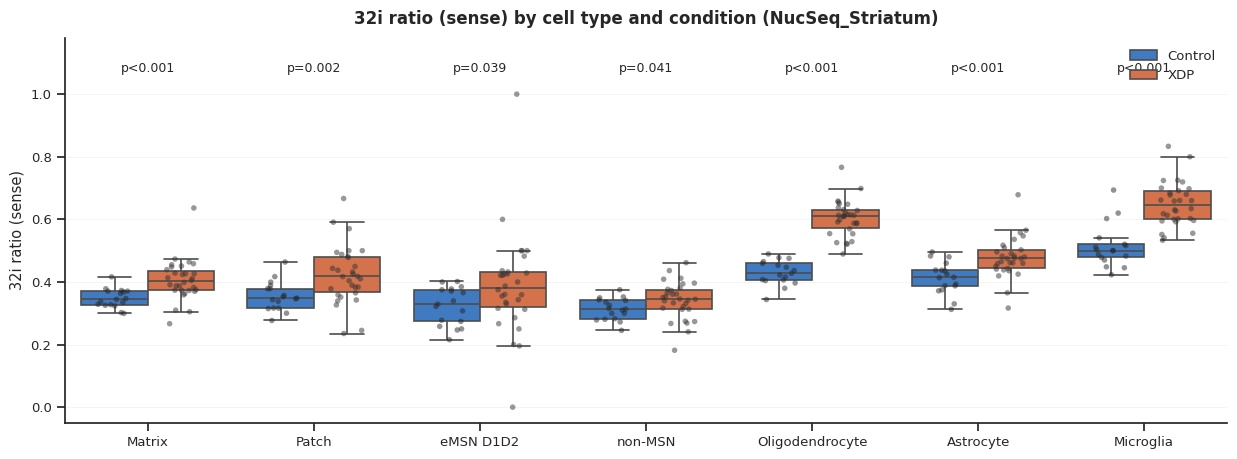

/tmp/ipykernel_230791/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_230791/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


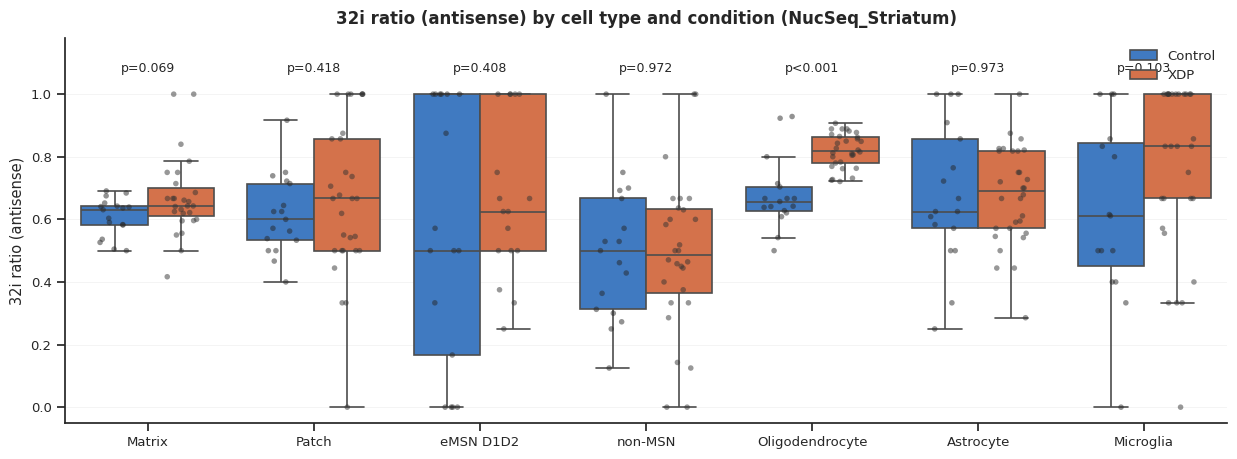

In [17]:
def annotate_pvals(ax, data, x, y, hue, order, g1="Control", g2="XDP"):
    y_max, y_min = data[y].max(), data[y].min()
    offset = (y_max - y_min) * 0.06 if y_max != y_min else 0.05
    for i, cat in enumerate(order):
        a = data.loc[(data[x] == cat) & (data[hue] == g1), y].dropna()
        b = data.loc[(data[x] == cat) & (data[hue] == g2), y].dropna()
        if len(a) < 2 or len(b) < 2:
            continue
        _, pval = mannwhitneyu(a, b, alternative="two-sided")
        label = f"p={pval:.3f}" if pval >= 0.001 else "p<0.001"
        ax.text(i, y_max + offset, label, ha="center", va="bottom", fontsize=9)
    ax.set_ylim(top=y_max + offset * 3)


def plot_pileup(data, y, order, ylabel="32i Ratio", hue="condition", hue_order=("Control", "XDP"), palette=CONDITION_COLORS):
    sns.set_theme(style="ticks", context="notebook")
    fig, ax = plt.subplots(figsize=(15, 5))

    sns.boxplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
                palette=palette, hue_order=list(hue_order),
                showfliers=False, linewidth=1.2, ax=ax)
    sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
                  hue_order=list(hue_order), dodge=True, color="0.2",
                  size=4, alpha=0.5, jitter=0.2, legend=False, ax=ax)

    annotate_pvals(ax, data, "ct_for_deg", y, hue, order, *hue_order)

    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=10.5)
    ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])
    ax.tick_params(labelsize=9.5)
    ax.grid(axis="y", linewidth=0.5, alpha=0.3)
    sns.despine(ax=ax)
    ax.legend(title=None, fontsize=9.5, frameon=False, loc="upper right")

    ax.set_title(f"{ylabel} by cell type and {hue} ({ANALYSIS_NAME})", fontsize=12, fontweight="semibold", pad=10)
    plt.show()


for metric, metric_label in METRICS.items():
    plot_pileup(df_pseudobulk_all, metric, cell_types, ylabel=metric_label)

# Corr ratio
Covariates are taken from the donor metadata csv (one value per donor)

In [18]:
covariate_per_cell_type = ["Age_of_Death", "Age_of_Onset", "repeat_length", "Disease_duration"]
XDP_ONLY_COVARIATES = {"repeat_length", "Disease_duration", "Age_of_Onset"}

# donor metadata ("not_applicable" for controls -> NaN)
df_donor_meta = df_meta[["donor_id", "Condition", *covariate_per_cell_type]].drop_duplicates("donor_id").copy()
for col in covariate_per_cell_type:
    df_donor_meta[col] = pd.to_numeric(df_donor_meta[col].astype(str), errors="coerce")
# repeat length is 0 for controls in the csv -> not a real value
df_donor_meta.loc[df_donor_meta["Condition"] == "Control", list(XDP_ONLY_COVARIATES)] = np.nan
df_donor_meta = df_donor_meta.drop(columns="Condition")
display(df_donor_meta)

df_cov = df_pseudobulk_all.merge(df_donor_meta, on="donor_id", how="left")

df_cov

,donor_id,Age_of_Death,Age_of_Onset,repeat_length,Disease_duration
0,SCF-22-054,51,NaN,NaN,NaN
1,SCF-23-075,60,NaN,NaN,NaN
2,SCF-22-067,19,NaN,NaN,NaN
3,SCF-23-079,47,NaN,NaN,NaN
4,SCF-22-065,69,NaN,NaN,NaN
5,SCF-23-072,28,NaN,NaN,NaN
6,SCF-22-050,78,NaN,NaN,NaN
7,SCF-23-068,43,NaN,NaN,NaN
8,SCF-23-074,26,NaN,NaN,NaN
9,SCF-22-057,66,NaN,NaN,NaN


,donor_id,condition,ct_for_deg,n_pre_umis,n_post_umis,n_pre_sense_umis,n_pre_antisense_umis,n_post_sense_umis,n_post_antisense_umis,n_cells,...,pileup_metric_norm,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction,post_antisense_fraction,ct,Age_of_Death,Age_of_Onset,repeat_length,Disease_duration
0,PCMC-16-011,XDP,Astrocyte,65.0,105.0,57.0,8.0,99.0,6.0,729,...,0.310449,0.365385,0.571429,0.123077,0.057143,Glia,55,53.0,35.0,2.0
1,PCMC-16-011,XDP,Matrix,48.0,53.0,45.0,3.0,52.0,1.0,213,...,0.397106,0.463918,0.750000,0.062500,0.018868,Neuron,55,53.0,35.0,2.0
2,PCMC-16-011,XDP,Microglia,23.0,4.0,20.0,3.0,4.0,0.0,150,...,0.807019,0.833333,1.000000,0.130435,0.000000,Glia,55,53.0,35.0,2.0
3,PCMC-16-011,XDP,OPC,14.0,9.0,14.0,0.0,9.0,0.0,96,...,0.530808,0.608696,NaN,0.000000,0.000000,Glia,55,53.0,35.0,2.0
4,PCMC-16-011,XDP,Oligodendrocyte,79.0,75.0,69.0,10.0,72.0,3.0,700,...,0.433770,0.489362,0.769231,0.126582,0.040000,Glia,55,53.0,35.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
418,SCF-23-083,XDP,Oligodendrocyte,445.0,189.0,424.0,25.0,183.0,6.0,979,...,0.631319,0.698517,0.806452,0.055679,0.031746,Glia,49,39.0,41.0,10.0
419,SCF-23-083,XDP,Patch,52.0,47.0,45.0,7.0,46.0,1.0,30,...,0.445875,0.494505,0.875000,0.134615,0.021277,Neuron,49,39.0,41.0,10.0
420,SCF-23-083,XDP,eMSN_D1D2,2.0,2.0,2.0,0.0,2.0,0.0,9,...,0.421055,0.500000,NaN,0.000000,0.000000,Neuron,49,39.0,41.0,10.0
421,SCF-23-083,XDP,eMSN_NUDAP,6.0,13.0,6.0,0.0,13.0,0.0,9,...,0.251310,0.315789,NaN,0.000000,0.000000,Neuron,49,39.0,41.0,10.0



Analyzing covariate: Age_of_Death


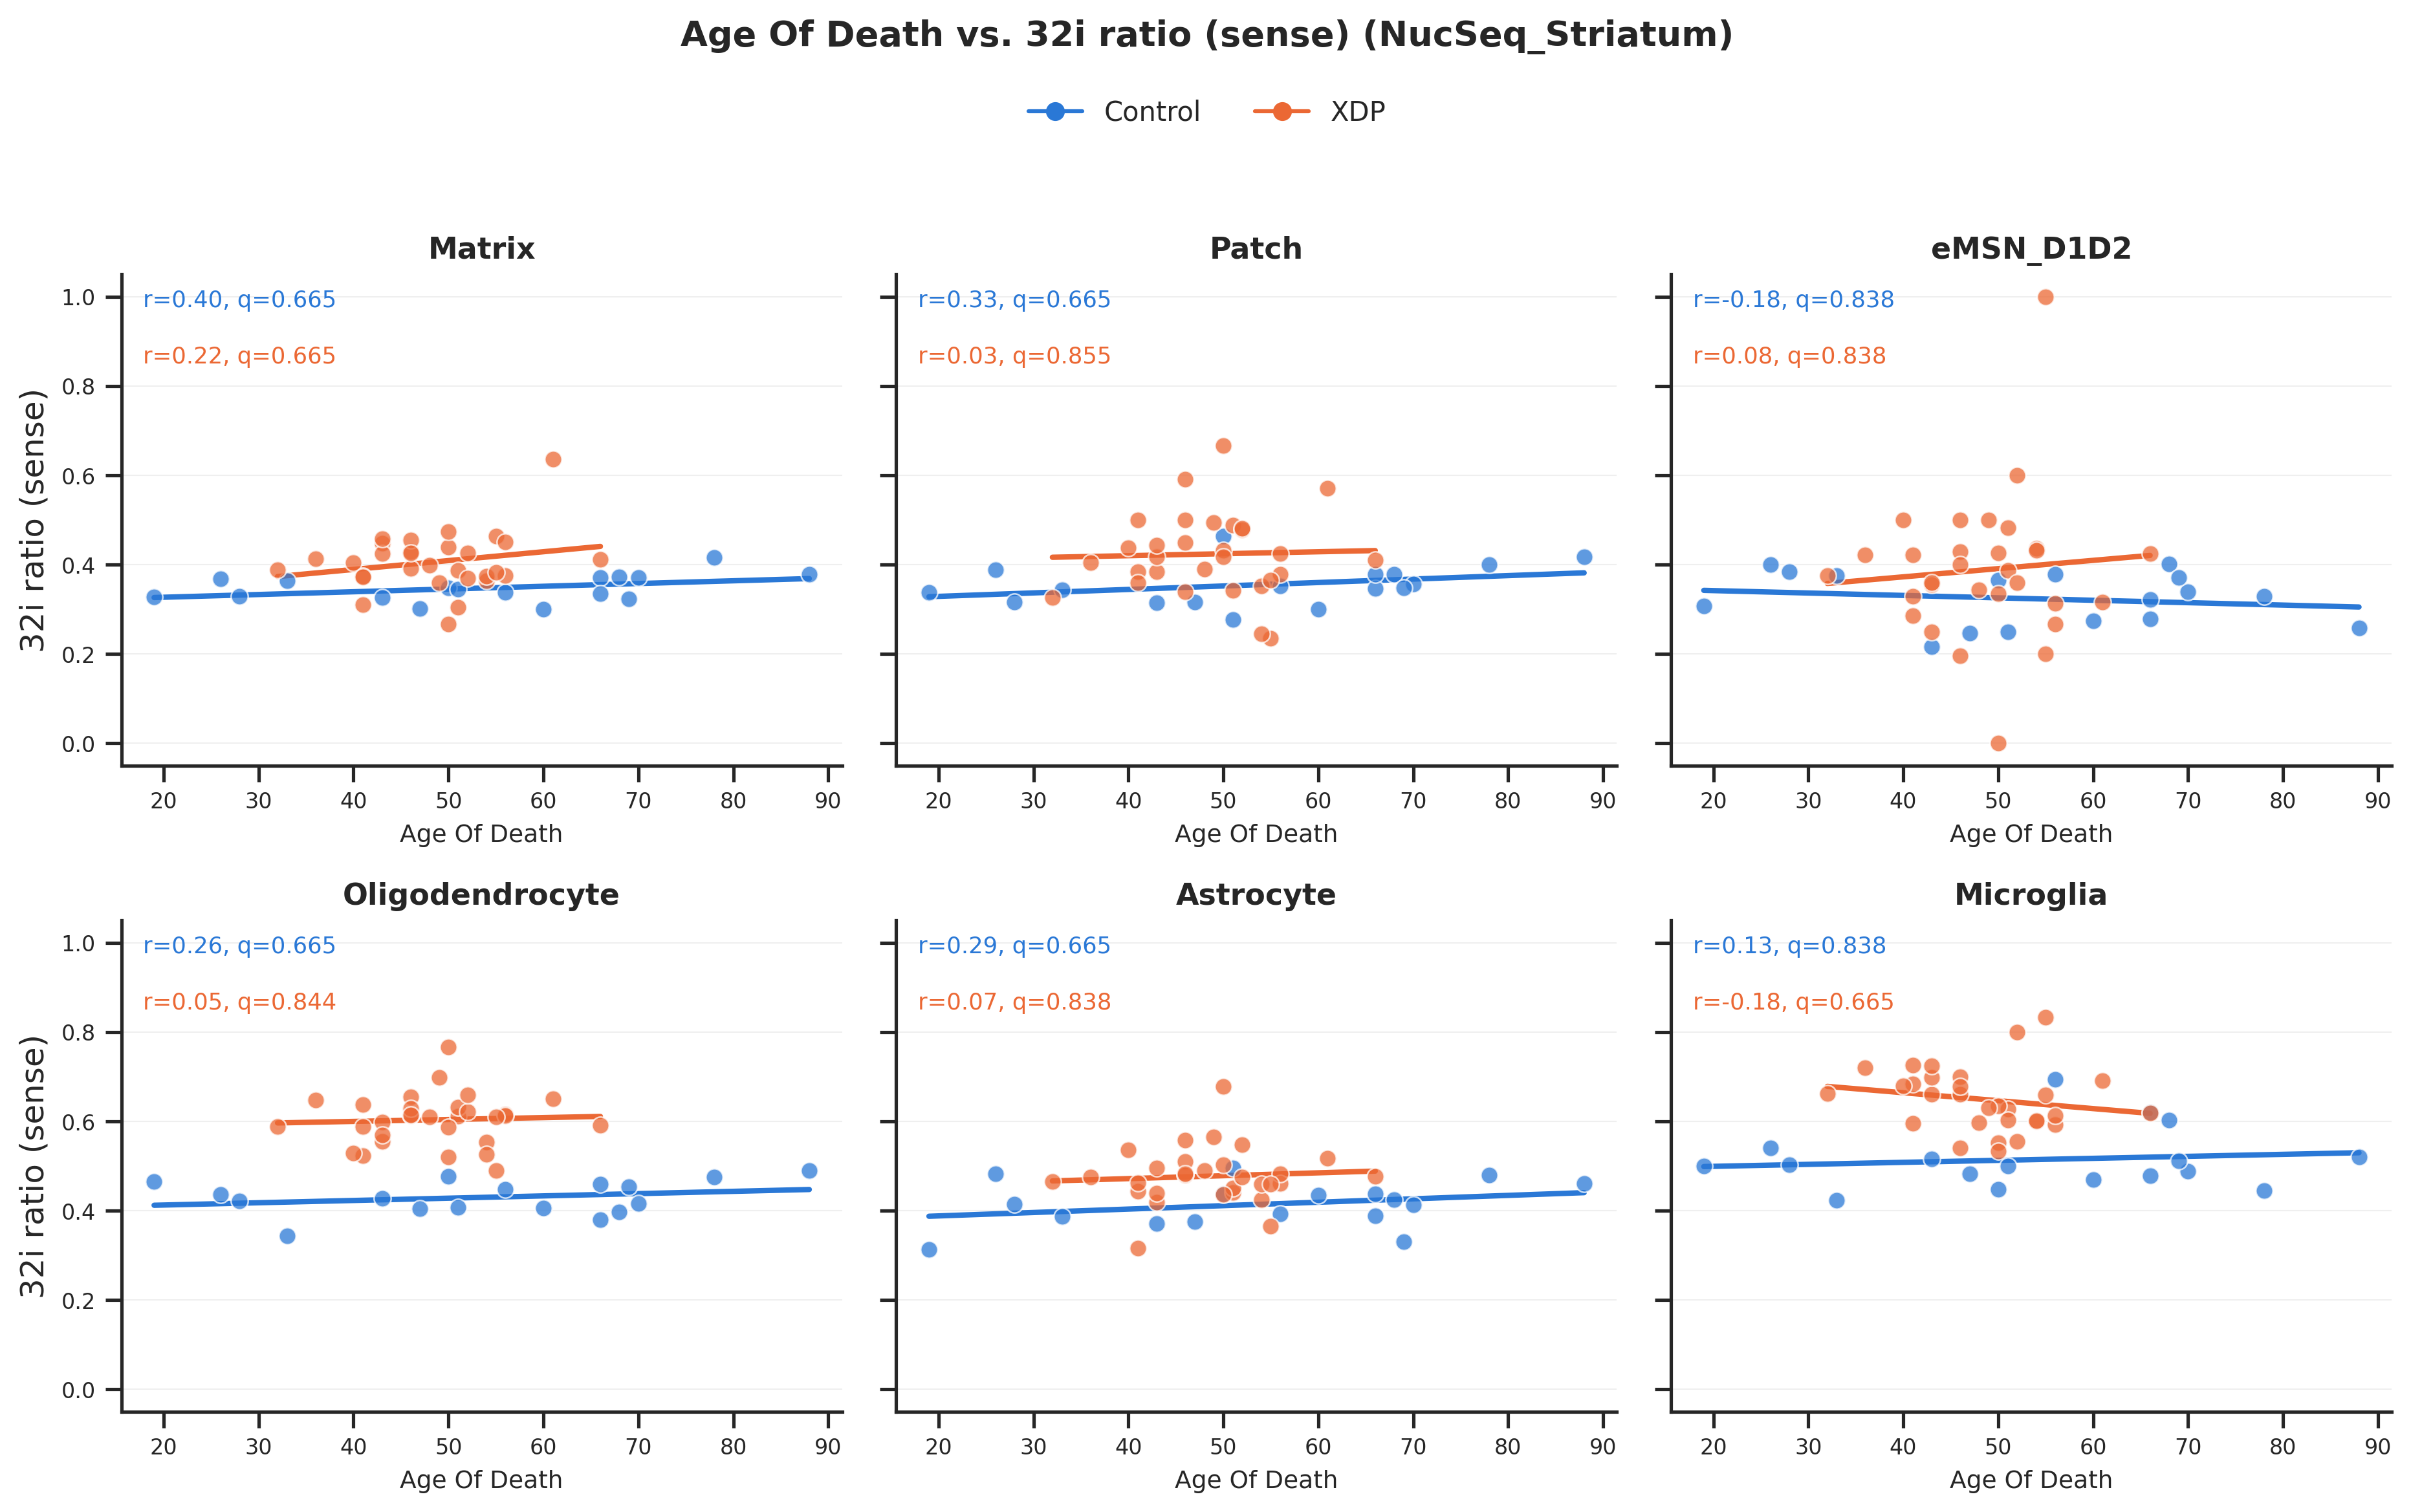

Pearson Correlation: Age_of_Death vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | Control    | Slope =  0.001 | r =  0.397 | p = 1.150e-01 | q(FDR) = 6.649e-01
Matrix               | XDP        | Slope =  0.002 | r =  0.223 | p = 2.360e-01 | q(FDR) = 6.649e-01
Patch                | Control    | Slope =  0.001 | r =  0.327 | p = 2.008e-01 | q(FDR) = 6.649e-01
Patch                | XDP        | Slope =  0.000 | r =  0.035 | p = 8.553e-01 | q(FDR) = 8.553e-01
eMSN_D1D2            | Control    | Slope = -0.001 | r = -0.175 | p = 5.012e-01 | q(FDR) = 8.378e-01
eMSN_D1D2            | XDP        | Slope =  0.002 | r =  0.083 | p = 6.628e-01 | q(FDR) = 8.378e-01
Oligodendrocyte      | Control    | Slope =  0.001 | r =  0.258 | p = 3.179e-01 | q(FDR) = 6.649e-01
Oligodendrocyte      | XDP        | Slope =  0.000 | r =  0.055 | p = 7.737e-01 | q(FDR) = 8.440e-01
Astrocyte            | Control    | Slope =  0.001 | r =  0.

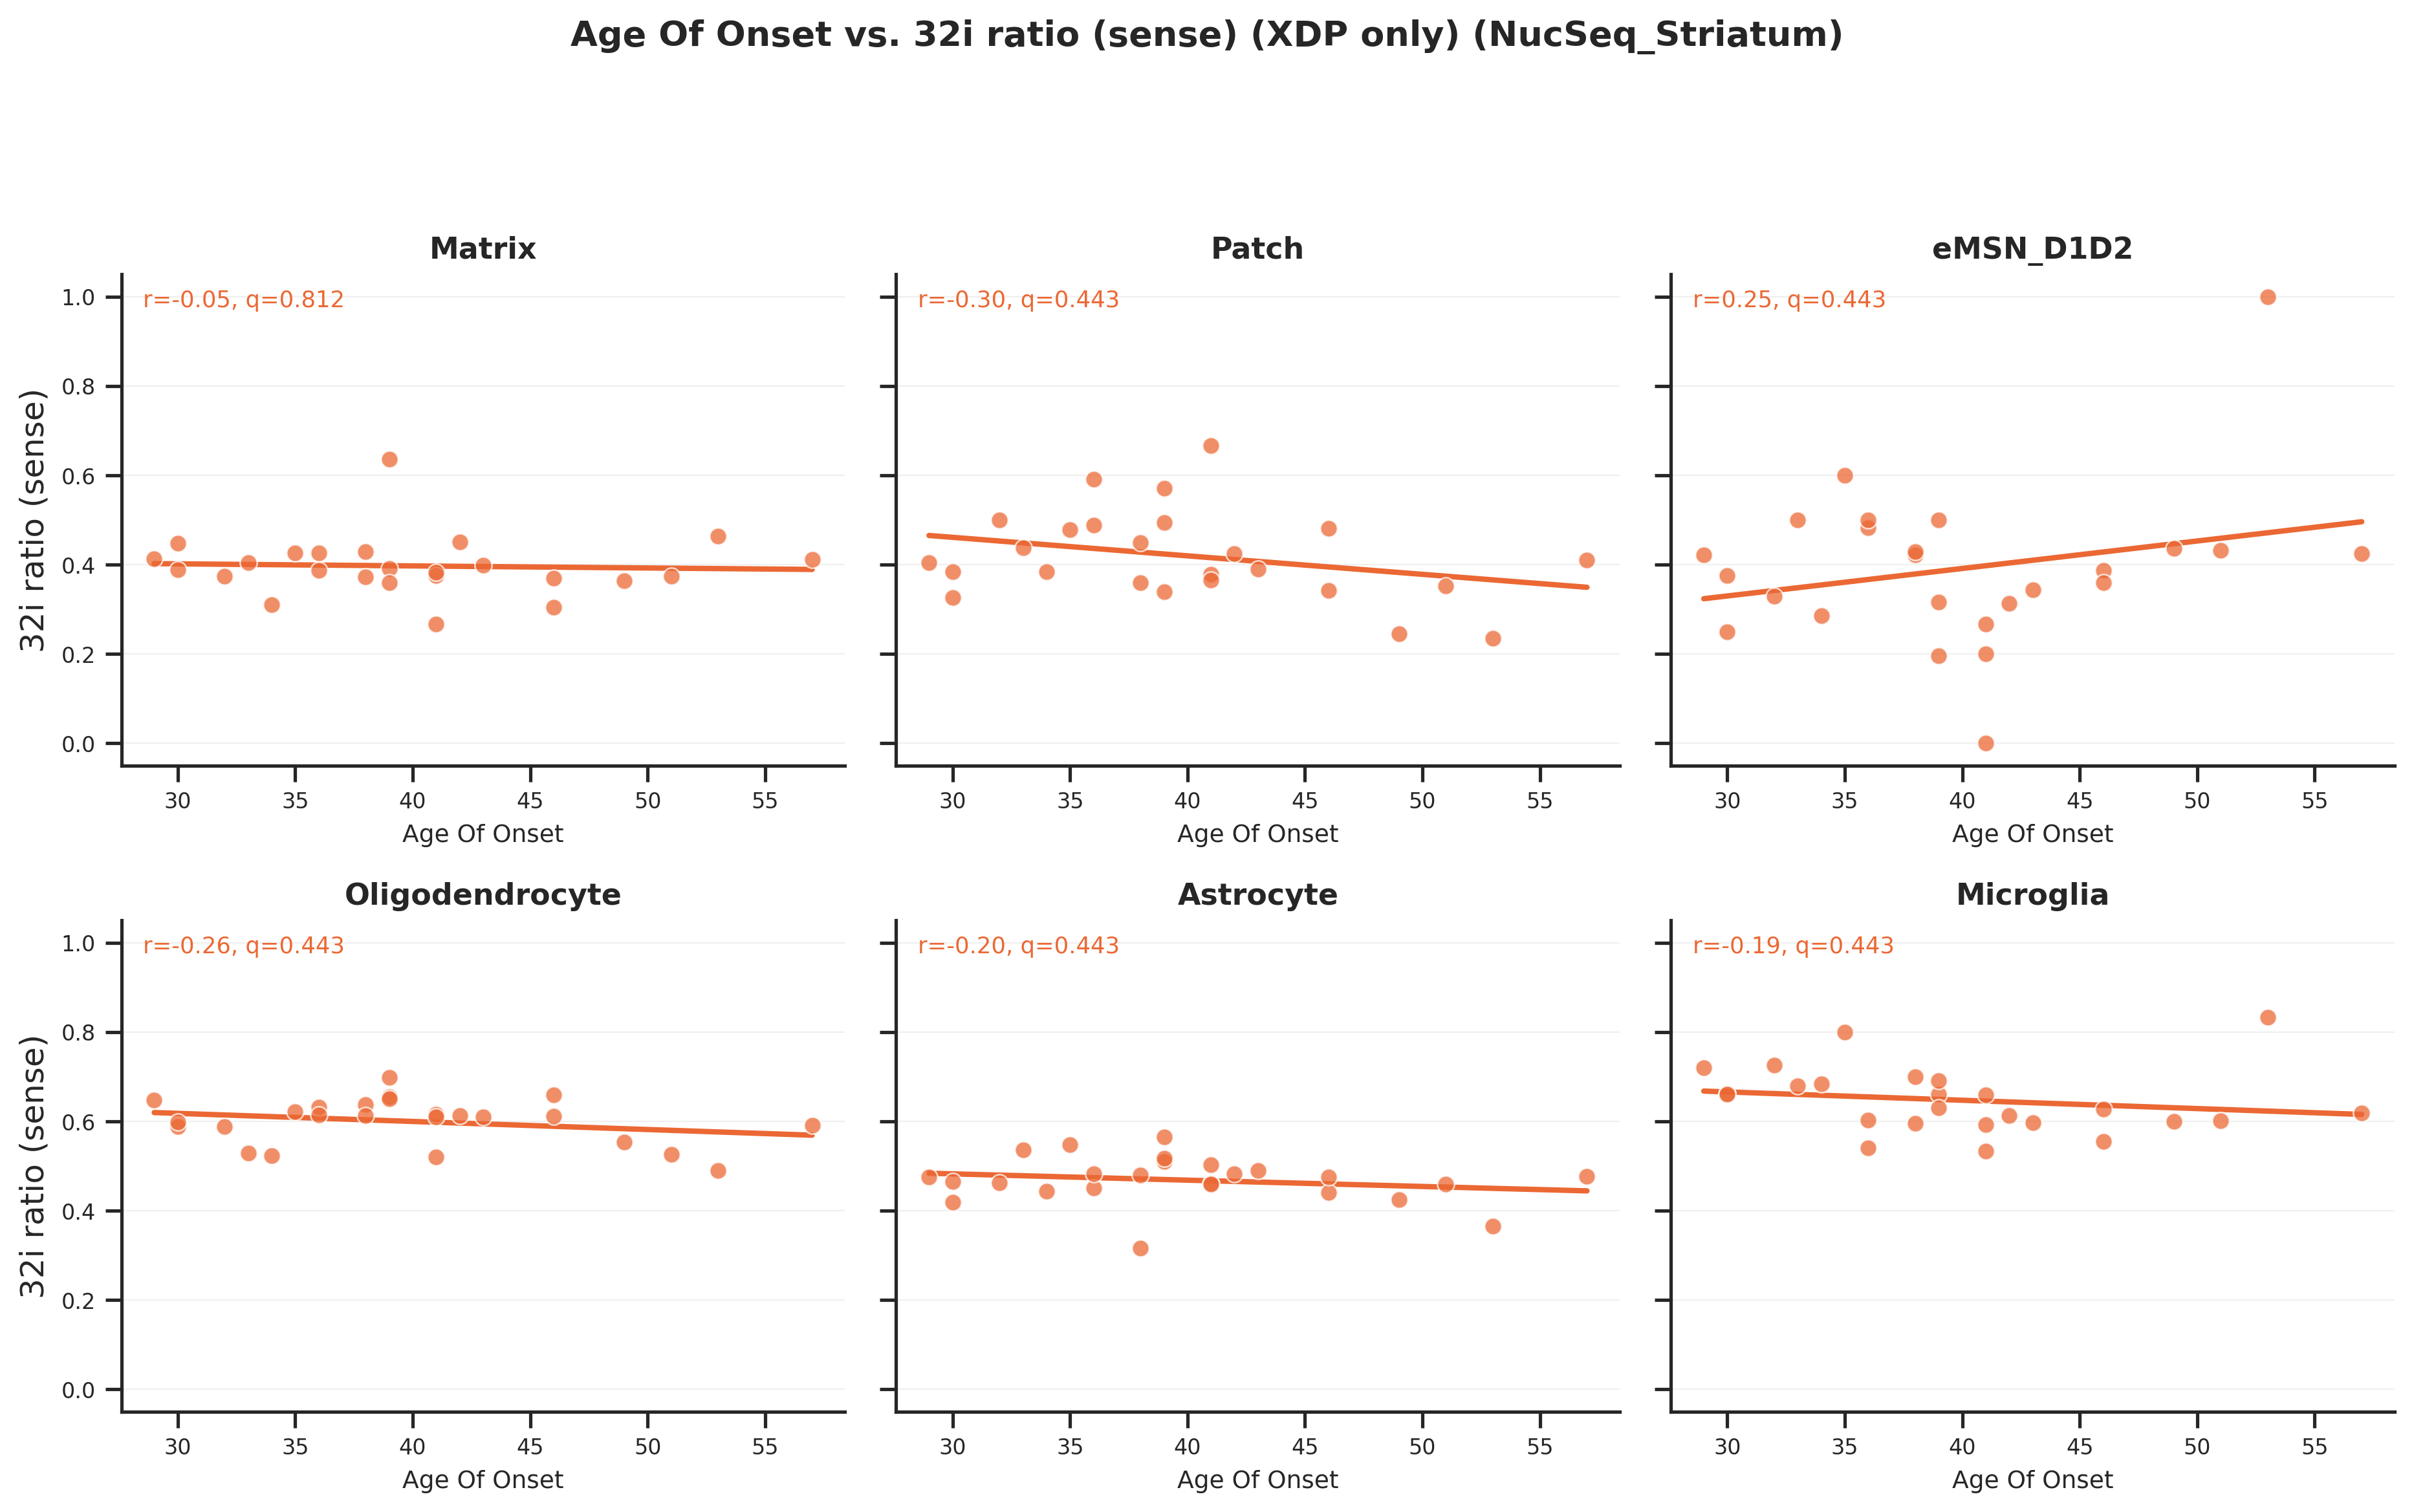

Pearson Correlation: Age_of_Onset vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope = -0.000 | r = -0.050 | p = 8.118e-01 | q(FDR) = 8.118e-01
Patch                | XDP        | Slope = -0.004 | r = -0.303 | p = 1.412e-01 | q(FDR) = 4.429e-01
eMSN_D1D2            | XDP        | Slope =  0.006 | r =  0.253 | p = 2.220e-01 | q(FDR) = 4.429e-01
Oligodendrocyte      | XDP        | Slope = -0.002 | r = -0.259 | p = 2.105e-01 | q(FDR) = 4.429e-01
Astrocyte            | XDP        | Slope = -0.001 | r = -0.196 | p = 3.479e-01 | q(FDR) = 4.429e-01
Microglia            | XDP        | Slope = -0.002 | r = -0.188 | p = 3.691e-01 | q(FDR) = 4.429e-01

Analyzing covariate: repeat_length


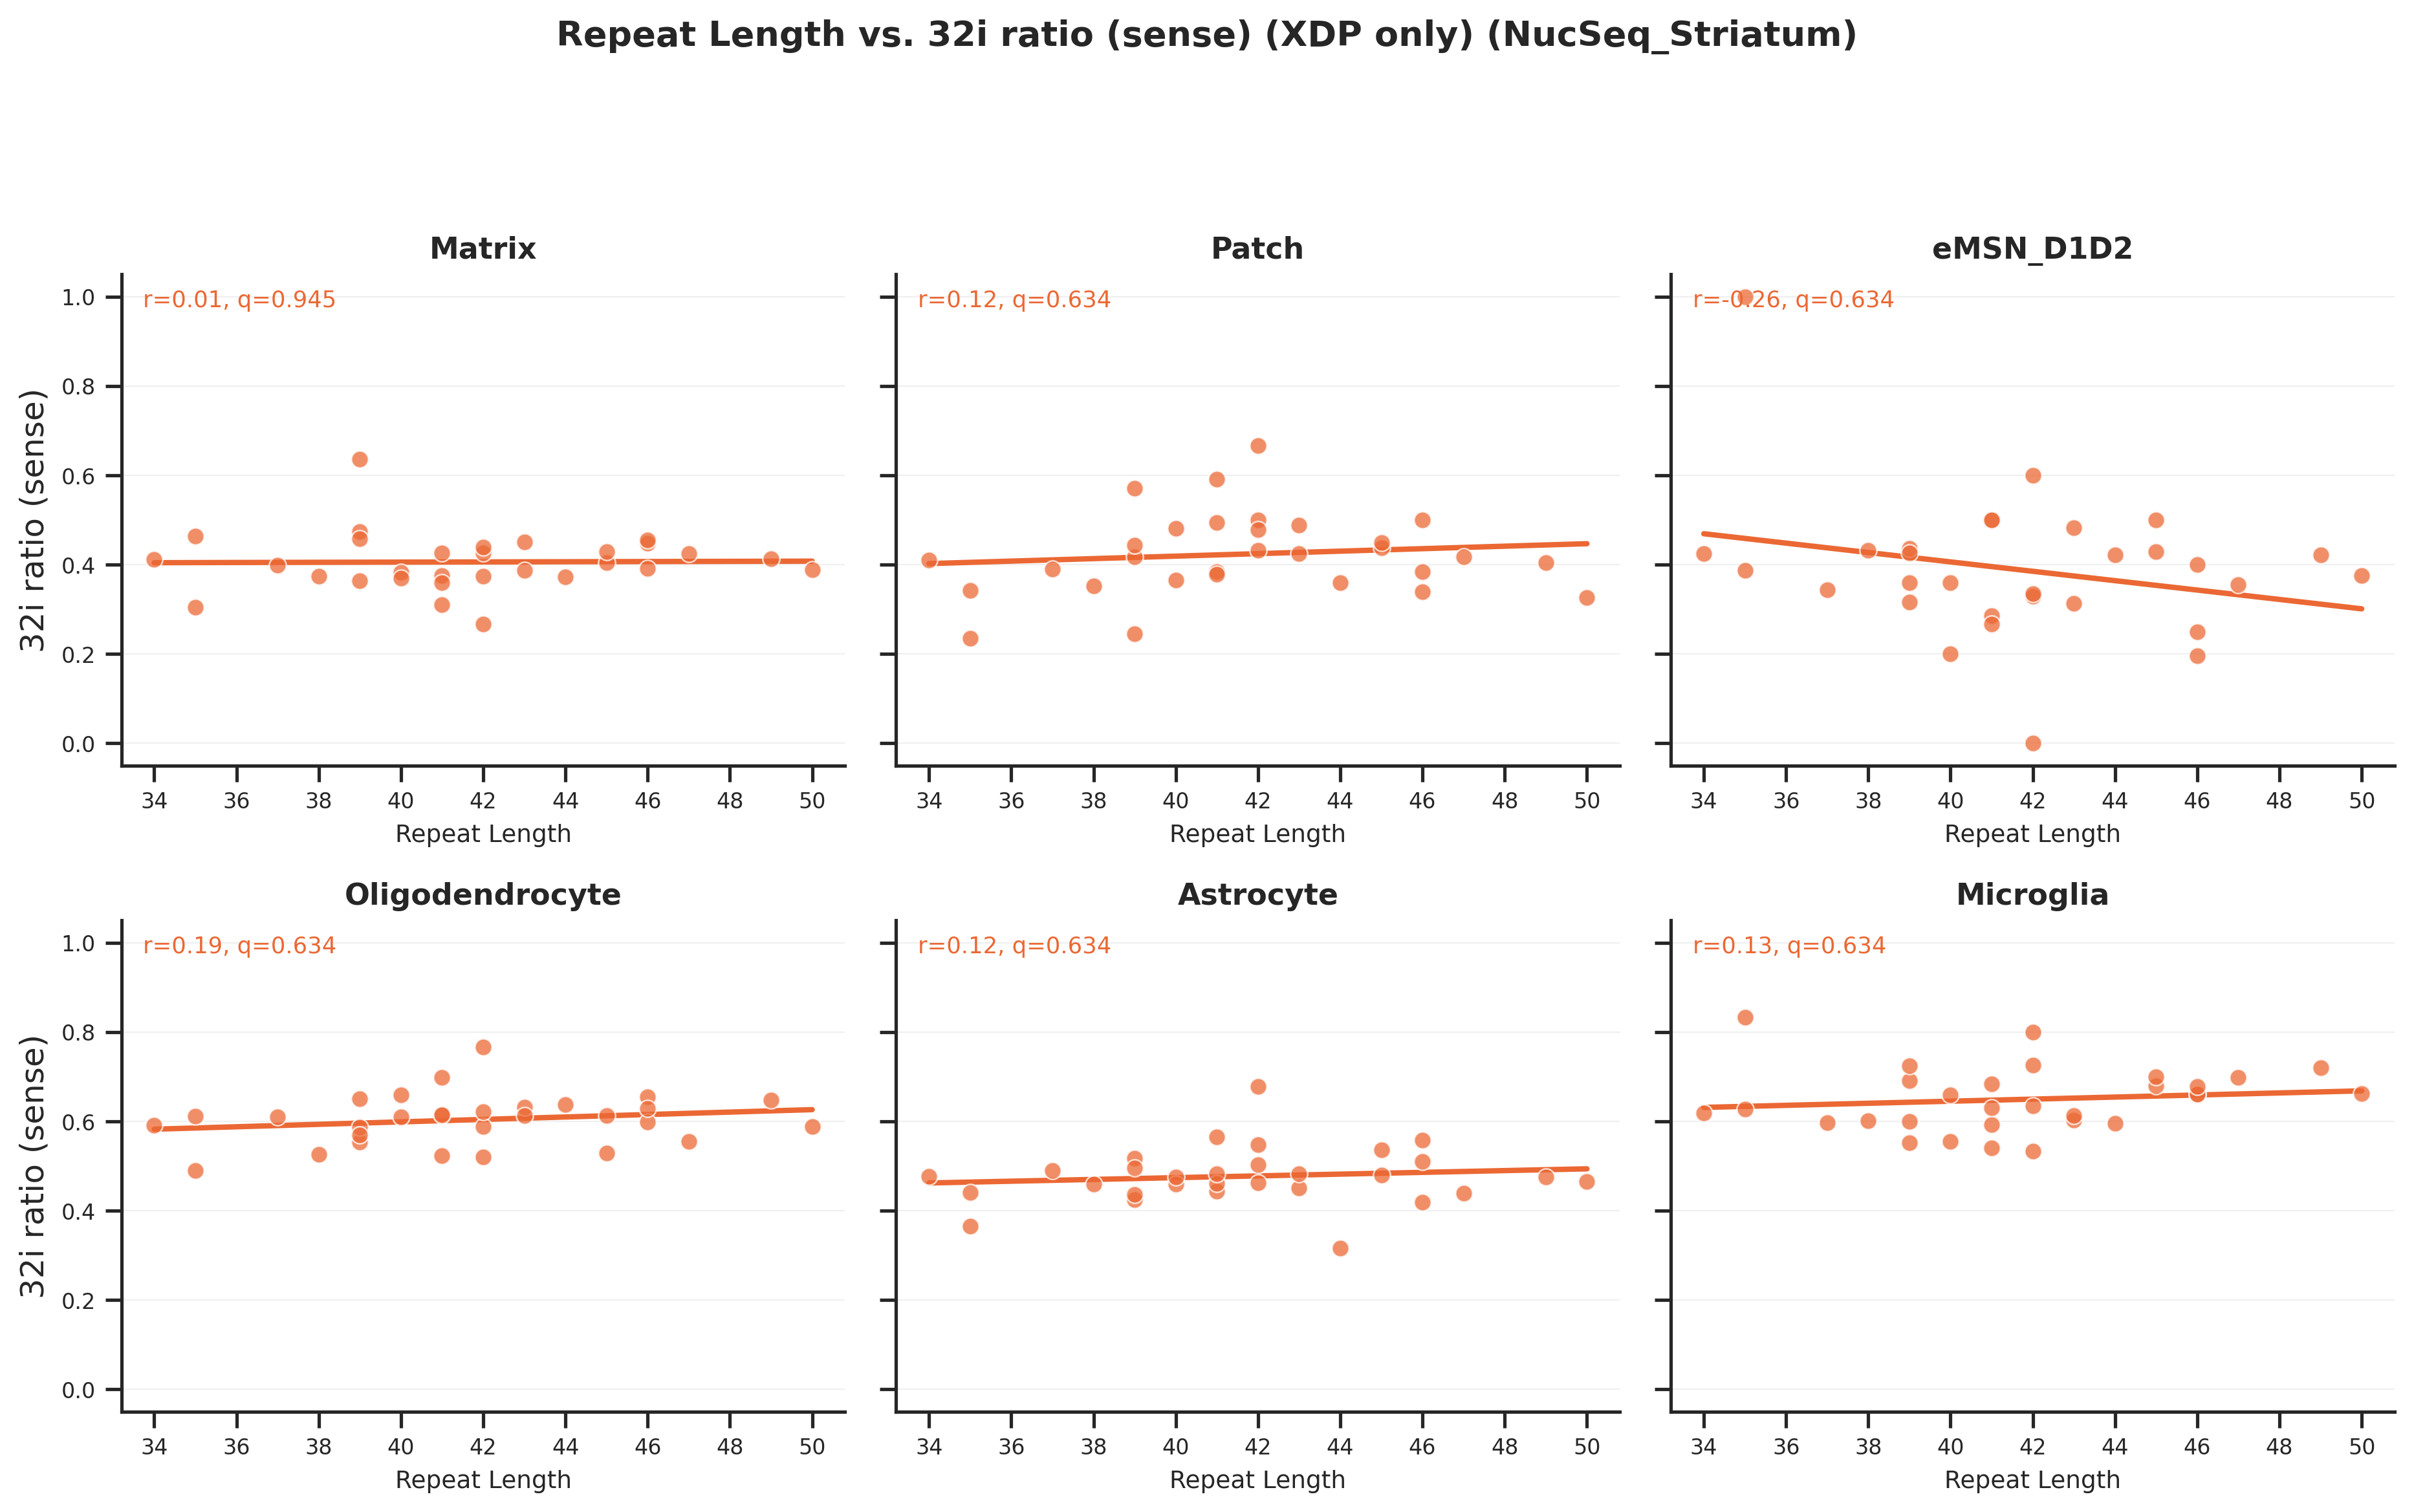

Pearson Correlation: repeat_length vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.000 | r =  0.013 | p = 9.449e-01 | q(FDR) = 9.449e-01
Patch                | XDP        | Slope =  0.003 | r =  0.120 | p = 5.280e-01 | q(FDR) = 6.336e-01
eMSN_D1D2            | XDP        | Slope = -0.011 | r = -0.257 | p = 1.705e-01 | q(FDR) = 6.336e-01
Oligodendrocyte      | XDP        | Slope =  0.003 | r =  0.191 | p = 3.108e-01 | q(FDR) = 6.336e-01
Astrocyte            | XDP        | Slope =  0.002 | r =  0.123 | p = 5.182e-01 | q(FDR) = 6.336e-01
Microglia            | XDP        | Slope =  0.002 | r =  0.130 | p = 4.940e-01 | q(FDR) = 6.336e-01

Analyzing covariate: Disease_duration


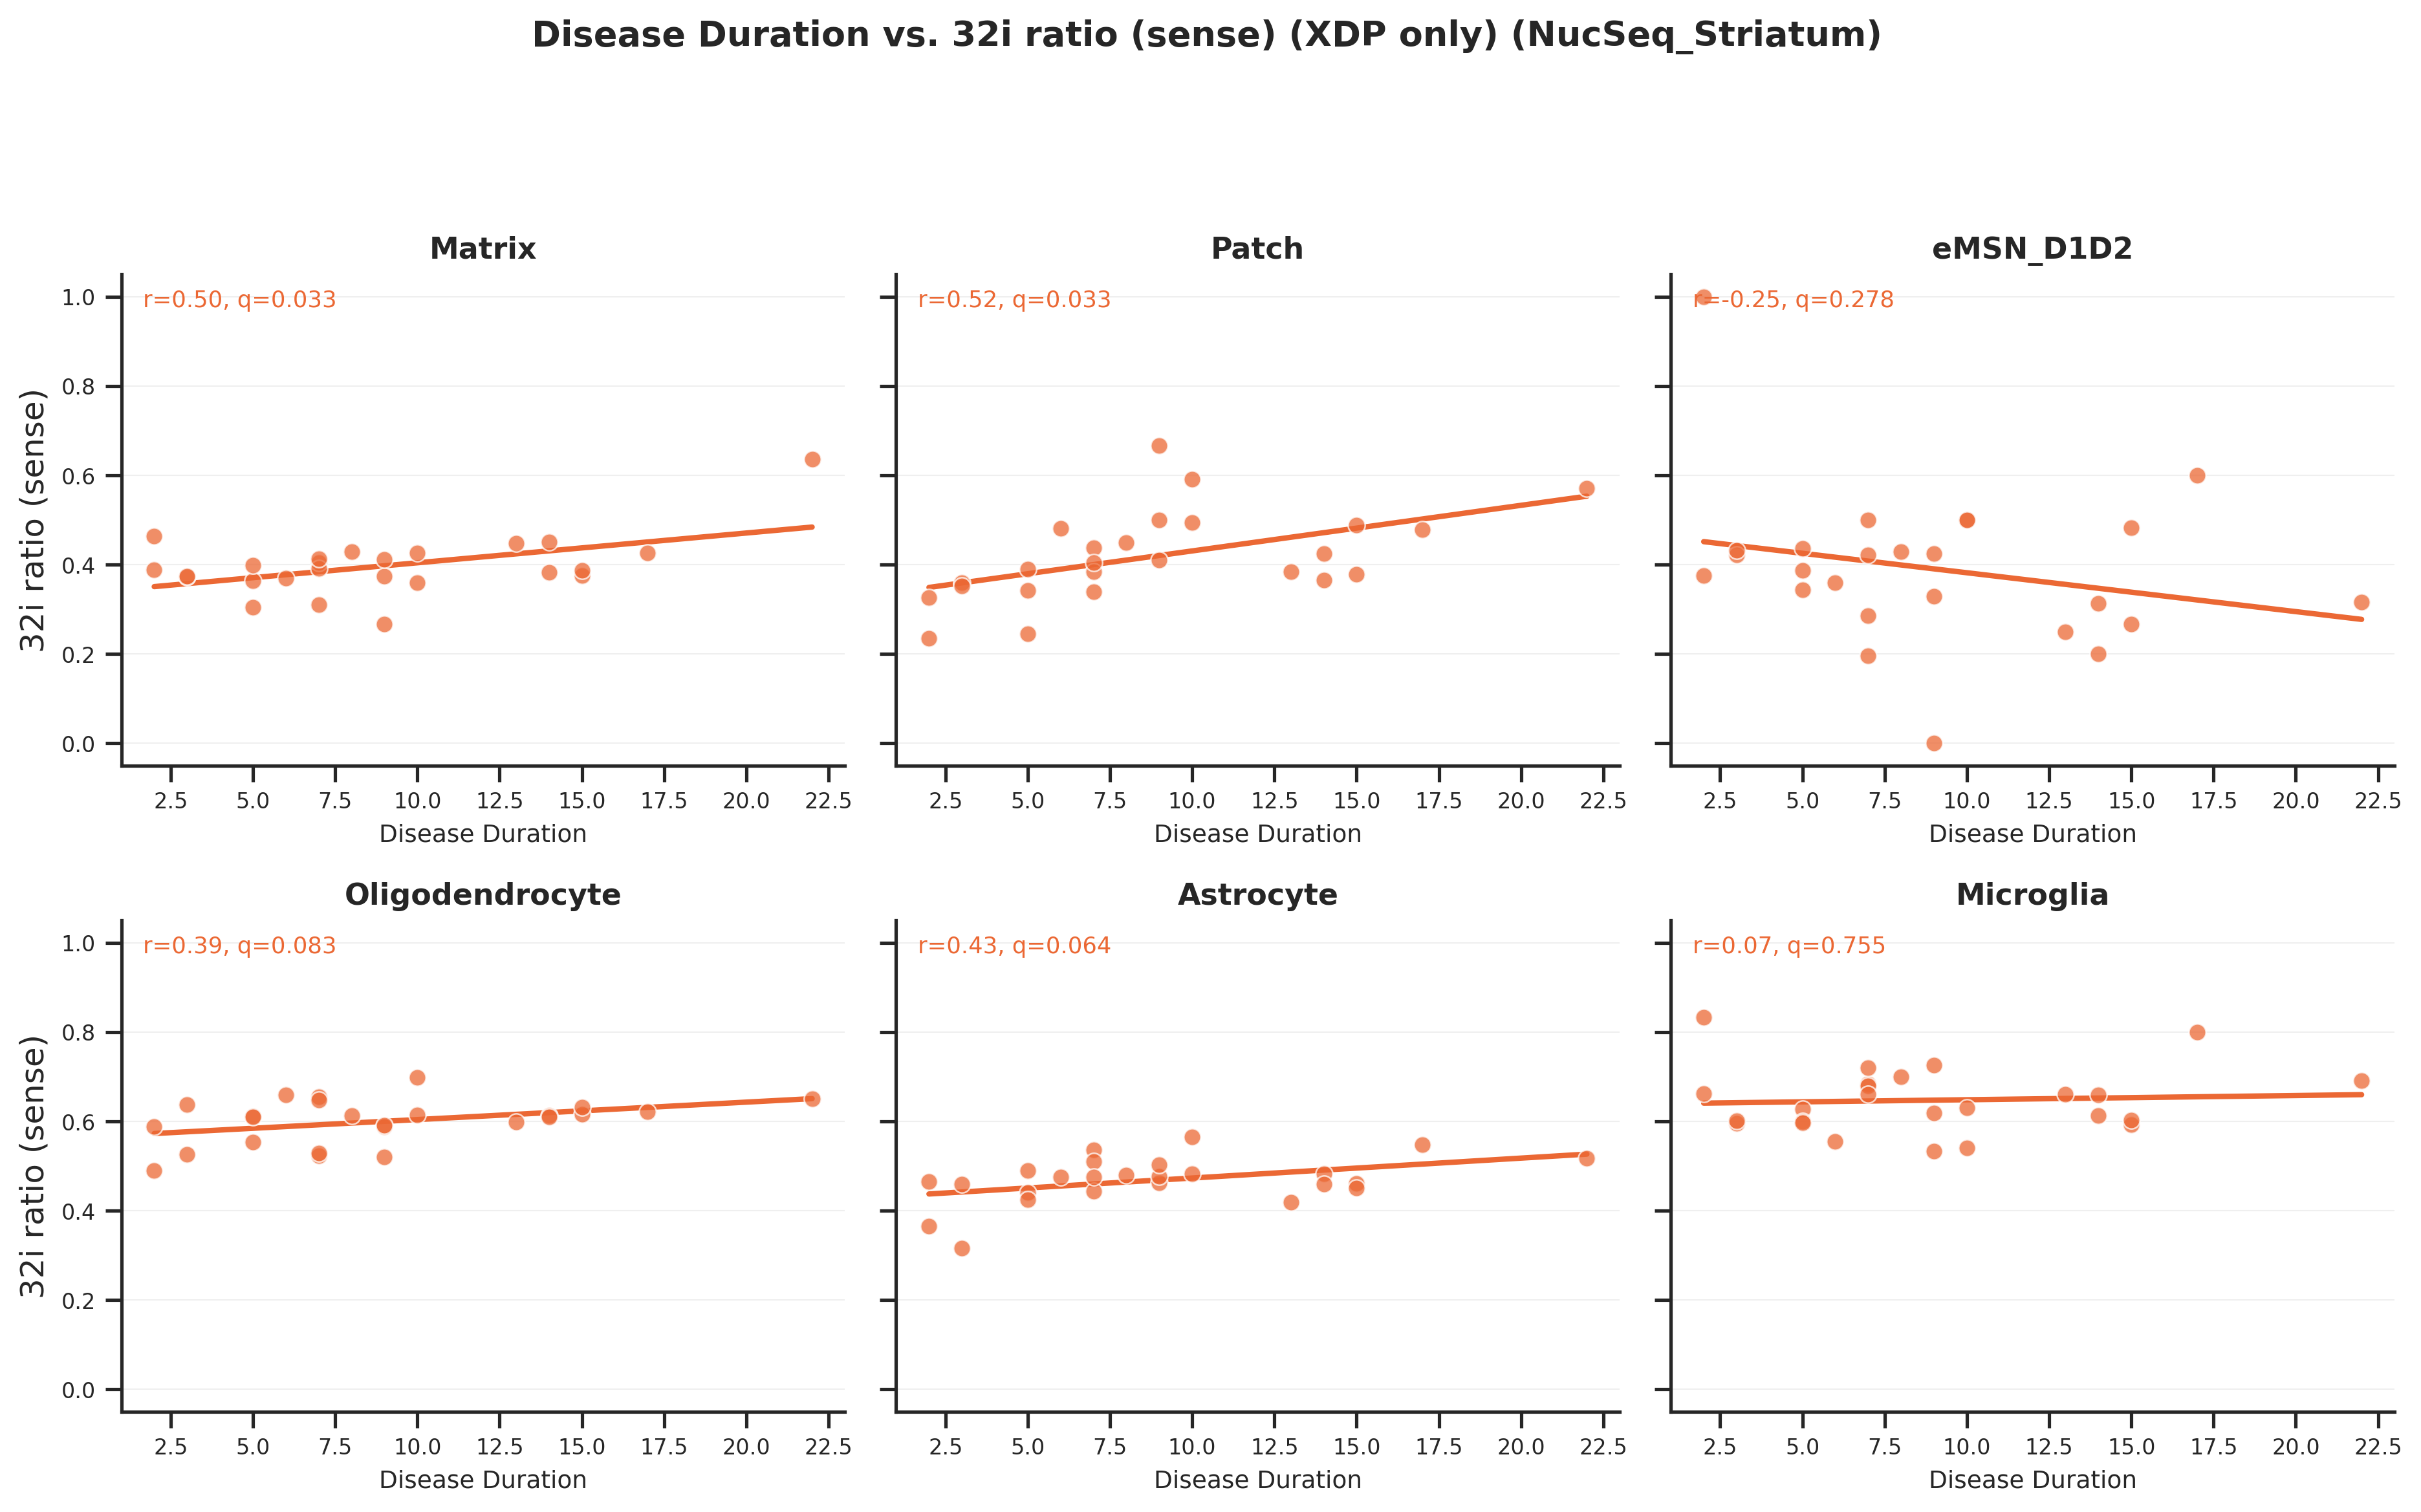

Pearson Correlation: Disease_duration vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.007 | r =  0.500 | p = 1.083e-02 | q(FDR) = 3.250e-02
Patch                | XDP        | Slope =  0.010 | r =  0.517 | p = 8.096e-03 | q(FDR) = 3.250e-02
eMSN_D1D2            | XDP        | Slope = -0.009 | r = -0.248 | p = 2.320e-01 | q(FDR) = 2.784e-01
Oligodendrocyte      | XDP        | Slope =  0.004 | r =  0.388 | p = 5.539e-02 | q(FDR) = 8.308e-02
Astrocyte            | XDP        | Slope =  0.004 | r =  0.430 | p = 3.209e-02 | q(FDR) = 6.418e-02
Microglia            | XDP        | Slope =  0.001 | r =  0.066 | p = 7.545e-01 | q(FDR) = 7.545e-01

Analyzing covariate: Age_of_Death


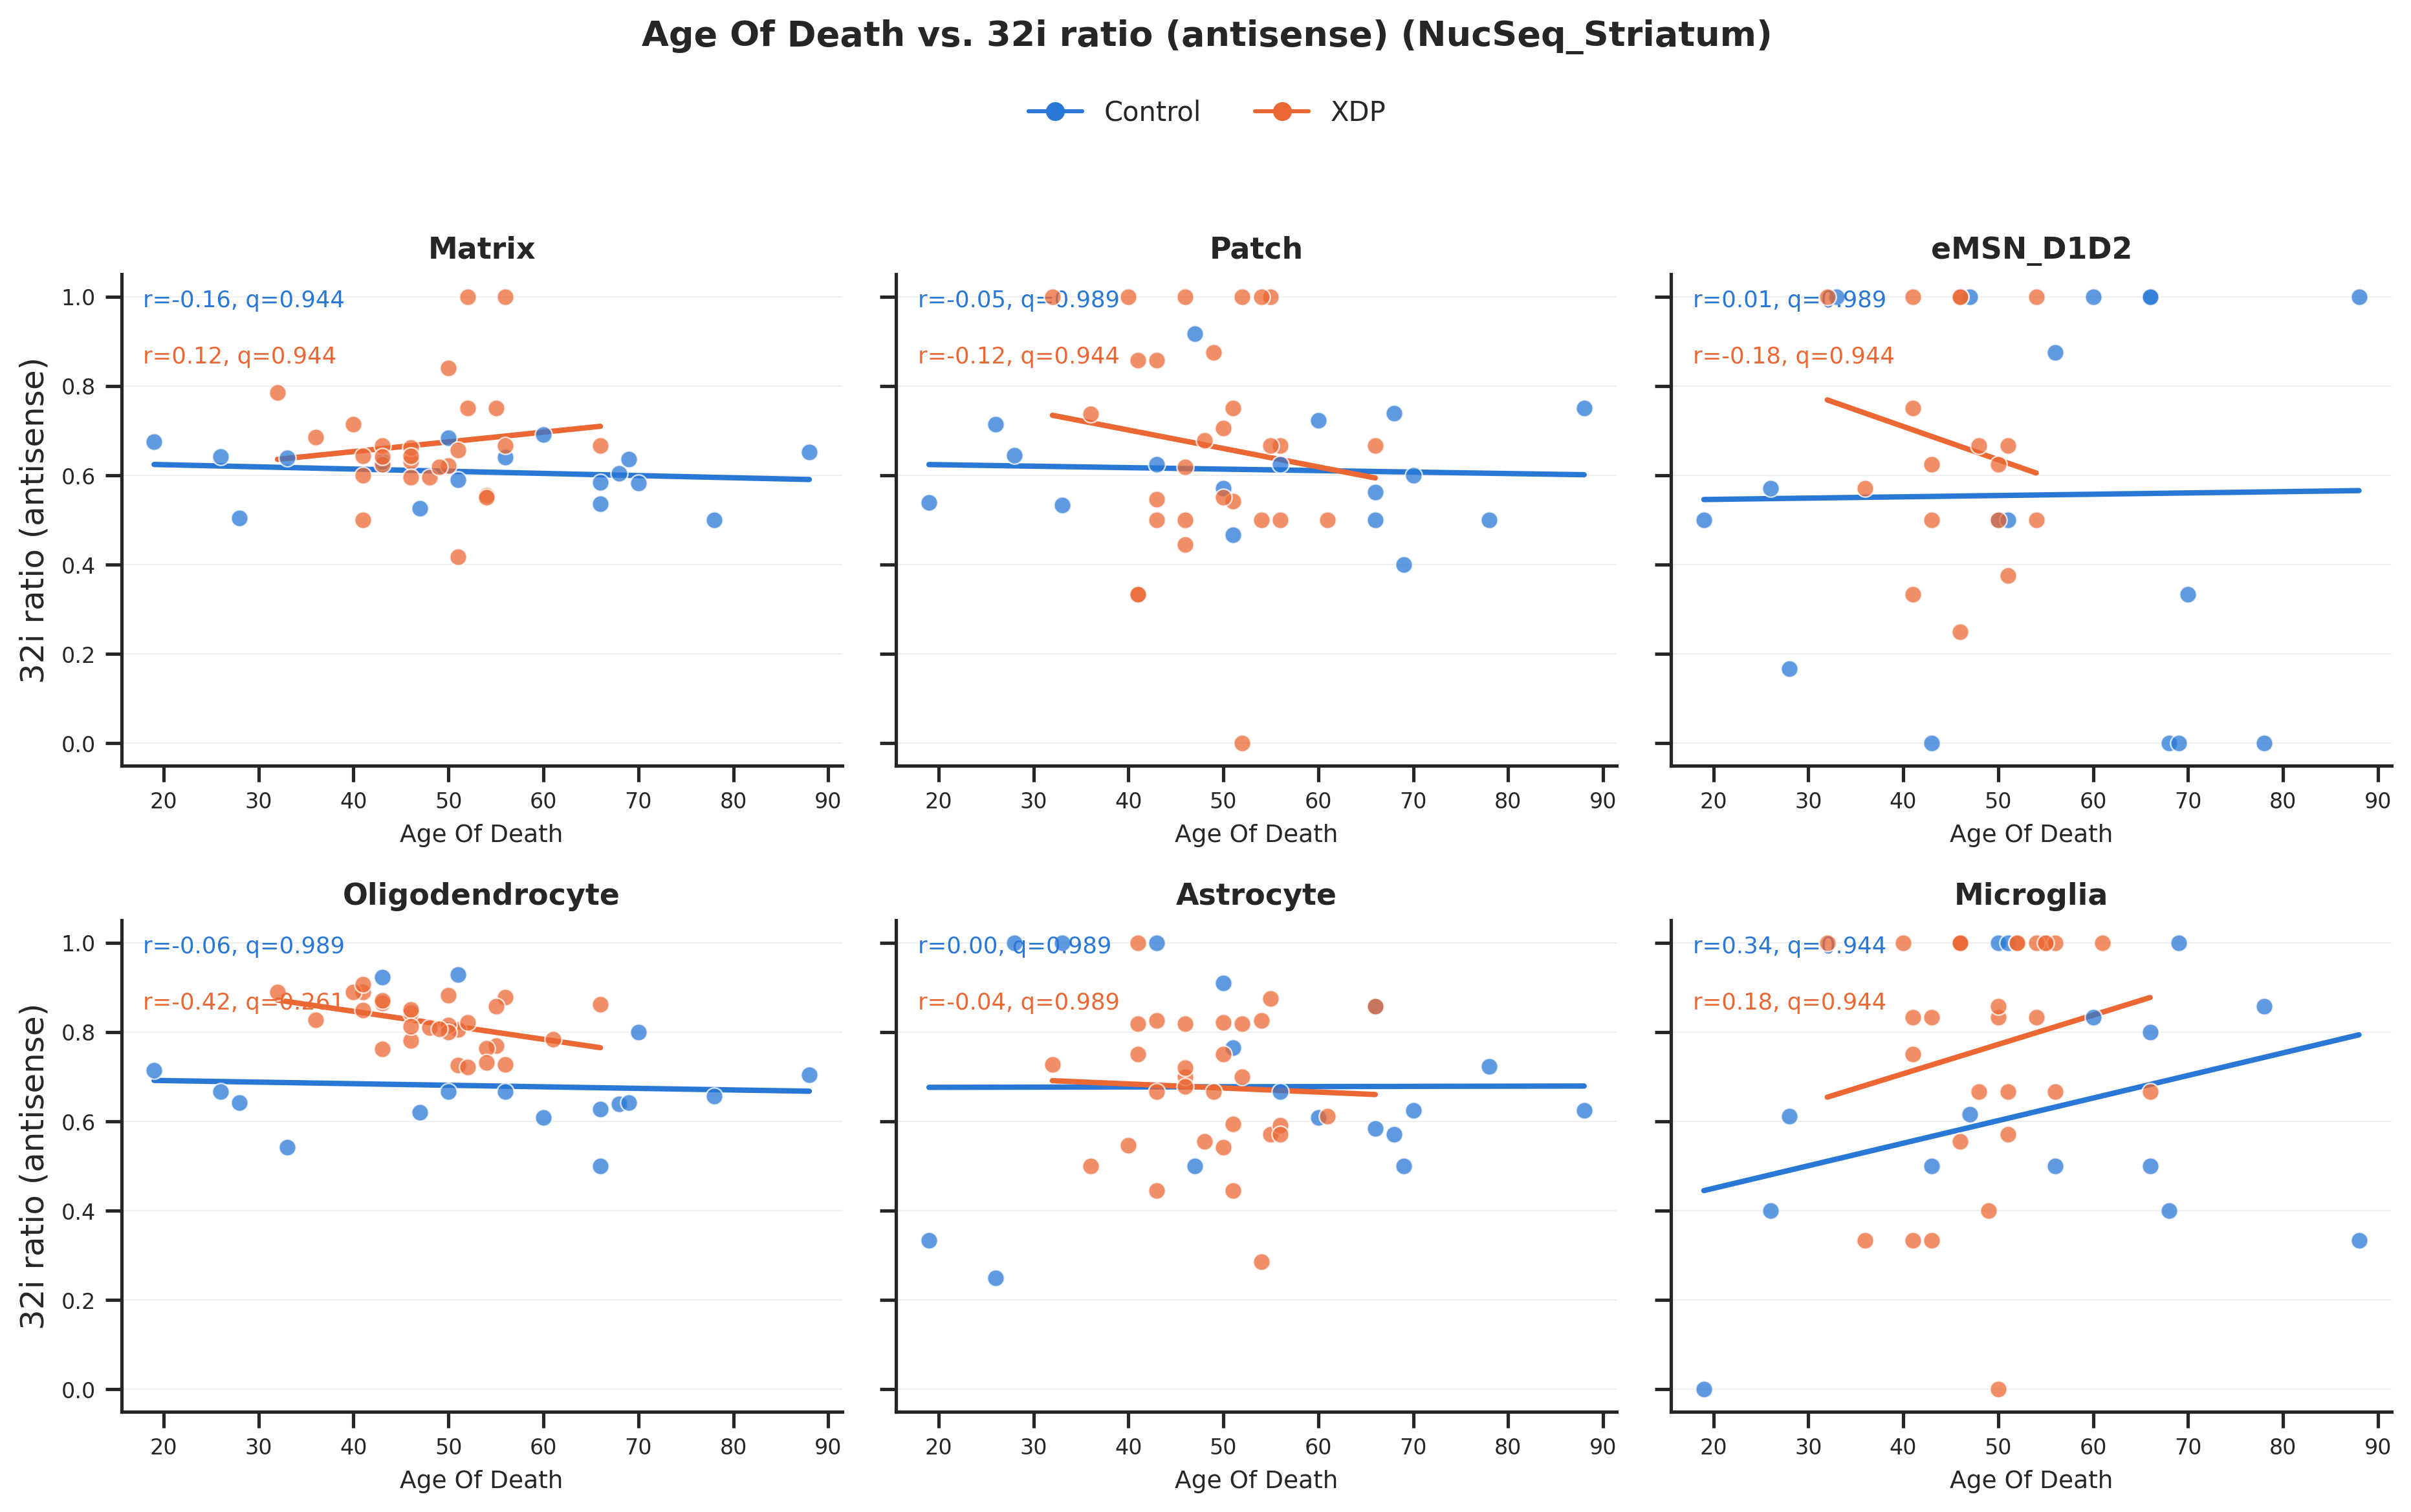

Pearson Correlation: Age_of_Death vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | Control    | Slope = -0.000 | r = -0.156 | p = 5.504e-01 | q(FDR) = 9.436e-01
Matrix               | XDP        | Slope =  0.002 | r =  0.122 | p = 5.440e-01 | q(FDR) = 9.436e-01
Patch                | Control    | Slope = -0.000 | r = -0.050 | p = 8.476e-01 | q(FDR) = 9.888e-01
Patch                | XDP        | Slope = -0.004 | r = -0.125 | p = 5.196e-01 | q(FDR) = 9.436e-01
eMSN_D1D2            | Control    | Slope =  0.000 | r =  0.014 | p = 9.587e-01 | q(FDR) = 9.888e-01
eMSN_D1D2            | XDP        | Slope = -0.007 | r = -0.179 | p = 4.909e-01 | q(FDR) = 9.436e-01
Oligodendrocyte      | Control    | Slope = -0.000 | r = -0.060 | p = 8.187e-01 | q(FDR) = 9.888e-01
Oligodendrocyte      | XDP        | Slope = -0.003 | r = -0.417 | p = 2.175e-02 | q(FDR) = 2.610e-01
Astrocyte            | Control    | Slope =  0.000 | r =

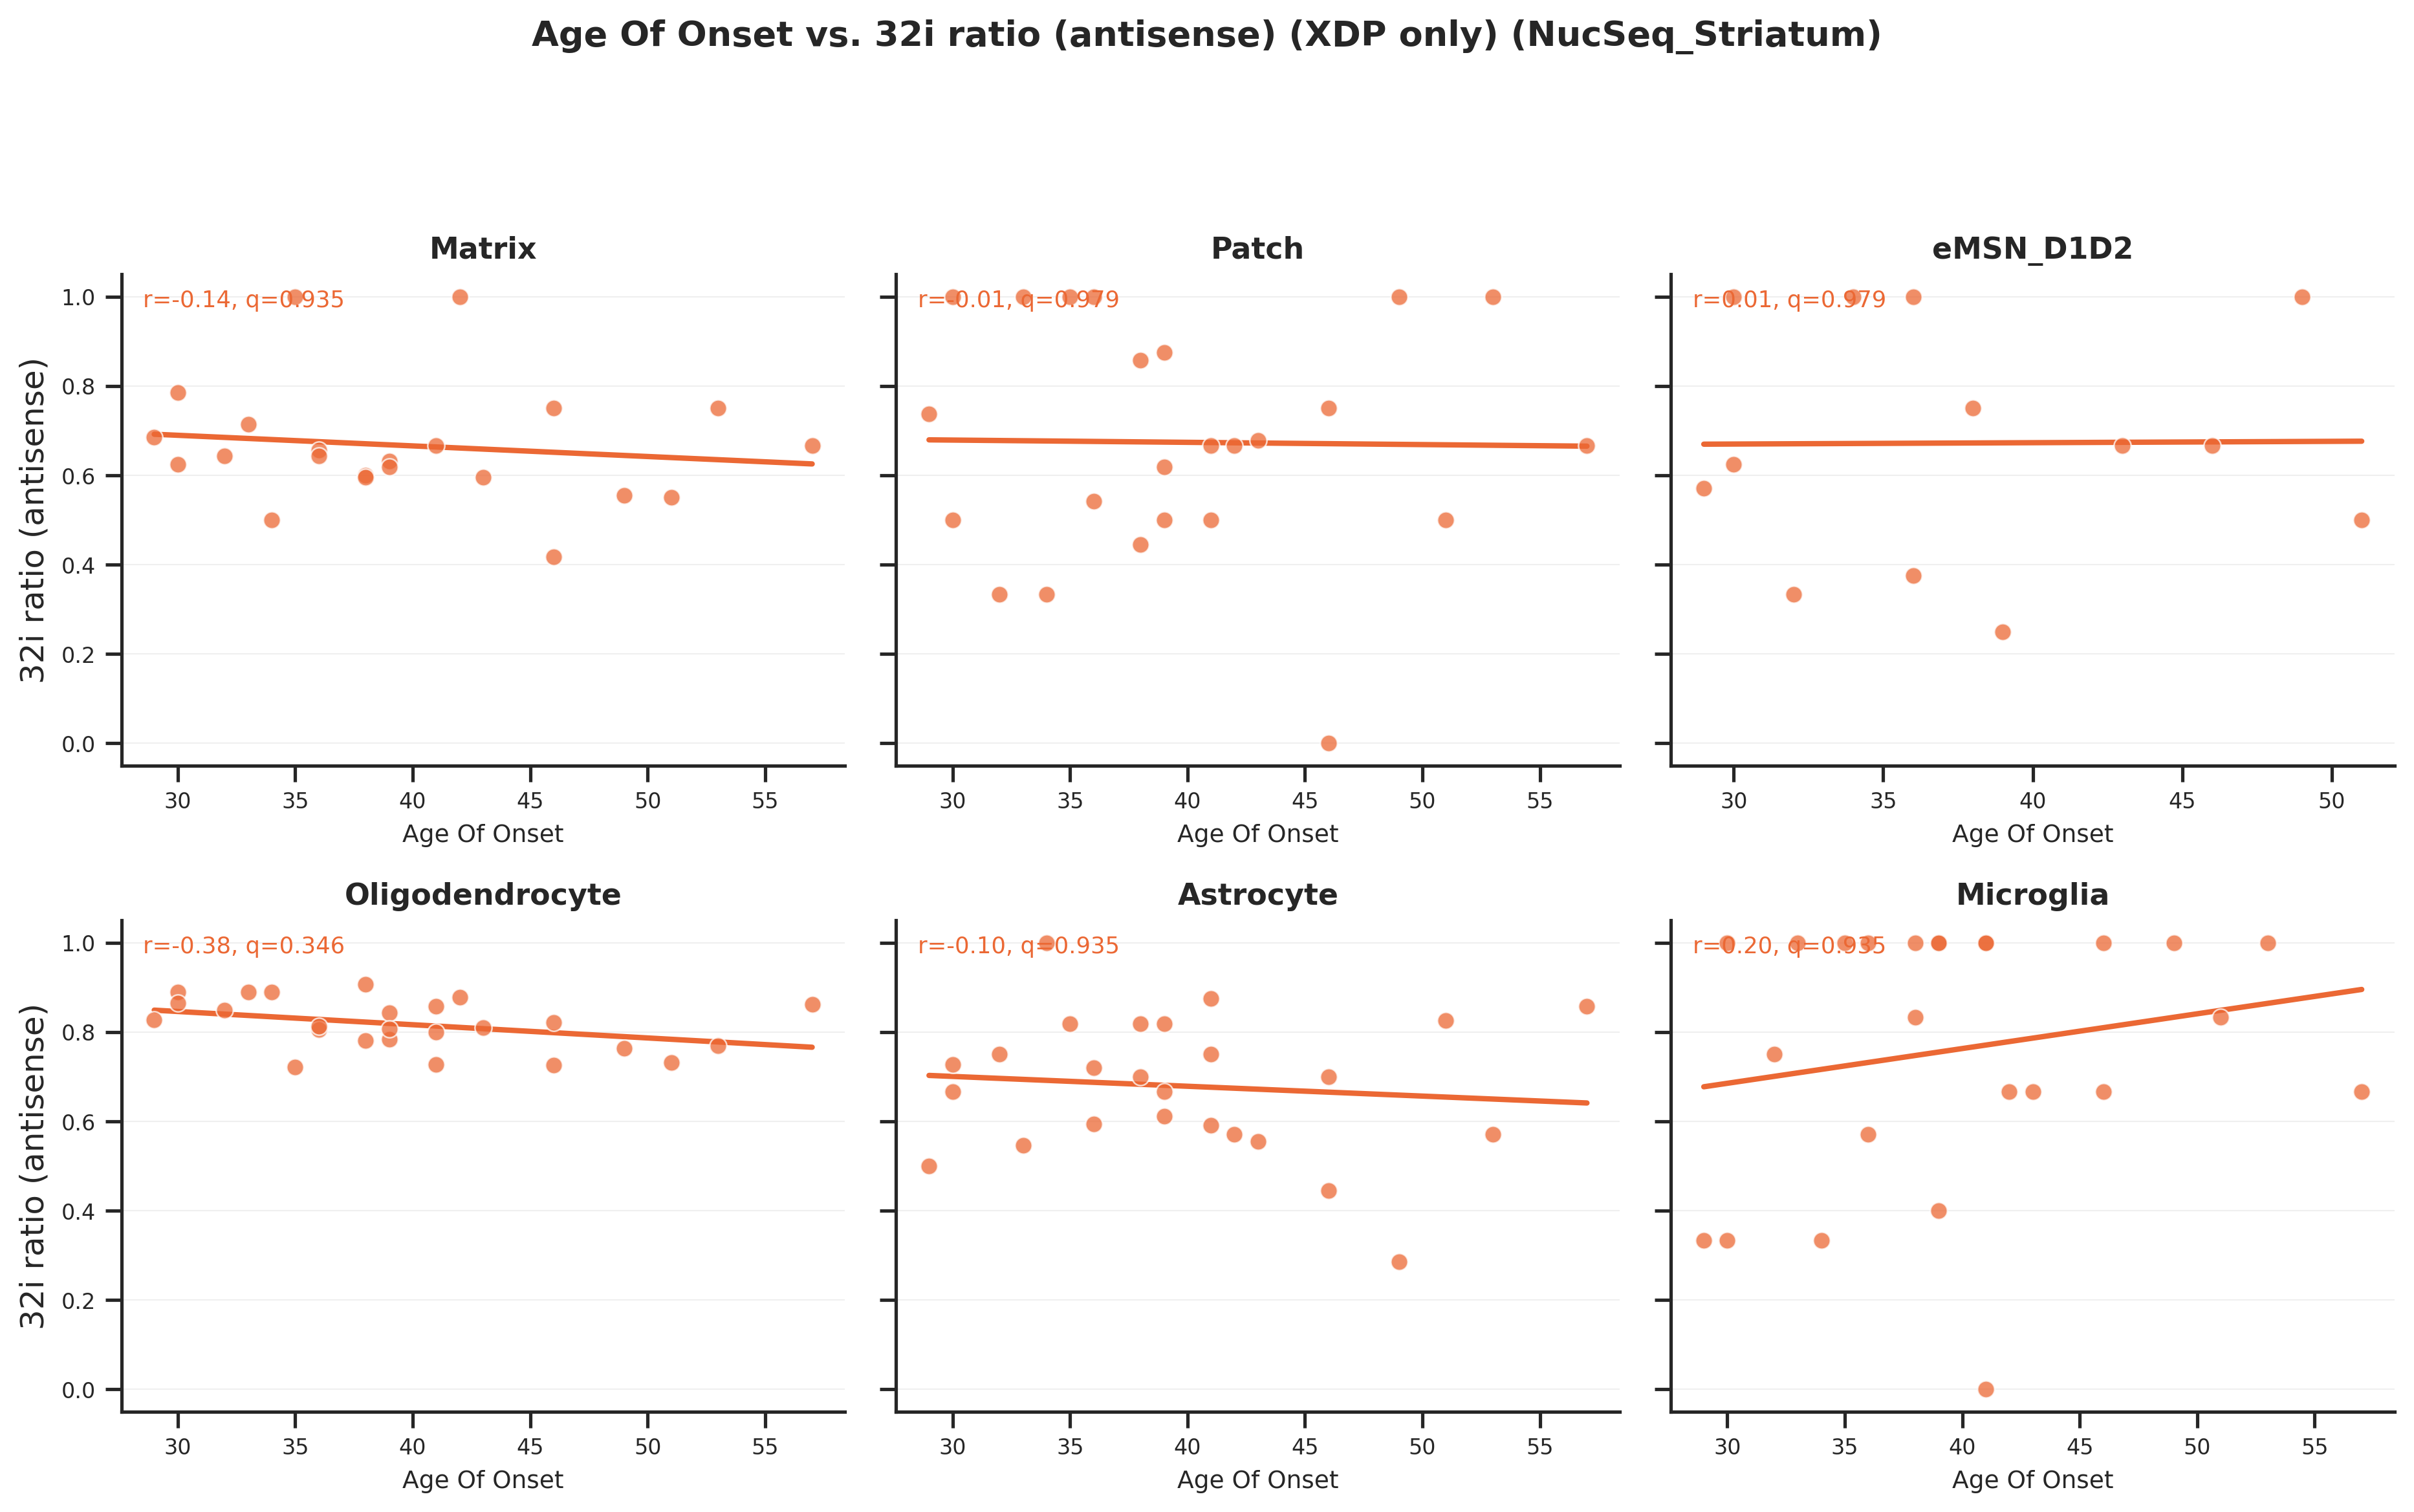

Pearson Correlation: Age_of_Onset vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope = -0.002 | r = -0.136 | p = 5.456e-01 | q(FDR) = 9.353e-01
Patch                | XDP        | Slope = -0.001 | r = -0.014 | p = 9.471e-01 | q(FDR) = 9.785e-01
eMSN_D1D2            | XDP        | Slope =  0.000 | r =  0.008 | p = 9.785e-01 | q(FDR) = 9.785e-01
Oligodendrocyte      | XDP        | Slope = -0.003 | r = -0.385 | p = 5.772e-02 | q(FDR) = 3.463e-01
Astrocyte            | XDP        | Slope = -0.002 | r = -0.103 | p = 6.236e-01 | q(FDR) = 9.353e-01
Microglia            | XDP        | Slope =  0.008 | r =  0.196 | p = 3.476e-01 | q(FDR) = 9.353e-01

Analyzing covariate: repeat_length


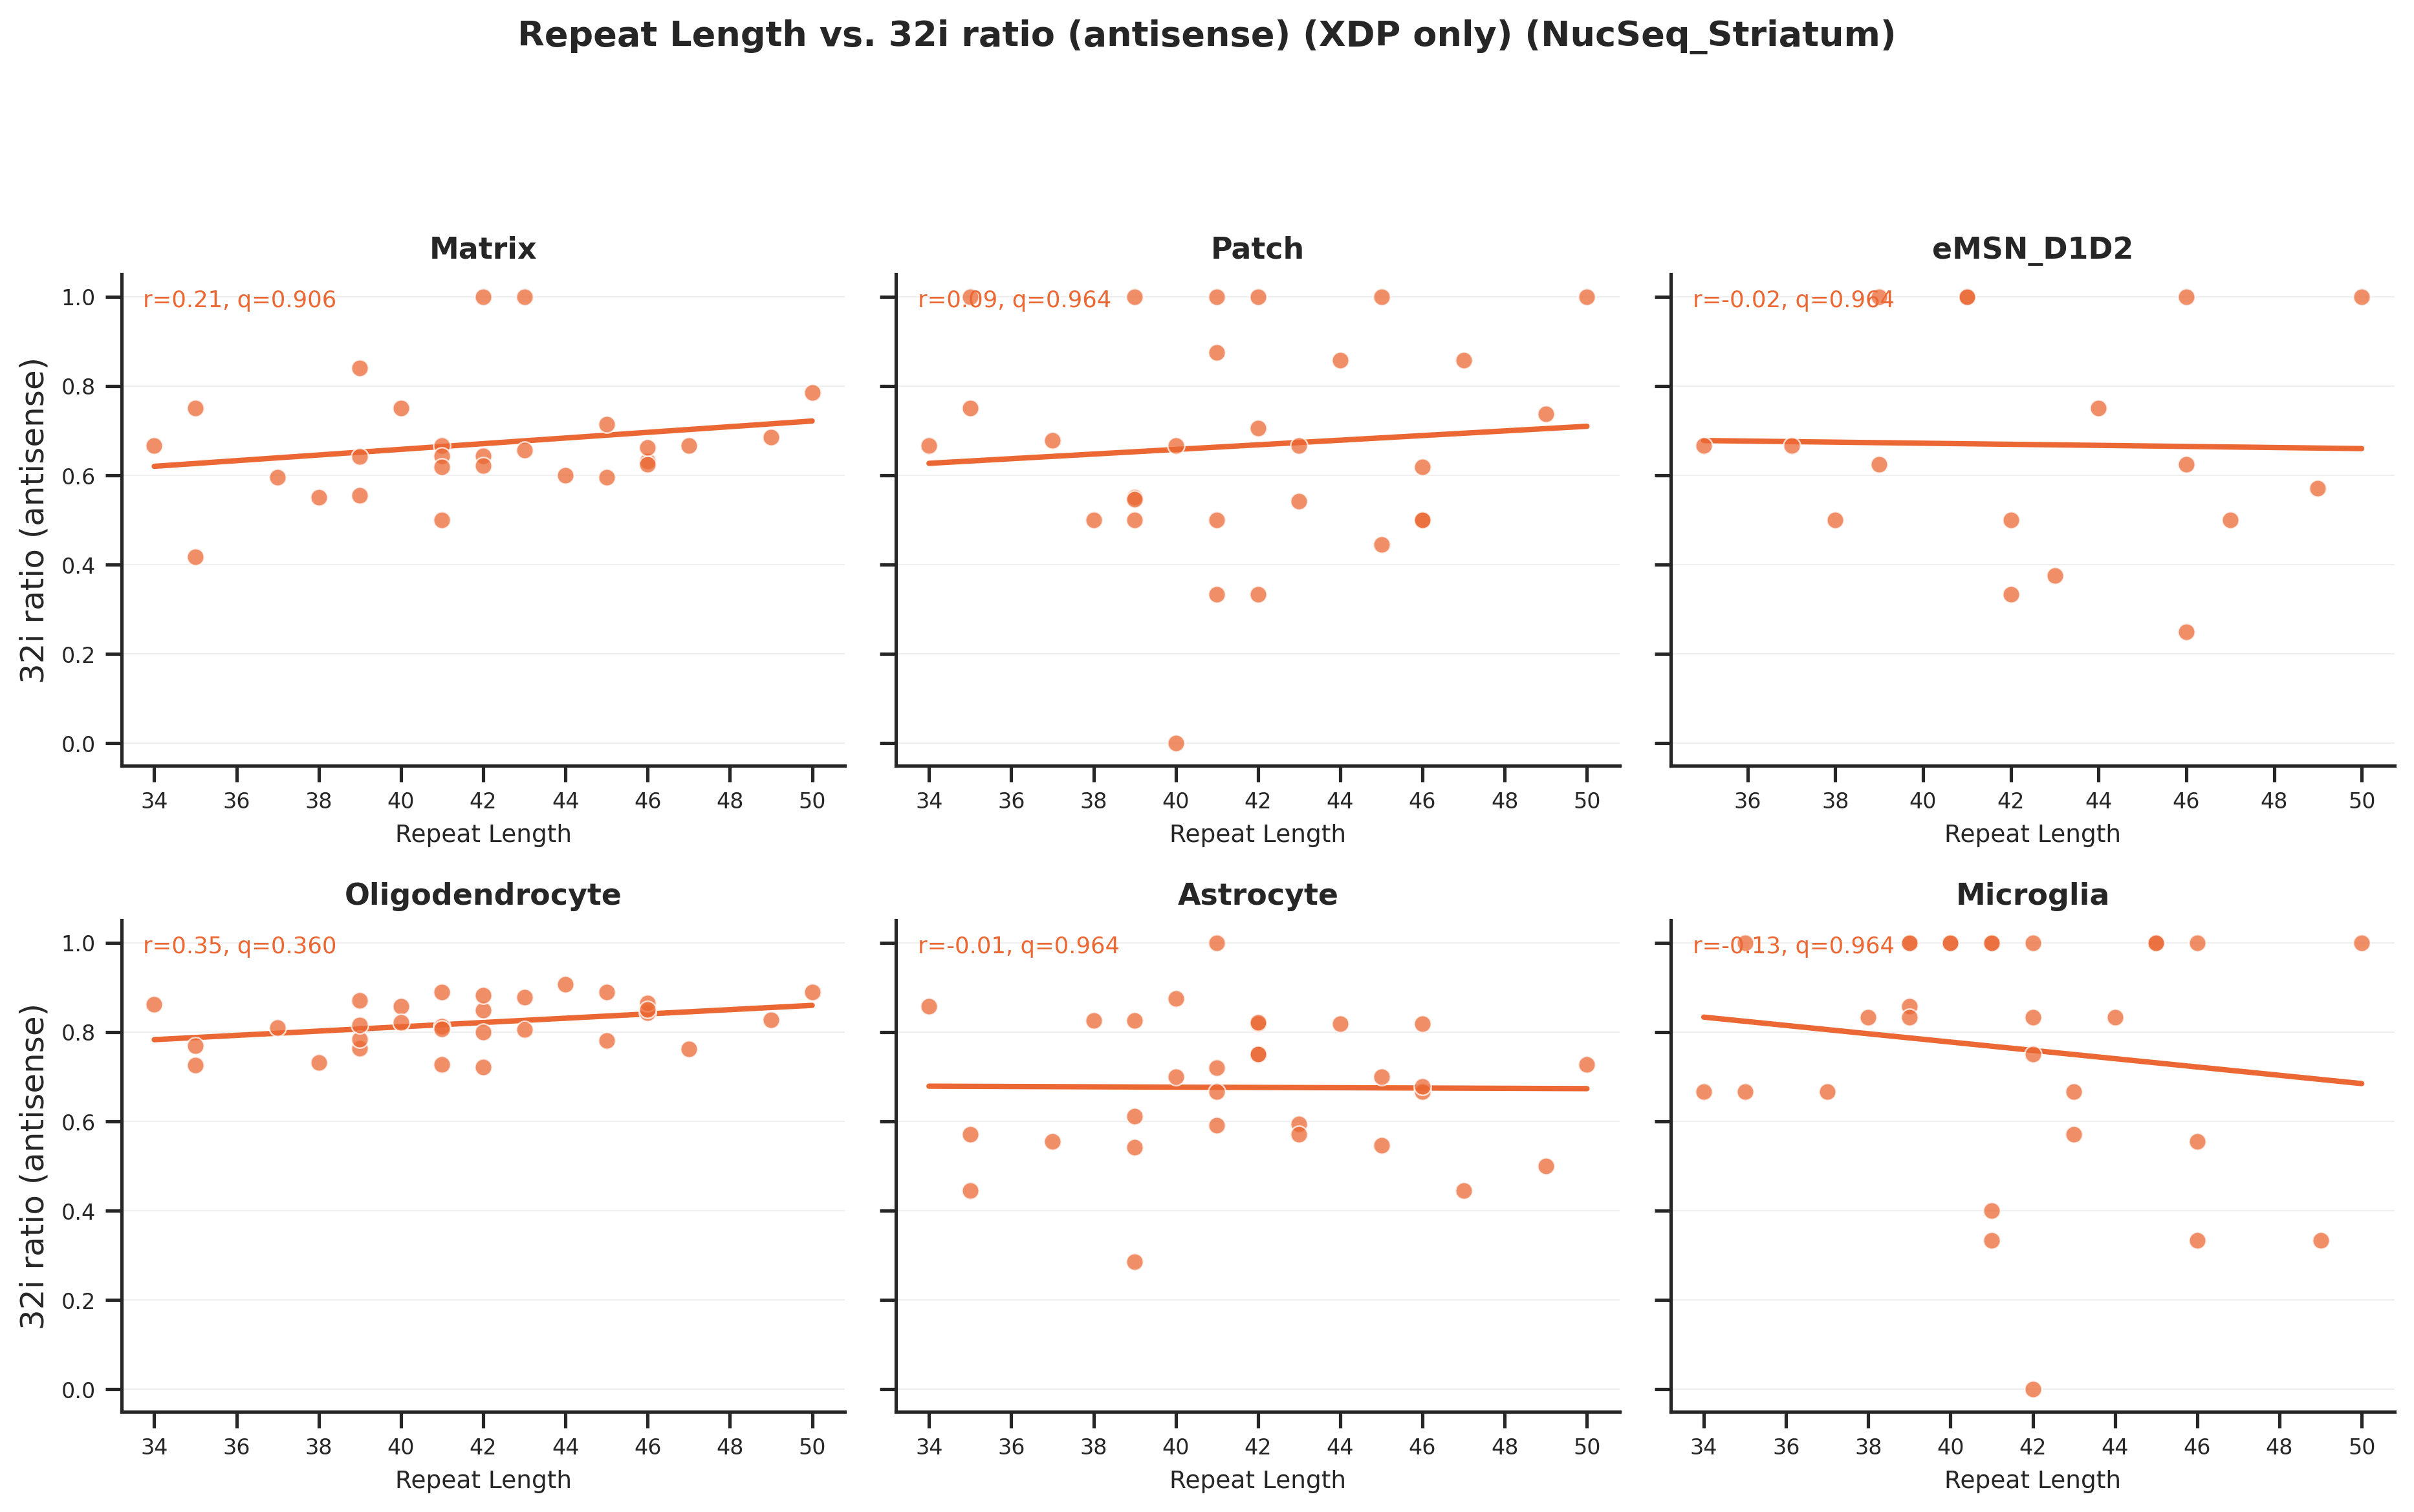

Pearson Correlation: repeat_length vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.006 | r =  0.206 | p = 3.020e-01 | q(FDR) = 9.061e-01
Patch                | XDP        | Slope =  0.005 | r =  0.085 | p = 6.605e-01 | q(FDR) = 9.636e-01
eMSN_D1D2            | XDP        | Slope = -0.001 | r = -0.020 | p = 9.384e-01 | q(FDR) = 9.636e-01
Oligodendrocyte      | XDP        | Slope =  0.005 | r =  0.347 | p = 5.999e-02 | q(FDR) = 3.600e-01
Astrocyte            | XDP        | Slope = -0.000 | r = -0.009 | p = 9.636e-01 | q(FDR) = 9.636e-01
Microglia            | XDP        | Slope = -0.009 | r = -0.133 | p = 4.904e-01 | q(FDR) = 9.636e-01

Analyzing covariate: Disease_duration


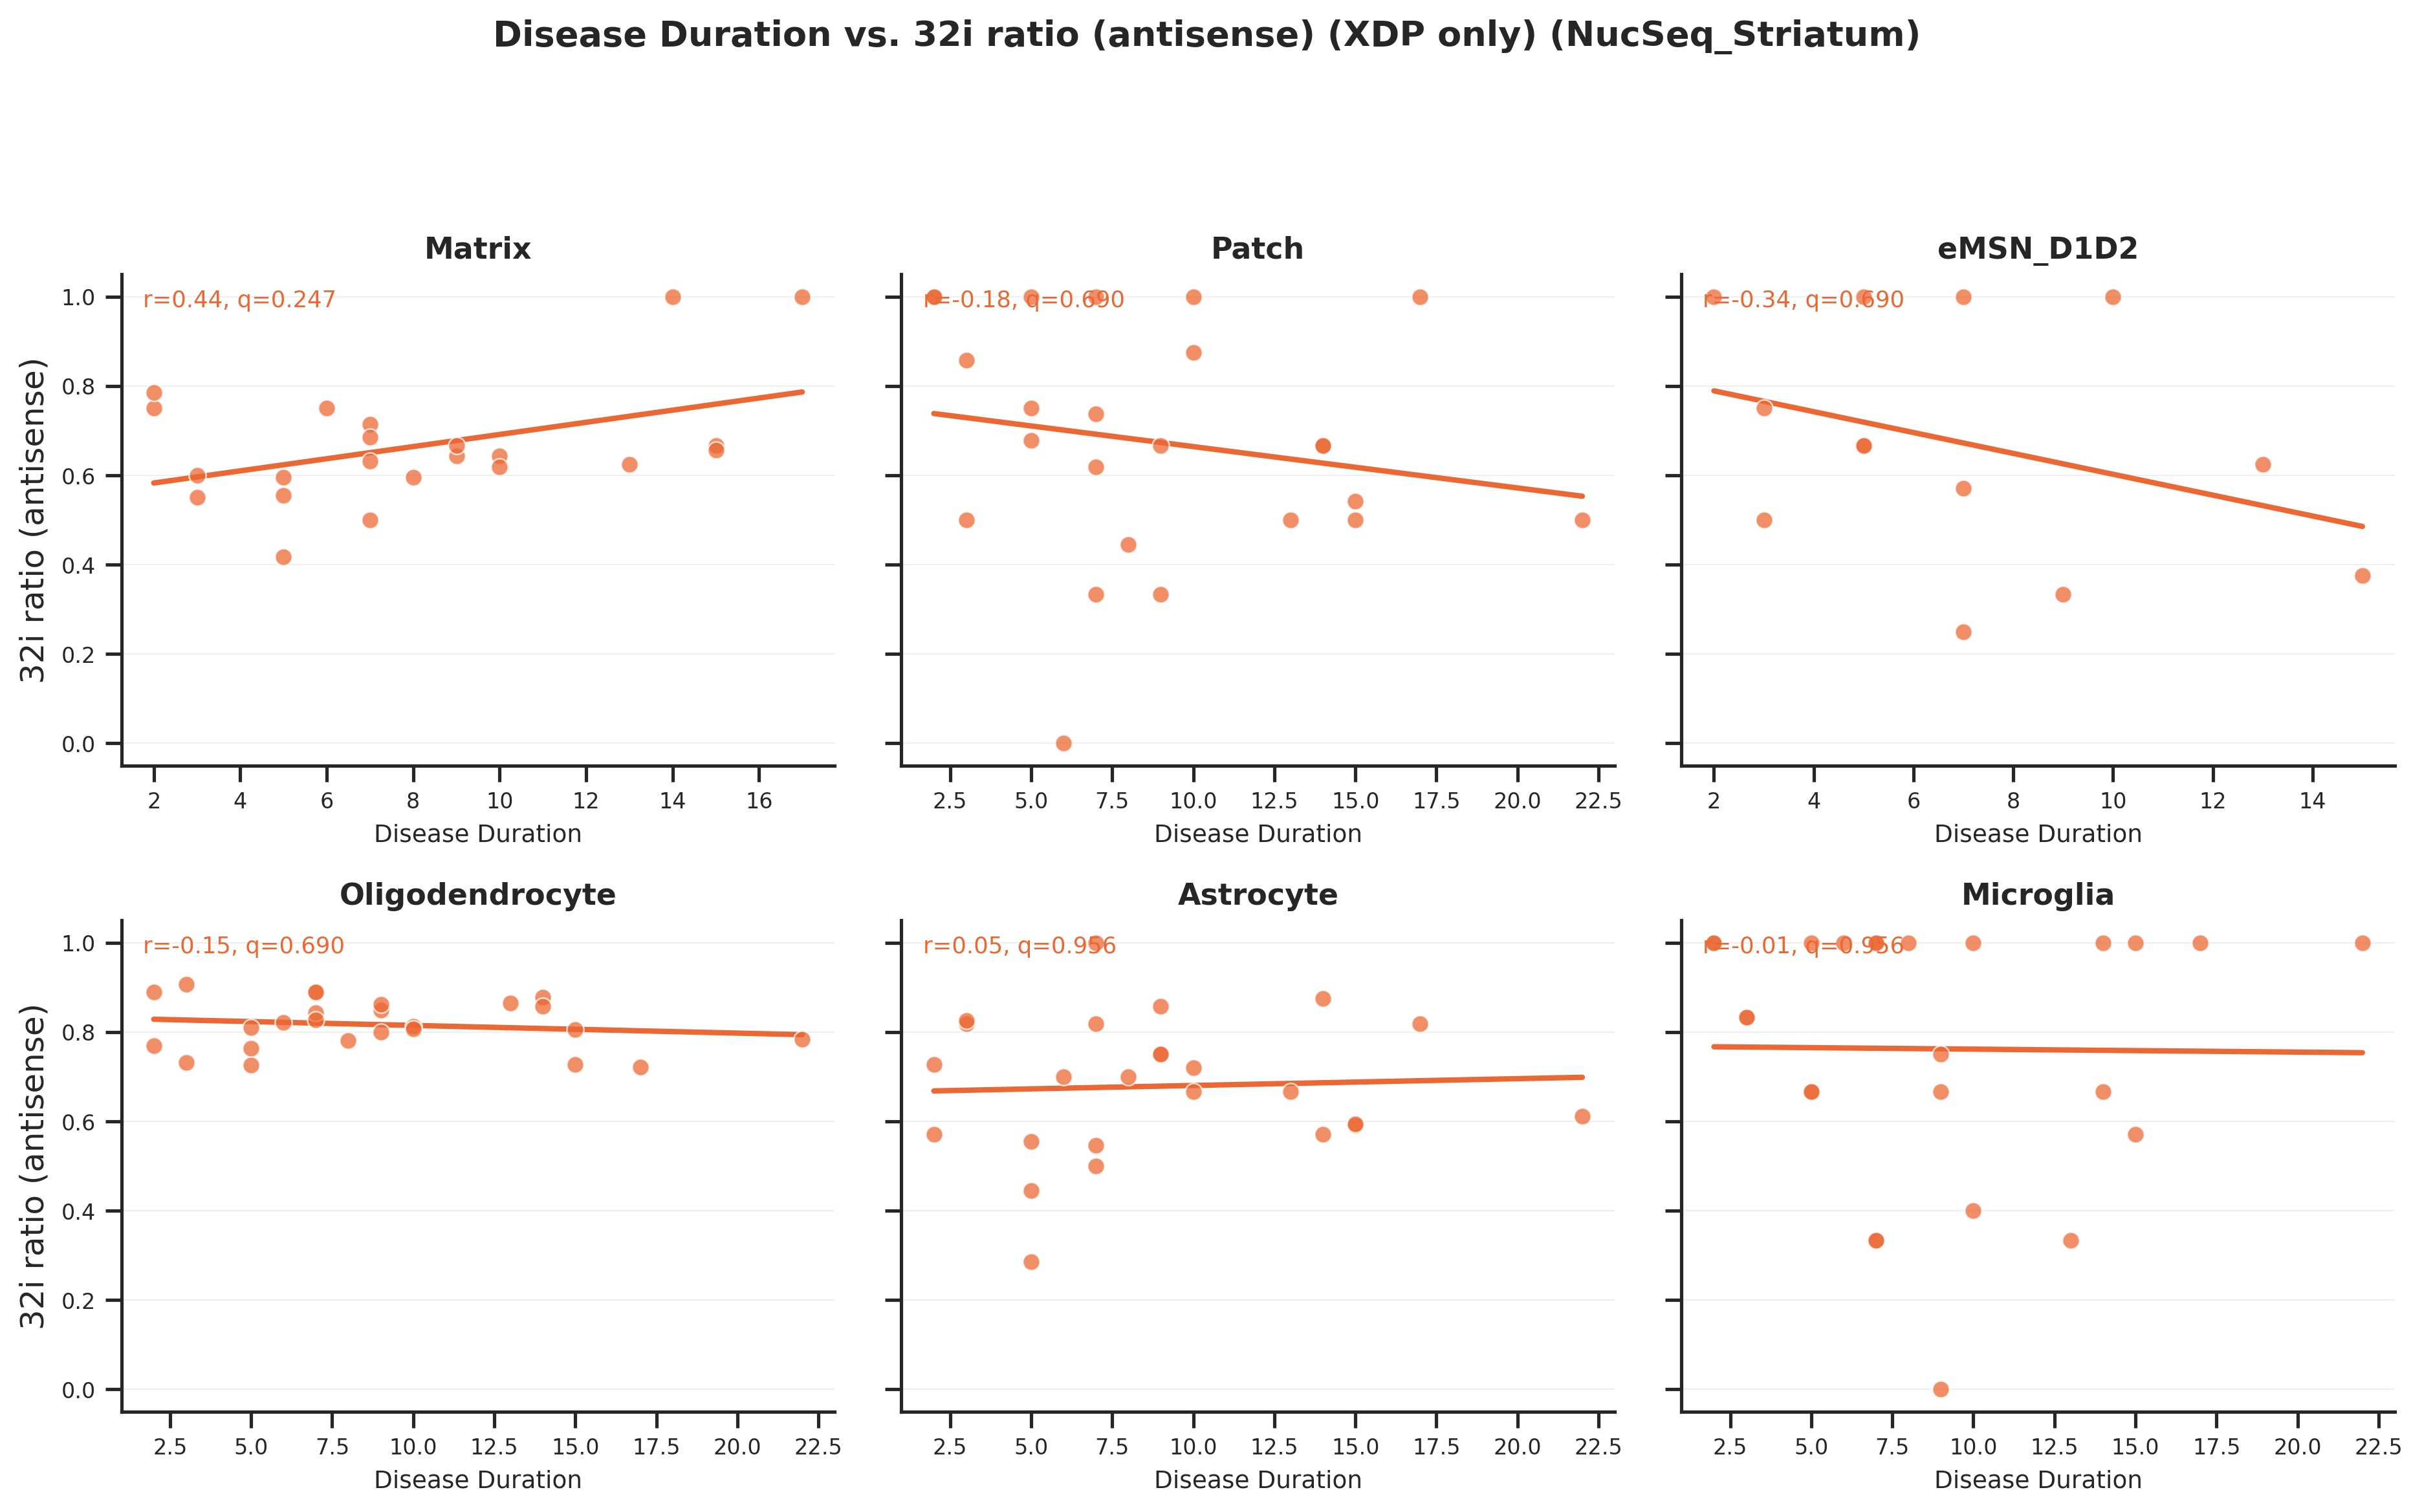

Pearson Correlation: Disease_duration vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.014 | r =  0.439 | p = 4.118e-02 | q(FDR) = 2.471e-01
Patch                | XDP        | Slope = -0.009 | r = -0.182 | p = 3.957e-01 | q(FDR) = 6.898e-01
eMSN_D1D2            | XDP        | Slope = -0.023 | r = -0.340 | p = 2.559e-01 | q(FDR) = 6.898e-01
Oligodendrocyte      | XDP        | Slope = -0.002 | r = -0.155 | p = 4.599e-01 | q(FDR) = 6.898e-01
Astrocyte            | XDP        | Slope =  0.002 | r =  0.049 | p = 8.144e-01 | q(FDR) = 9.562e-01
Microglia            | XDP        | Slope = -0.001 | r = -0.012 | p = 9.562e-01 | q(FDR) = 9.562e-01


,metric,covariate,ct_for_deg,condition,n_donors,slope,pearson_r,p,q_fdr,spearman_rho,p_spearman
25,pileup_metric_sense,Disease_duration,Patch,XDP,25,0.010215,0.517275,0.008096,0.032500,0.623920,0.000860
24,pileup_metric_sense,Disease_duration,Matrix,XDP,25,0.006667,0.500484,0.010833,0.032500,0.299404,0.145953
37,pileup_metric_antisense,Age_of_Death,Oligodendrocyte,XDP,30,-0.003136,-0.417355,0.021752,0.261028,-0.483314,0.006818
28,pileup_metric_sense,Disease_duration,Astrocyte,XDP,25,0.004461,0.429611,0.032091,0.064182,0.402554,0.046038
54,pileup_metric_antisense,Disease_duration,Matrix,XDP,22,0.013585,0.438563,0.041178,0.247066,0.273660,0.217820
27,pileup_metric_sense,Disease_duration,Oligodendrocyte,XDP,25,0.003904,0.387871,0.055386,0.083078,0.376283,0.063753
45,pileup_metric_antisense,Age_of_Onset,Oligodendrocyte,XDP,25,-0.002964,-0.384510,0.057719,0.346316,-0.426698,0.033406
51,pileup_metric_antisense,repeat_length,Oligodendrocyte,XDP,30,0.004799,0.347372,0.059994,0.359964,0.337508,0.068152
0,pileup_metric_sense,Age_of_Death,Matrix,Control,17,0.000614,0.396648,0.114951,0.664908,0.468424,0.057897
13,pileup_metric_sense,Age_of_Onset,Patch,XDP,25,-0.004142,-0.302791,0.141226,0.442868,-0.273709,0.185526


In [19]:
from scipy.stats import linregress, spearmanr
from statsmodels.stats.multitest import multipletests

cell_types = ["Matrix", "Patch", "eMSN_D1D2", "Oligodendrocyte", "Astrocyte", "Microglia"]  # swap for whatever cell type you want to analyze

sns.set_theme(style="ticks", context="notebook")


def fit_and_annotate(ax, x, y, color, label_y, res, qvalue):
    """Scatter + regression line + r/q annotation for one condition on ax.

    res/qvalue are precomputed upstream so the FDR correction can see every
    p-value for this covariate before any of them get plotted.
    """
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mask = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[mask], y[mask]

    ax.scatter(x, y, s=40, color=color, alpha=0.75, edgecolor="white", linewidth=0.6, zorder=3)

    if res is None:
        ax.text(0.03, label_y, "insufficient data", transform=ax.transAxes,
                 fontsize=8.5, color=color, va="top", style="italic")
        return

    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, res.intercept + res.slope * xs, color=color, linewidth=2, zorder=2)

    q_label = "q<0.001" if qvalue < 0.001 else f"q={qvalue:.3f}"
    ax.text(0.03, label_y, f"r={res.rvalue:.2f}, {q_label}", transform=ax.transAxes,
             fontsize=8.5, color=color, va="top", fontweight="medium")


def plot_covariate_correlations(df_cov, metric, metric_label, covariates, cell_types, n_cols=3):
    """One figure per covariate (one panel per cell type), returns the stats as a df."""

    plot_cell_types = [ct for ct in cell_types if ct != "non-MSN"]  # drop non-MSN so grid is a clean 3x2
    n_rows = -(-len(plot_cell_types) // n_cols)  # ceil division
    results = []

    for COV in covariates:

        print(f"\nAnalyzing covariate: {COV}\n{'=' * 60}")

        conditions = ["XDP"] if COV in XDP_ONLY_COVARIATES else ["Control", "XDP"]
        tmp_df = df_cov[df_cov["ct_for_deg"].isin(plot_cell_types)].copy()
        if COV in XDP_ONLY_COVARIATES:
            tmp_df = tmp_df[tmp_df["condition"] == "XDP"]

        # single pass: fit every (cell type, condition) combo once, so the FDR
        # correction below sees the full family of p-values for this covariate
        records = {}
        for ct in plot_cell_types:
            for cond in conditions:
                s = tmp_df[(tmp_df["ct_for_deg"] == ct) & (tmp_df["condition"] == cond)].dropna(subset=[COV, metric])
                x = s[COV].to_numpy(dtype=float)
                y = s[metric].to_numpy(dtype=float)
                # linregress needs >= 3 points to give a p-value (n=2 -> perfect fit)
                res = linregress(x, y) if len(x) >= 3 and len(np.unique(x)) >= 2 else None
                records[(ct, cond)] = {"x": x, "y": y, "res": res}

        valid_keys = [k for k, v in records.items() if v["res"] is not None]
        qvalues = {}
        if valid_keys:
            pvals = [records[k]["res"].pvalue for k in valid_keys]
            _, qvals, _, _ = multipletests(pvals, method="fdr_bh")
            qvalues = dict(zip(valid_keys, qvals))

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.6 * n_rows), sharey=True, dpi=300)
        axes = np.atleast_1d(axes).flatten()

        for i, ct in enumerate(plot_cell_types):
            ax = axes[i]

            label_y = 0.97
            for cond in conditions:
                rec = records[(ct, cond)]
                fit_and_annotate(ax, rec["x"], rec["y"], CONDITION_COLORS[cond], label_y,
                                  rec["res"], qvalues.get((ct, cond)))
                label_y -= 0.115

            ax.set_title(ct, fontsize=11, fontweight="semibold", pad=6)
            ax.set_xlabel(COV.replace("_", " ").title(), fontsize=9)
            ax.set_ylabel(metric_label if i % n_cols == 0 else "")
            ax.tick_params(labelsize=8)
            ax.grid(axis="y", linewidth=0.5, alpha=0.3)
            sns.despine(ax=ax)

        for j in range(len(plot_cell_types), len(axes)):
            axes[j].set_visible(False)

        if len(conditions) > 1:
            handles = [plt.Line2D([0], [0], marker="o", linestyle="-", color=CONDITION_COLORS[c],
                                    label=c, markersize=6) for c in conditions]
            fig.legend(handles=handles, loc="upper center", ncol=len(conditions),
                        bbox_to_anchor=(0.5, 1.04), frameon=False, fontsize=10)

        title_suffix = " (XDP only)" if len(conditions) == 1 else ""
        fig.suptitle(f"{COV.replace('_', ' ').title()} vs. {metric_label}{title_suffix} ({ANALYSIS_NAME})",
                      y=1.08, fontsize=13, fontweight="bold")
        fig.tight_layout()
        plt.show()

        # printed summary (same stats as annotated on the plot, for scanning many at once)
        # q = FDR-adjusted p-value (Benjamini-Hochberg), corrected across all cell
        # type x condition tests run for this covariate
        print(f"Pearson Correlation: {COV} vs. {metric_label}")
        print("-" * 75)
        for ct in plot_cell_types:
            for cond in conditions:
                rec = records[(ct, cond)]
                if rec["res"] is None:
                    print(f"{ct:<20} | {cond:<10} | skipped (n={len(rec['x'])}, unique={len(np.unique(rec['x']))})")
                    continue
                res = rec["res"]
                q = qvalues[(ct, cond)]
                print(f"{ct:<20} | {cond:<10} | Slope = {res.slope:>6.3f} | r = {res.rvalue:>6.3f} | "
                      f"p = {res.pvalue:.3e} | q(FDR) = {q:.3e}")
                rho, p_spearman = spearmanr(rec["x"], rec["y"])
                results.append({
                    "metric": metric, "covariate": COV, "ct_for_deg": ct, "condition": cond,
                    "n_donors": len(rec["x"]), "slope": res.slope, "pearson_r": res.rvalue,
                    "p": res.pvalue, "q_fdr": q, "spearman_rho": rho, "p_spearman": p_spearman,
                })

    return pd.DataFrame(results)


df_cov_results = pd.concat(
    [plot_covariate_correlations(df_cov, metric, metric_label, covariate_per_cell_type, cell_types)
     for metric, metric_label in METRICS.items()],
    ignore_index=True,
)
df_cov_results.to_csv(OUT_DIR / f"32i_vs_covariates_{ANALYSIS_NAME}.csv", index=False)
df_cov_results.sort_values("p")

# Ratio corr taf1 expression
TAF1 raw UMIs are read from `layers/counts` (CSR) in row chunks with h5py, without loading the matrix

In [20]:
def read_gene_counts_h5(h5ad_path, gene_col, layer="layers/counts", chunk=100_000):
    # one column of a CSR matrix stored in the h5ad, without loading the matrix
    with h5py.File(h5ad_path, "r") as f:
        g = f[layer]
        indptr = g["indptr"][:]
        n_rows = len(indptr) - 1
        out = np.zeros(n_rows, dtype=np.int64)
        for start in range(0, n_rows, chunk):
            end = min(start + chunk, n_rows)
            lo, hi = indptr[start], indptr[end]
            hit = np.flatnonzero(g["indices"][lo:hi] == gene_col)
            if hit.size == 0:
                continue
            # row of each nonzero = position in indptr
            rows = np.searchsorted(indptr[start:end + 1], lo + hit, side="right") - 1 + start
            out[rows] = g["data"][lo:hi][hit]
    return out

taf1_col = var_nuc.index.get_loc(var_nuc.index[var_nuc["gene_symbol"] == "TAF1"][0])
taf1_all = read_gene_counts_h5(ADATA_PATH, taf1_col)
obs_nuc["taf1_total_umis"] = taf1_all[obs_nuc["obs_idx"].to_numpy()]
display(obs_nuc[["donor_id", "ct_for_deg", "taf1_total_umis"]].head())

,donor_id,ct_for_deg,taf1_total_umis
barcode,,,
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGACGTTCATGTGGT-1_Striatum_SCF-20-025,SCF-20-025,-Low_quality,3
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GTAGGCCTCCGTTGTC-1_Striatum_SCF-20-025,SCF-20-025,Astrocyte,1
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__TCGGGACTCTCTGTCG-1_Striatum_SCF-22-054CM,SCF-22-054,Astrocyte,1
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGGTCACAAGAGGCT-1_Striatum_SCF-19-009,SCF-19-009,Astrocyte,3
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GGACATTGTAAACCTC-1_Striatum_SCF-22-054CM,SCF-22-054,Astrocyte,2


,donor_id,ct_for_deg,taf1_total_umis,pileup_metric_sense,pileup_metric_antisense
0,PCMC-16-011,Astrocyte,0.521262,0.365385,0.571429
1,PCMC-16-011,Matrix,1.051643,0.463918,0.750000
2,PCMC-16-011,Microglia,0.440000,0.833333,1.000000
3,PCMC-16-011,OPC,0.406250,0.608696,NaN
4,PCMC-16-011,Oligodendrocyte,0.335714,0.489362,0.769231



32i ratio (sense)
Matrix: n=47, rho=0.00, p=0.979
Patch: n=47, rho=-0.00, p=0.986
eMSN_D1D2: n=47, rho=0.01, p=0.947
eMSN_NUDAP: n=46, rho=-0.02, p=0.903
non-MSN: n=47, rho=0.03, p=0.861
Oligodendrocyte: n=47, rho=-0.04, p=0.800
OPC: n=47, rho=-0.07, p=0.642
Astrocyte: n=47, rho=-0.07, p=0.653
Microglia: n=47, rho=0.01, p=0.962


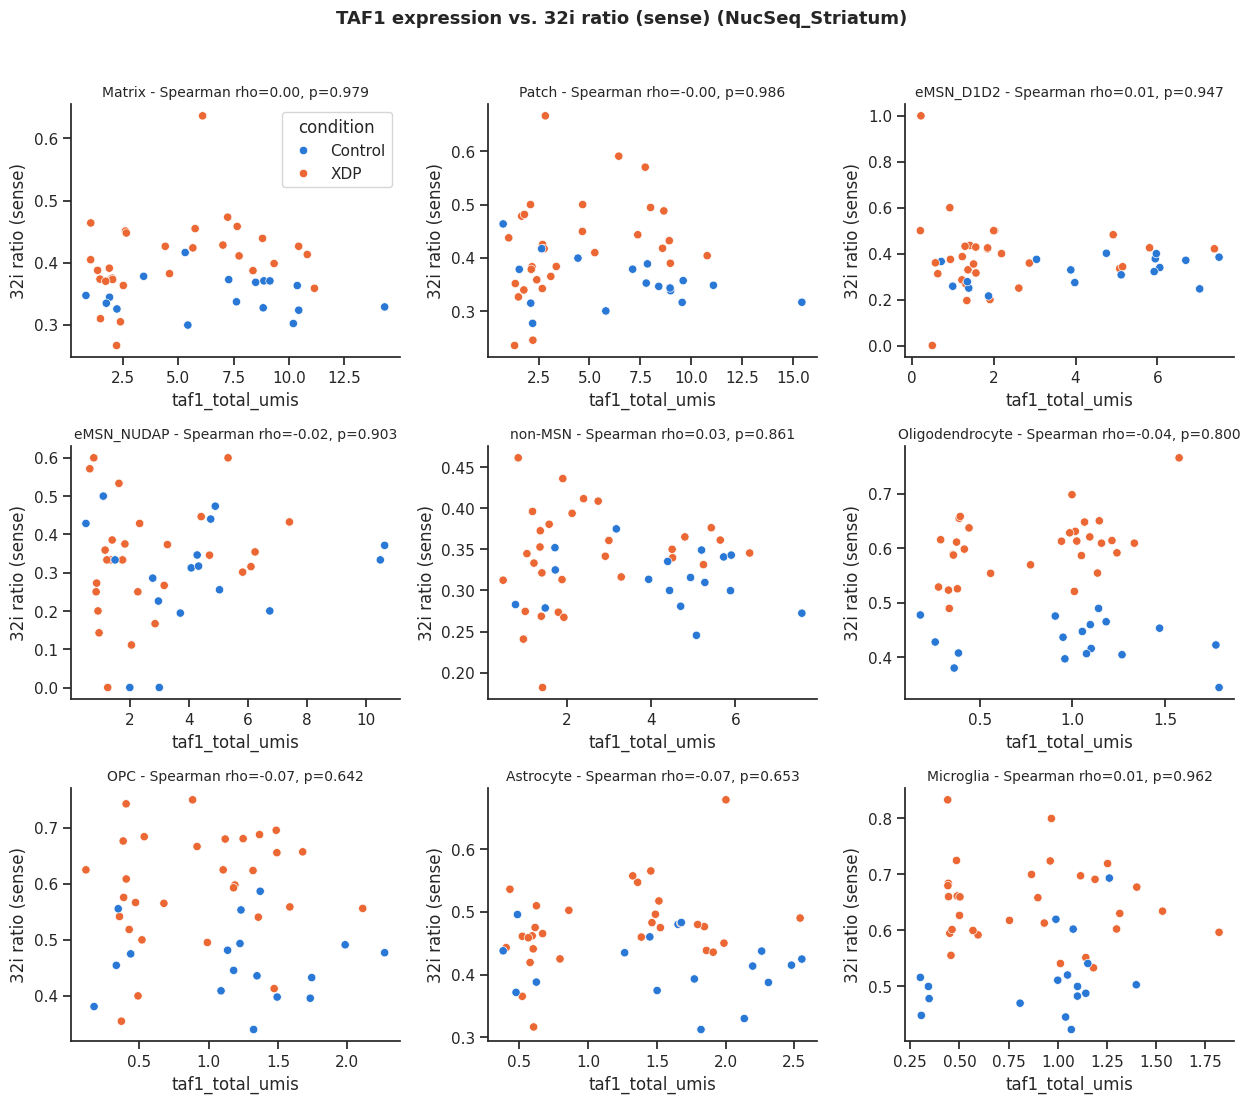


32i ratio (antisense)
Matrix: n=44, rho=-0.18, p=0.248
Patch: n=46, rho=-0.03, p=0.824
eMSN_D1D2: n=34, rho=-0.21, p=0.243
eMSN_NUDAP: n=27, rho=0.02, p=0.907
non-MSN: n=45, rho=0.00, p=0.982
Oligodendrocyte: n=47, rho=-0.32, p=0.026
OPC: n=43, rho=0.15, p=0.349
Astrocyte: n=47, rho=-0.25, p=0.088
Microglia: n=44, rho=-0.38, p=0.011


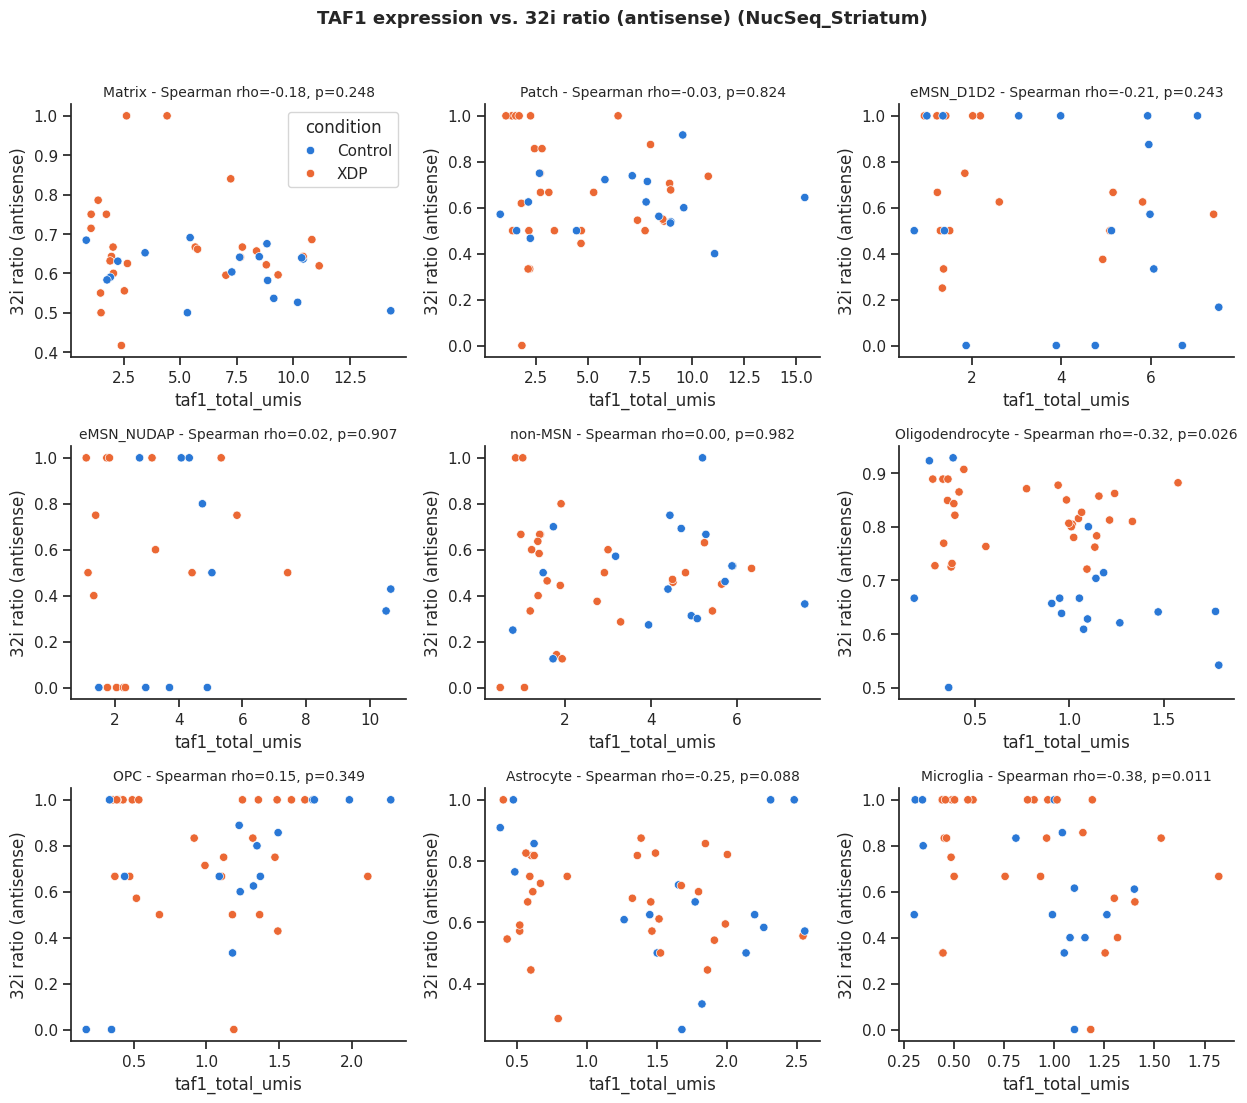

In [21]:
from scipy.stats import spearmanr

# checj if taf1 expression correlates with the pileup metric
cell_types = ["Matrix", "Patch", "eMSN_D1D2", "eMSN_NUDAP", "non-MSN", "Oligodendrocyte", "OPC", "Astrocyte", "Microglia"]

donor_taf1 = obs_nuc.groupby(["donor_id", "ct_for_deg"], observed=True)["taf1_total_umis"].mean().reset_index()
donor_taf1["ct_for_deg"] = donor_taf1["ct_for_deg"].astype(str)
df_taf1 = df_pseudobulk_all.merge(donor_taf1, on=["donor_id", "ct_for_deg"], how="left")
display(df_taf1[["donor_id", "ct_for_deg", "taf1_total_umis", *METRICS]].head())


def plot_taf1_correlation(df_taf1, metric, metric_label, cell_types, n_cols=3):
    # Spearman is rank based -> same rho/p as with the window-normalized version of the metric
    n_rows = -(-len(cell_types) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.6 * n_rows))
    axes = axes.flatten()
    for ax, ct in zip(axes, cell_types):
        sub = df_taf1.loc[df_taf1["ct_for_deg"] == ct, ["taf1_total_umis", metric, "condition", "donor_id"]].dropna()
        rho, pval = spearmanr(sub["taf1_total_umis"], sub[metric])
        sns.scatterplot(data=sub, x="taf1_total_umis", y=metric, hue="condition",
                        palette=CONDITION_COLORS, hue_order=["Control", "XDP"], ax=ax, legend=ax is axes[0])
        ax.set_title(f"{ct} - Spearman rho={rho:.2f}, p={pval:.3f}", fontsize=10)
        ax.set_ylabel(metric_label)
        sns.despine(ax=ax)
        print(f"{ct}: n={len(sub)}, rho={rho:.2f}, p={pval:.3f}")
    for ax in axes[len(cell_types):]:
        ax.set_visible(False)
    fig.suptitle(f"TAF1 expression vs. {metric_label} ({ANALYSIS_NAME})", fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout()
    plt.show()


for metric, metric_label in METRICS.items():
    print(f"\n{metric_label}\n{'=' * 60}")
    plot_taf1_correlation(df_taf1, metric, metric_label, cell_types)